In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# ===== Cell 1: Libraries & settings =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

import sklearn

In [3]:
import pandas as pd

file_path = '/content/drive/MyDrive/Depi/Technical/urbanmind_features_h3_clean.csv'

df = pd.read_csv(file_path)
print(df.shape)
df.head(10)

(3489, 175)


,h3_index,population_population_worldpop_2026,population_population_density_worldpop_2026,population_area_km2,population_cell_full_area_km2,population_cairo_intersection_ratio,population_latitude,population_longitude,population_reference_year,population_source,population_source_version,population_source_dataset,population_spatial_resolution_m,population_analytical_grid,population_crs,population_population_type,population_is_observed,population_is_estimated,population_quality_flag,population_production_date,population_doi,population_source_url,roads_latitude,roads_longitude,roads_area_km2,...,green_space_ndvi_median_summer_2026,green_space_ndvi_p90_summer_2026,green_space_ndvi_min_summer_2026,green_space_vegetated_fraction_summer_2026,green_space_ndvi_mean_annual_2026,green_space_ndvi_median_annual_2026,green_space_ndvi_p90_annual_2026,green_space_ndvi_min_annual_2026,green_space_vegetated_fraction_annual_2026,green_space_observation_count_2026,green_space_valid_pixel_fraction,green_space_vegetation_persistence_ratio,green_space_total_green_space_area_m2,green_space_public_green_space_area_m2,green_space_private_restricted_green_space_area_m2,green_space_agricultural_area_m2,green_space_natural_reserve_area_m2,green_space_number_of_public_parks,green_space_total_green_space_fraction,green_space_public_green_space_fraction,green_space_has_public_green_space,green_space_is_observed,green_space_is_derived,green_space_data_status,green_space_quality_flag
0,883e604925fffff,292.0810,3291.04,0.088750,0.866456,0.1024,30.197407,31.413703,2026.0,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.197407,31.413703,0.088750,...,0.0970,0.3343,0.0213,0.2400,0.1459,0.0960,0.3445,0.0170,0.2333,4.0,0.9725,1.0104,0.00,0.0,0.0,0.00,0.0,0.0,0.0000,0.0,False,True,True,FINAL,HIGH_CONFIDENCE
1,883e604927fffff,1305.1258,2806.28,0.465074,0.866414,0.5368,30.193526,31.423081,2026.0,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.193526,31.423081,0.465074,...,0.0589,0.0859,0.0006,0.0260,0.0663,0.0590,0.0837,-0.0055,0.0249,4.0,0.9996,0.9983,0.00,0.0,0.0,0.00,0.0,0.0,0.0000,0.0,False,True,True,FINAL,HIGH_CONFIDENCE
2,883e604933fffff,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.196003,31.458865,0.024206,...,0.0656,0.2269,-0.0125,0.1223,0.0996,0.0670,0.2174,-0.0117,0.1158,4.0,1.0000,0.9791,0.00,0.0,0.0,0.00,0.0,0.0,0.0000,0.0,False,True,True,FINAL,HIGH_CONFIDENCE
3,883e604935fffff,203.3366,3299.90,0.061619,0.866321,0.0711,30.194766,31.440973,2026.0,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.194766,31.440973,0.061619,...,0.0514,0.0860,-0.0260,0.0030,0.0556,0.0529,0.0870,-0.0128,0.0022,4.0,0.9992,0.9716,0.00,0.0,0.0,0.00,0.0,0.0,0.0000,0.0,False,True,True,FINAL,HIGH_CONFIDENCE
4,883e604937fffff,1587.0929,3129.58,0.507126,0.866278,0.5854,30.190884,31.450349,2026.0,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.190884,31.450349,0.507126,...,0.0503,0.0982,-0.0335,0.0086,0.0601,0.0516,0.1001,-0.0110,0.0080,4.0,1.0000,0.9748,0.00,0.0,0.0,0.00,0.0,0.0,0.0000,0.0,False,True,True,FINAL,HIGH_CONFIDENCE
5,883e604981fffff,165.1273,494.07,0.334218,0.865998,0.3859,30.194585,31.504017,2026.0,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.194585,31.504017,0.334218,...,0.2146,0.3224,0.0120,0.5678,0.2120,0.2124,0.3167,-0.0056,0.5561,4.0,1.0000,1.0104,216750

In [6]:
print("Dataset Shape:", df.shape)


Dataset Shape: (3489, 175)


In [7]:
display(df.head())

,h3_index,population_population_worldpop_2026,population_population_density_worldpop_2026,population_area_km2,population_cell_full_area_km2,population_cairo_intersection_ratio,population_latitude,population_longitude,population_reference_year,population_source,population_source_version,population_source_dataset,population_spatial_resolution_m,population_analytical_grid,population_crs,population_population_type,population_is_observed,population_is_estimated,population_quality_flag,population_production_date,population_doi,population_source_url,roads_latitude,roads_longitude,roads_area_km2,...,green_space_ndvi_median_summer_2026,green_space_ndvi_p90_summer_2026,green_space_ndvi_min_summer_2026,green_space_vegetated_fraction_summer_2026,green_space_ndvi_mean_annual_2026,green_space_ndvi_median_annual_2026,green_space_ndvi_p90_annual_2026,green_space_ndvi_min_annual_2026,green_space_vegetated_fraction_annual_2026,green_space_observation_count_2026,green_space_valid_pixel_fraction,green_space_vegetation_persistence_ratio,green_space_total_green_space_area_m2,green_space_public_green_space_area_m2,green_space_private_restricted_green_space_area_m2,green_space_agricultural_area_m2,green_space_natural_reserve_area_m2,green_space_number_of_public_parks,green_space_total_green_space_fraction,green_space_public_green_space_fraction,green_space_has_public_green_space,green_space_is_observed,green_space_is_derived,green_space_data_status,green_space_quality_flag
0,883e604925fffff,292.0810,3291.04,0.088750,0.866456,0.1024,30.197407,31.413703,2026.0,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.197407,31.413703,0.088750,...,0.0970,0.3343,0.0213,0.2400,0.1459,0.0960,0.3445,0.0170,0.2333,4.0,0.9725,1.0104,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False,True,True,FINAL,HIGH_CONFIDENCE
1,883e604927fffff,1305.1258,2806.28,0.465074,0.866414,0.5368,30.193526,31.423081,2026.0,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.193526,31.423081,0.465074,...,0.0589,0.0859,0.0006,0.0260,0.0663,0.0590,0.0837,-0.0055,0.0249,4.0,0.9996,0.9983,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False,True,True,FINAL,HIGH_CONFIDENCE
2,883e604933fffff,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.196003,31.458865,0.024206,...,0.0656,0.2269,-0.0125,0.1223,0.0996,0.0670,0.2174,-0.0117,0.1158,4.0,1.0000,0.9791,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False,True,True,FINAL,HIGH_CONFIDENCE
3,883e604935fffff,203.3366,3299.90,0.061619,0.866321,0.0711,30.194766,31.440973,2026.0,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.194766,31.440973,0.061619,...,0.0514,0.0860,-0.0260,0.0030,0.0556,0.0529,0.0870,-0.0128,0.0022,4.0,0.9992,0.9716,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False,True,True,FINAL,HIGH_CONFIDENCE
4,883e604937fffff,1587.0929,3129.58,0.507126,0.866278,0.5854,30.190884,31.450349,2026.0,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.190884,31.450349,0.507126,...,0.0503,0.0982,-0.0335,0.0086,0.0601,0.0516,0.1001,-0.0110,0.0080,4.0,1.0000,0.9748,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,False,True,True,FINAL,HIGH_CONFIDENCE


In [8]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['h3_index', 'population_population_worldpop_2026', 'population_population_density_worldpop_2026', 'population_area_km2', 'population_cell_full_area_km2', 'population_cairo_intersection_ratio', 'population_latitude', 'population_longitude', 'population_reference_year', 'population_source', 'population_source_version', 'population_source_dataset', 'population_spatial_resolution_m', 'population_analytical_grid', 'population_crs', 'population_population_type', 'population_is_observed', 'population_is_estimated', 'population_quality_flag', 'population_production_date', 'population_doi', 'population_source_url', 'roads_latitude', 'roads_longitude', 'roads_area_km2', 'roads_road_length_km', 'roads_road_density_km_per_km2', 'roads_motorway_length_km', 'roads_trunk_length_km', 'roads_primary_road_length_km', 'roads_secondary_road_length_km', 'roads_tertiary_road_length_km', 'roads_residential_road_length_km', 'roads_service_road_length_km', 'roads_other_road_length_km', 'roads_o

In [9]:
print("\nData Types:")
print(df.dtypes)


Data Types:
h3_index                                        object
population_population_worldpop_2026            float64
population_population_density_worldpop_2026    float64
population_area_km2                            float64
population_cell_full_area_km2                  float64
                                                ...   
green_space_has_public_green_space              object
green_space_is_observed                         object
green_space_is_derived                          object
green_space_data_status                         object
green_space_quality_flag                        object
Length: 175, dtype: object


In [10]:

# Cell 2: Data Quality and Target Inspection

# 1. فحص تكرار المناطق
print("=== H3 Index Check ===")
print("Total rows:", len(df))
print("Missing H3 indexes:", df["h3_index"].isna().sum())
print("Duplicated H3 indexes:", df["h3_index"].duplicated().sum())


=== H3 Index Check ===
Total rows: 3489
Missing H3 indexes: 0
Duplicated H3 indexes: 0


In [11]:

# 2. تحديد الـ Targets الثلاثة
target_1 = "traffic_structural_susceptibility_class"
target_2 = "traffic_demand_capacity_pressure_class"

targets = [target_1, target_2]

# 3. فحص توزيع الفئات والقيم المفقودة
for target in targets:
    print(f"\n{'=' * 50}")
    print(f"Target: {target}")
    print("Missing values:", df[target].isna().sum())
    print("Unique values:", df[target].nunique(dropna=True))
    print("\nClass distribution (count):")
    print(df[target].value_counts(dropna=False))
    print("\nClass distribution (percentage):")
    print(
        (df[target].value_counts(normalize=True, dropna=False) * 100)
        .round(2)
    )



Target: traffic_structural_susceptibility_class
Missing values: 1
Unique values: 3

Class distribution (count):
traffic_structural_susceptibility_class
LOW_STRUCTURAL_SUSCEPTIBILITY         1263
HIGH_STRUCTURAL_SUSCEPTIBILITY        1151
MODERATE_STRUCTURAL_SUSCEPTIBILITY    1074
NaN                                      1
Name: count, dtype: int64

Class distribution (percentage):
traffic_structural_susceptibility_class
LOW_STRUCTURAL_SUSCEPTIBILITY         36.20
HIGH_STRUCTURAL_SUSCEPTIBILITY        32.99
MODERATE_STRUCTURAL_SUSCEPTIBILITY    30.78
NaN                                    0.03
Name: proportion, dtype: float64

Target: traffic_demand_capacity_pressure_class
Missing values: 3463
Unique values: 3

Class distribution (count):
traffic_demand_capacity_pressure_class
NaN                                  3463
HIGH_DEMAND_CAPACITY_PRESSURE           9
LOW_DEMAND_CAPACITY_PRESSURE            9
MODERATE_DEMAND_CAPACITY_PRESSURE       8
Name: count, dtype: int64

Class distributio

In [12]:

# 4. فحص الأعمدة الأكثر احتواءً على قيم مفقودة
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": df.isna().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Percentage", ascending=False)

print("\n=== Top 25 Columns with Missing Values ===")
display(missing_summary.head(25).round(2))





=== Top 25 Columns with Missing Values ===


,Missing_Count,Missing_Percentage
roads_avg_maxspeed,3470,99.46
traffic_avg_maxspeed,3470,99.46
traffic_demand_capacity_pressure_index,3463,99.25
traffic_population_per_lane_km,3463,99.25
traffic_population_per_lane_km_norm,3463,99.25
traffic_demand_capacity_pressure_class,3463,99.25
traffic_avg_lanes,3442,98.65
roads_avg_lanes,3442,98.65
transit_transit_modes_available,3051,87.45
traffic_lane_km_per_km2,2281,65.38


In [13]:
# 5. ملخص عام
print("\n=== Overall Data Quality ===")
print("Total missing cells:", df.isna().sum().sum())
print("Total missing percentage:",
      round(df.isna().mean().mean() * 100, 2), "%")


=== Overall Data Quality ===
Total missing cells: 57956
Total missing percentage: 9.49 %


In [14]:

# Cell 3: Investigating Target Construction and Leakage

# الأعمدة المرتبطة مباشرة بالـ Targets
inspection_cols = [
    "traffic_structural_susceptibility_class",
    "traffic_structural_network_friction_index",
    "traffic_structural_index_available",
    "traffic_demand_capacity_pressure_class",
    "traffic_demand_capacity_pressure_index",
    "traffic_demand_capacity_index_available",
    "traffic_combined_index_available",
    "traffic_index_coverage_flag",
    "traffic_quality_flag",
    "traffic_population_per_lane_km",
    "traffic_population_per_lane_km_norm"
]

inspection_cols = [
    col for col in inspection_cols if col in df.columns
]

print("=== Target and Index Availability ===")
display(
    df[inspection_cols].isna().sum().to_frame("Missing_Count")
    .assign(
        Non_Missing_Count=lambda x: len(df) - x["Missing_Count"]
    )
)

# 1. توزيع الـ Structural Target حسب حالة توفر المؤشر
print("\n=== Structural Target vs Index Availability ===")

if "traffic_structural_index_available" in df.columns:
    display(pd.crosstab(
        df["traffic_structural_index_available"],
        df["traffic_structural_susceptibility_class"],
        margins=True,
        dropna=False
    ))


=== Target and Index Availability ===


,Missing_Count,Non_Missing_Count
traffic_structural_susceptibility_class,1,3488
traffic_structural_network_friction_index,1,3488
traffic_structural_index_available,1,3488
traffic_demand_capacity_pressure_class,3463,26
traffic_demand_capacity_pressure_index,3463,26
traffic_demand_capacity_index_available,1,3488
traffic_combined_index_available,1,3488
traffic_index_coverage_flag,1,3488
traffic_quality_flag,1,3488
traffic_population_per_lane_km,3463,26



=== Structural Target vs Index Availability ===


traffic_structural_susceptibility_class,HIGH_STRUCTURAL_SUSCEPTIBILITY,LOW_STRUCTURAL_SUSCEPTIBILITY,MODERATE_STRUCTURAL_SUSCEPTIBILITY,NaN,All
traffic_structural_index_available,,,,,
True,1151,1263,1074,0,3488.0
NaN,0,0,0,1,NaN
All,1151,1263,1074,0,3489.0


In [15]:

# 2. فحص المؤشر الرقمي داخل كل فئة Structural
print("\n=== Structural Index by Target Class ===")

if "traffic_structural_network_friction_index" in df.columns:
    display(
        df.groupby(
            "traffic_structural_susceptibility_class",
            dropna=False
        )["traffic_structural_network_friction_index"]
        .agg(["count", "min", "median", "mean", "max"])
        .round(4)
    )



=== Structural Index by Target Class ===


,count,min,median,mean,max
traffic_structural_susceptibility_class,,,,,
HIGH_STRUCTURAL_SUSCEPTIBILITY,1151,0.2128,0.2992,0.3267,0.7299
LOW_STRUCTURAL_SUSCEPTIBILITY,1263,0.0000,0.0000,0.0000,0.0000
MODERATE_STRUCTURAL_SUSCEPTIBILITY,1074,0.0007,0.1956,0.1686,0.2128
NaN,0,NaN,NaN,NaN,NaN


In [16]:

# 3. توزيع الـ Traffic Pressure حسب توفر المؤشر
print("\n=== Pressure Target vs Index Availability ===")

if "traffic_demand_capacity_index_available" in df.columns:
    display(pd.crosstab(
        df["traffic_demand_capacity_index_available"],
        df["traffic_demand_capacity_pressure_class"],
        margins=True,
        dropna=False
    ))



=== Pressure Target vs Index Availability ===


traffic_demand_capacity_pressure_class,HIGH_DEMAND_CAPACITY_PRESSURE,LOW_DEMAND_CAPACITY_PRESSURE,MODERATE_DEMAND_CAPACITY_PRESSURE,NaN,All
traffic_demand_capacity_index_available,,,,,
False,0,0,0,3462,3462.0
NaN,0,0,0,1,NaN
True,9,9,8,0,26.0
All,9,9,8,0,3489.0


In [17]:

# 4. فحص المؤشر الرقمي داخل كل فئة Pressure
print("\n=== Pressure Index by Target Class ===")

if "traffic_demand_capacity_pressure_index" in df.columns:
    display(
        df.groupby(
            "traffic_demand_capacity_pressure_class",
            dropna=False
        )["traffic_demand_capacity_pressure_index"]
        .agg(["count", "min", "median", "mean", "max"])
        .round(4)
    )




=== Pressure Index by Target Class ===


,count,min,median,mean,max
traffic_demand_capacity_pressure_class,,,,,
HIGH_DEMAND_CAPACITY_PRESSURE,9,0.2019,0.5035,0.5880,1.0000
LOW_DEMAND_CAPACITY_PRESSURE,9,0.0000,0.0000,0.0000,0.0002
MODERATE_DEMAND_CAPACITY_PRESSURE,8,0.0002,0.0279,0.0311,0.0642
NaN,0,NaN,NaN,NaN,NaN


In [18]:
# 5. فحص الـ Targets بالنسبة لمؤشرات الجودة والتغطية
for col in ["traffic_index_coverage_flag", "traffic_quality_flag"]:
    if col in df.columns:
        print(f"\n=== {col} ===")
        display(df[col].value_counts(dropna=False))

# 6. معاينة الصفوف التي لديها Pressure Target فقط
print("\n=== Rows with a Valid Pressure Target ===")

pressure_target = "traffic_demand_capacity_pressure_class"

display(
    df.loc[df[pressure_target].notna(), inspection_cols]
    .head(30)
)



=== traffic_index_coverage_flag ===


,count
traffic_index_coverage_flag,
STRUCTURAL_ONLY,3462
FULL_STRUCTURAL_AND_DEMAND,26
NaN,1



=== traffic_quality_flag ===


,count
traffic_quality_flag,
VALID,3488
NaN,1



=== Rows with a Valid Pressure Target ===


,traffic_structural_susceptibility_class,traffic_structural_network_friction_index,traffic_structural_index_available,traffic_demand_capacity_pressure_class,traffic_demand_capacity_pressure_index,traffic_demand_capacity_index_available,traffic_combined_index_available,traffic_index_coverage_flag,traffic_quality_flag,traffic_population_per_lane_km,traffic_population_per_lane_km_norm
421,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.2000,True,HIGH_DEMAND_CAPACITY_PRESSURE,2.555993e-01,True,False,FULL_STRUCTURAL_AND_DEMAND,VALID,0.640927,2.555993e-01
910,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.2000,True,HIGH_DEMAND_CAPACITY_PRESSURE,1.000000e+00,True,False,FULL_STRUCTURAL_AND_DEMAND,VALID,7.066963,1.000000e+00
1162,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.2000,True,LOW_DEMAND_CAPACITY_PRESSURE,1.534034e-07,True,False,FULL_STRUCTURAL_AND_DEMAND,VALID,0.000048,1.534034e-07
1168,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.2000,True,LOW_DEMAND_CAPACITY_PRESSURE,4.958379e-05,True,False,FULL_STRUCTURAL_AND_DEMAND,VALID,0.000172,4.958379e-05
1238,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.2000,True,HIGH_DEMAND_CAPACITY_PRESSURE,4.699594e-01,True,False,FULL_STRUCTURAL_AND_DEMAND,VALID,1.178405,4.699594e-01
1264,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.2000,True,HIGH_DEMAND_CAPACITY_PRESSURE,7.561056e-01,True,False,FULL_STRUCTURAL_AND_DEMAND,VALID,1.895876,7.561056e-01
1518,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.2000,True,MODERATE_DEMAND_CAPACITY_PRESSURE,1.823065e-02,True,False,FULL_STRUCTURAL_AND_DEMAND,VALID,0.045759,1.823065e-02
1753,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.2000,True,LOW_DEMAND_CAPACITY_PRESSURE,2.561491e-06,True,False,FULL_STRUCTURAL_AND_DEMAND,VALID,0.000054,2.561491e-06
1754,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.2000,True,MODERATE_DEMAND_CAPACITY_PRESSURE,1.080476e-02,True,False,FULL_STRUCTURAL_AND_DEMAND,VALID,0.027139,1.080476e-02
1761,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.2000,True,LOW_DEMAND_CAPACITY_PRESSURE,1.688779e-04,True,False,FULL_STRUCTURAL_AND_DEMAND,VALID,0.000471,1.688779e-04


In [19]:

# Cell 4: Feature Quality Audit for Structural Susceptibility

target = "traffic_structural_susceptibility_class"

candidate_features = [
    "population_population_density_worldpop_2026",
    "roads_road_density_km_per_km2",
    "roads_intersection_density",
    "roads_dead_end_ratio",
    "roads_bridge_ratio",
    "roads_tunnel_ratio",
    "roads_oneway_ratio",
    "roads_avg_lanes",
    "transit_transit_stop_count",
    "transit_transit_mode_count",
    "transit_transit_accessibility_score",
    "green_space_ndvi_mean_annual_2026"
]

# الاحتفاظ بالأعمدة الموجودة فقط
candidate_features = [
    col for col in candidate_features if col in df.columns
]

# نستخدم الصفوف ذات الـ Target الصالح في الفحص
df_structural = df.loc[df[target].notna()].copy()

print("Rows with valid target:", len(df_structural))
print("Number of candidate features:", len(candidate_features))

# 1. جودة كل Feature
feature_audit = pd.DataFrame({
    "Data_Type": df_structural[candidate_features].dtypes.astype(str),
    "Missing_Count": df_structural[candidate_features].isna().sum(),
    "Missing_Percentage": (
        df_structural[candidate_features].isna().mean() * 100
    ),
    "Unique_Values": df_structural[candidate_features].nunique(
        dropna=True
    )
}).sort_values("Missing_Percentage", ascending=False)

print("\n=== Feature Quality Audit ===")
display(feature_audit.round(2))


Rows with valid target: 3488
Number of candidate features: 12

=== Feature Quality Audit ===


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
roads_avg_lanes,float64,3441,98.65,6
population_population_density_worldpop_2026,float64,796,22.82,1933
green_space_ndvi_mean_annual_2026,float64,1,0.03,810
roads_road_density_km_per_km2,float64,0,0.00,1597
roads_dead_end_ratio,float64,0,0.00,885
roads_intersection_density,float64,0,0.00,1299
roads_tunnel_ratio,float64,0,0.00,104
roads_bridge_ratio,float64,0,0.00,312
roads_oneway_ratio,float64,0,0.00,1557
transit_transit_stop_count,float64,0,0.00,15


In [20]:

# 2. إحصائيات كل Feature حسب الفئة
print("\n=== Feature Statistics by Structural Class ===")

for feature in candidate_features:
    if pd.api.types.is_numeric_dtype(df_structural[feature]):
        print(f"\nFeature: {feature}")
        display(
            df_structural.groupby(target)[feature]
            .agg(["count", "median", "mean", "std"])
            .round(4)
        )





=== Feature Statistics by Structural Class ===

Feature: population_population_density_worldpop_2026


,count,median,mean,std
traffic_structural_susceptibility_class,,,,
HIGH_STRUCTURAL_SUSCEPTIBILITY,1140,1429.625,12205.4201,22464.3866
LOW_STRUCTURAL_SUSCEPTIBILITY,557,0.000,21.7647,195.0451
MODERATE_STRUCTURAL_SUSCEPTIBILITY,995,19.410,852.5644,3027.2130



Feature: roads_road_density_km_per_km2


,count,median,mean,std
traffic_structural_susceptibility_class,,,,
HIGH_STRUCTURAL_SUSCEPTIBILITY,1151,19.25,19.7101,10.5973
LOW_STRUCTURAL_SUSCEPTIBILITY,1263,0.00,0.0740,0.2962
MODERATE_STRUCTURAL_SUSCEPTIBILITY,1074,4.21,6.1449,5.4158



Feature: roads_intersection_density


...

,count,median,mean,std
traffic_structural_susceptibility_class,,,,
HIGH_STRUCTURAL_SUSCEPTIBILITY,1151,0.0,0.4735,0.7430
LOW_STRUCTURAL_SUSCEPTIBILITY,1263,0.0,0.0000,0.0000
MODERATE_STRUCTURAL_SUSCEPTIBILITY,1074,0.0,0.0428,0.2244



Feature: transit_transit_accessibility_score


,count,median,mean,std
traffic_structural_susceptibility_class,,,,
HIGH_STRUCTURAL_SUSCEPTIBILITY,1151,0.0,12.7941,18.3244
LOW_STRUCTURAL_SUSCEPTIBILITY,1263,0.0,0.0635,0.9552
MODERATE_STRUCTURAL_SUSCEPTIBILITY,1074,0.0,1.4905,5.7282



Feature: green_space_ndvi_mean_annual_2026


,count,median,mean,std
traffic_structural_susceptibility_class,,,,
HIGH_STRUCTURAL_SUSCEPTIBILITY,1151,0.0738,0.0865,0.0389
LOW_STRUCTURAL_SUSCEPTIBILITY,1262,0.0596,0.0601,0.0084
MODERATE_STRUCTURAL_SUSCEPTIBILITY,1074,0.0581,0.0650,0.0231


In [21]:
# 3. فحص القيم غير الرقمية في الأعمدة المرشحة
print("\n=== Non-Numeric Candidate Features ===")

non_numeric = [
    col for col in candidate_features
    if not pd.api.types.is_numeric_dtype(df_structural[col])
]

print(non_numeric)


=== Non-Numeric Candidate Features ===
[]


In [22]:

from sklearn.model_selection import train_test_split

target = "traffic_structural_susceptibility_class"

# استبعاد العمود الذي يحتوي على Missing Values بنسبة 98.65%
features = [
    col for col in candidate_features
    if col != "roads_avg_lanes"
]

# الاحتفاظ بالصفوف التي لها Target معروف
model_df = df.loc[df[target].notna(), features + [target]].copy()

X = model_df[features]
y = model_df[target]

# تقسيم Stratified للحفاظ على توزيع الفئات
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=== Dataset Split ===")
print("Features:", len(features))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\n=== Training Class Distribution ===")
display(y_train.value_counts().to_frame("Count"))

print("\n=== Testing Class Distribution ===")
display(y_test.value_counts().to_frame("Count"))

print("\n=== Missing Values in Training Features ===")
display(
    X_train.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
)


=== Dataset Split ===
Features: 11
Training rows: 2790
Testing rows: 698

=== Training Class Distribution ===


,Count
traffic_structural_susceptibility_class,
LOW_STRUCTURAL_SUSCEPTIBILITY,1010
HIGH_STRUCTURAL_SUSCEPTIBILITY,921
MODERATE_STRUCTURAL_SUSCEPTIBILITY,859



=== Testing Class Distribution ===


,Count
traffic_structural_susceptibility_class,
LOW_STRUCTURAL_SUSCEPTIBILITY,253
HIGH_STRUCTURAL_SUSCEPTIBILITY,230
MODERATE_STRUCTURAL_SUSCEPTIBILITY,215



=== Missing Values in Training Features ===


,Missing_Count
population_population_density_worldpop_2026,631
roads_road_density_km_per_km2,0
roads_intersection_density,0
roads_dead_end_ratio,0
roads_bridge_ratio,0
roads_tunnel_ratio,0
roads_oneway_ratio,0
transit_transit_stop_count,0
transit_transit_mode_count,0
transit_transit_accessibility_score,0


In [23]:
%pip install -q catboost


In [24]:
# target = "traffic_structural_susceptibility_class"
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# إنشاء الموديل
catboost_model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    loss_function="MultiClass",
    eval_metric="Accuracy",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

# تدريب الموديل
catboost_model.fit(
    X_train,
    y_train,
    eval_set=(X_test, y_test),
    early_stopping_rounds=100,
    verbose=100
)

print("\nTraining completed successfully.")
print("Best iteration:", catboost_model.get_best_iteration())

0:	learn: 0.8939068	test: 0.8954155	best: 0.8954155 (0)	total: 57.1ms	remaining: 57s
100:	learn: 0.9774194	test: 0.9799427	best: 0.9799427 (100)	total: 793ms	remaining: 7.05s
200:	learn: 0.9896057	test: 0.9828080	best: 0.9828080 (183)	total: 1.76s	remaining: 6.98s
300:	learn: 0.9956989	test: 0.9842407	best: 0.9842407 (224)	total: 3.22s	remaining: 7.48s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9842406877
bestIteration = 224

Shrink model to first 225 iterations.

Training completed successfully.
Best iteration: 224


### Result 6 — CatBoost Model Training (Target 1)

**Target:** `traffic_structural_susceptibility_class`

**Model:** CatBoostClassifier

**Configuration:**
- Iterations: 1000
- Learning Rate: 0.05
- Depth: 6
- Loss Function: MultiClass
- Evaluation Metric: Accuracy
- Random Seed: 42
- Early Stopping Rounds: 100

**Dataset:**
- Total valid rows: 3,488
- Training rows: 2,790
- Testing rows: 698
- Number of input features: 11
- Target classes: LOW_STRUCTURAL_SUSCEPTIBILITY, MODERATE_STRUCTURAL_SUSCEPTIBILITY, HIGH_STRUCTURAL_SUSCEPTIBILITY

**Training Results:**
- Best Test Accuracy: 98.4241%
- Best Iteration: 224
- The model stopped early after the overfitting detector found no improvement for 100 consecutive iterations.
- The final model was reduced to the first 225 iterations.

**Initial Interpretation:**
The model achieved a high preliminary accuracy when predicting the three structural susceptibility classes. However, this result must be validated using Precision, Recall, F1-score, and the Confusion Matrix for each class.

Potential target leakage and the relationship between the target labels and the input features must also be investigated before considering the model reliable for real-world predictions.

**Status:** Training completed successfully. Detailed evaluation is pending.

In [25]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# التنبؤ على مجموعة الاختبار
y_pred = catboost_model.predict(X_test).ravel()

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("=== Model Evaluation: Target 1 ===")
print(f"Test Accuracy: {accuracy:.4%}")

# Precision, Recall, F1-score لكل فئة
print("\n=== Classification Report ===")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0,
        digits=4
    )
)

# Confusion Matrix
labels = catboost_model.classes_

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in labels],
    columns=[f"Predicted: {label}" for label in labels]
)

print("\n=== Confusion Matrix ===")
display(cm_df)

# أهم المتغيرات التي اعتمد عليها الموديل
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": catboost_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\n=== Feature Importance ===")
display(importance_df)

=== Model Evaluation: Target 1 ===
Test Accuracy: 98.4241%

=== Classification Report ===
                                    precision    recall  f1-score   support

    HIGH_STRUCTURAL_SUSCEPTIBILITY     0.9783    0.9783    0.9783       230
     LOW_STRUCTURAL_SUSCEPTIBILITY     0.9961    1.0000    0.9980       253
MODERATE_STRUCTURAL_SUSCEPTIBILITY     0.9766    0.9721    0.9744       215

                          accuracy                         0.9842       698
                         macro avg     0.9837    0.9835    0.9835       698
                      weighted avg     0.9842    0.9842    0.9842       698


=== Confusion Matrix ===


,Predicted: HIGH_STRUCTURAL_SUSCEPTIBILITY,Predicted: LOW_STRUCTURAL_SUSCEPTIBILITY,Predicted: MODERATE_STRUCTURAL_SUSCEPTIBILITY
Actual: HIGH_STRUCTURAL_SUSCEPTIBILITY,225,0,5
Actual: LOW_STRUCTURAL_SUSCEPTIBILITY,0,253,0
Actual: MODERATE_STRUCTURAL_SUSCEPTIBILITY,5,1,209



=== Feature Importance ===


,Feature,Importance
6,roads_oneway_ratio,32.815912
3,roads_dead_end_ratio,28.738750
2,roads_intersection_density,17.677239
1,roads_road_density_km_per_km2,11.493526
4,roads_bridge_ratio,6.182063
0,population_population_density_worldpop_2026,1.419224
10,green_space_ndvi_mean_annual_2026,0.998363
9,transit_transit_accessibility_score,0.439859
5,roads_tunnel_ratio,0.096483
8,transit_transit_mode_count,0.088018


### Result 7 — CatBoost Model Evaluation (Target 1)

**Target:** `traffic_structural_susceptibility_class`

**Model:** CatBoostClassifier

**Evaluation Dataset:**
- Testing samples: 698
- Number of classes: 3
- Input features: 11

**Overall Performance:**
- Test Accuracy: 98.4241%
- Correct predictions: 687
- Incorrect predictions: 11
- Macro Precision: 98.37%
- Macro Recall: 98.35%
- Macro F1-score: 98.35%
- Weighted F1-score: 98.42%

**Class-wise Performance:**

1. HIGH_STRUCTURAL_SUSCEPTIBILITY
   - Precision: 97.83%
   - Recall: 97.83%
   - F1-score: 97.83%
   - Support: 230 samples

2. LOW_STRUCTURAL_SUSCEPTIBILITY
   - Precision: 99.61%
   - Recall: 100.00%
   - F1-score: 99.80%
   - Support: 253 samples

3. MODERATE_STRUCTURAL_SUSCEPTIBILITY
   - Precision: 97.66%
   - Recall: 97.21%
   - F1-score: 97.44%
   - Support: 215 samples

**Confusion Matrix Summary:**
- HIGH class: 225 correctly classified, 5 misclassified as MODERATE.
- LOW class: 253 correctly classified, with no misclassifications.
- MODERATE class: 209 correctly classified, 5 misclassified as HIGH, and 1 misclassified as LOW.
- Total misclassifications: 11.

**Feature Importance Results:**

| Feature | Importance |
|---|---:|
| roads_oneway_ratio | 32.82% |
| roads_dead_end_ratio | 28.74% |
| roads_intersection_density | 17.68% |
| roads_road_density_km_per_km2 | 11.49% |
| roads_bridge_ratio | 6.18% |
| population_population_density_worldpop_2026 | 1.42% |
| green_space_ndvi_mean_annual_2026 | 1.00% |
| transit_transit_accessibility_score | 0.44% |
| roads_tunnel_ratio | 0.10% |
| transit_transit_mode_count | 0.09% |
| transit_transit_stop_count | 0.05% |

**Interpretation:**
The CatBoost model achieved high preliminary classification performance across all three structural susceptibility classes. The LOW class achieved the highest F1-score (99.80%), while the MODERATE class achieved the lowest (97.44%).

Road-network characteristics dominated feature importance, particularly one-way road ratio, dead-end ratio, intersection density, and road density.

**Limitations and Next Steps:**
- Investigate possible target leakage and whether the target labels were derived from the selected input features.
- The test set was also used for early stopping, so its reported performance is not a fully independent final evaluation.
- Perform an independent evaluation using a separate validation set and an untouched test set before deployment.

**Status:** Initial evaluation completed. Visualization and independent validation are pending.

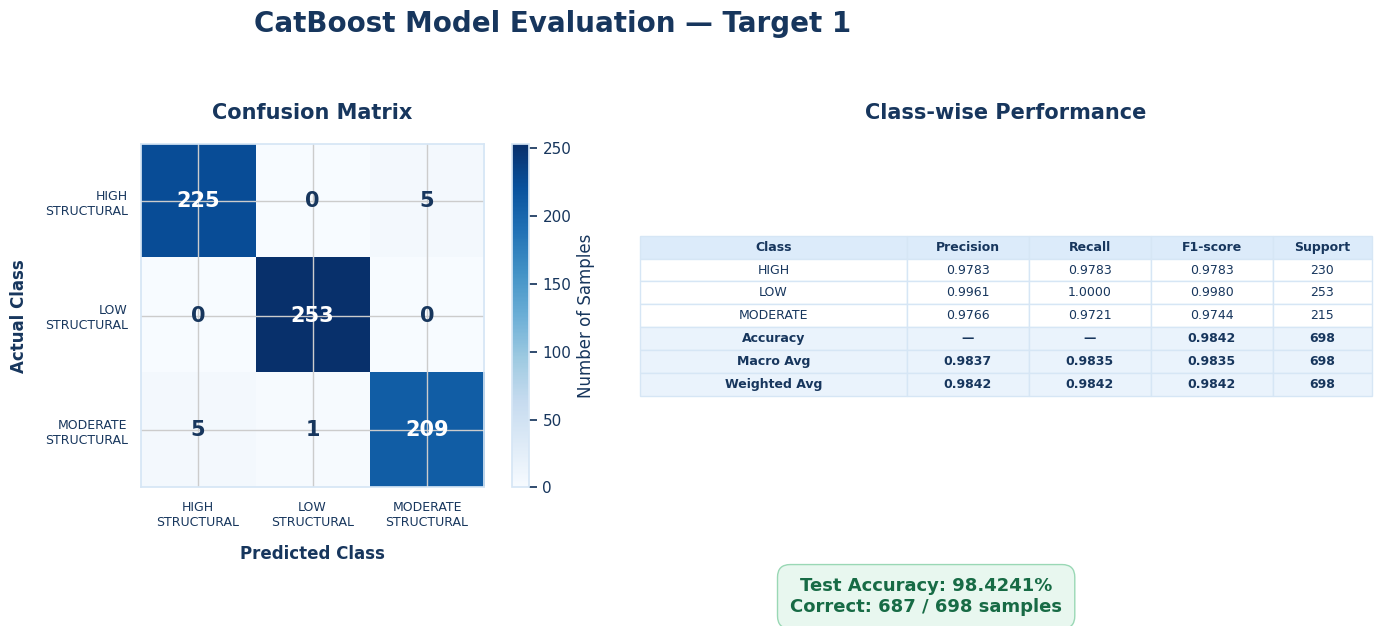

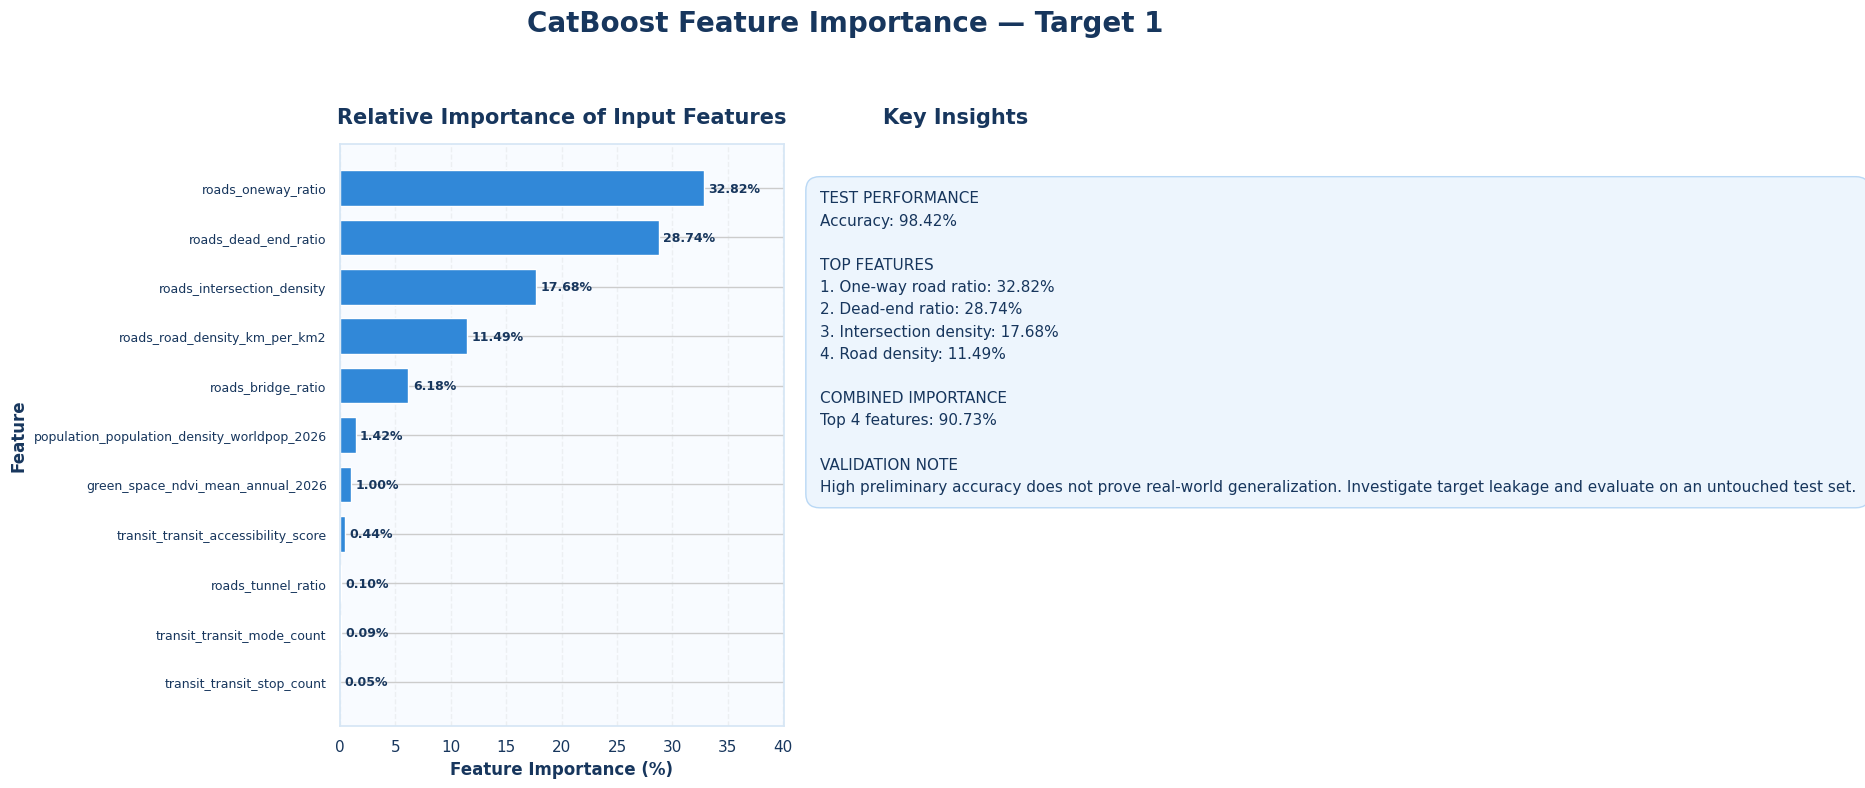

Saved successfully:
- target1_evaluation_dashboard.png
- target1_feature_importance_dashboard.png


In [26]:
import matplotlib.pyplot as plt
import numpy as np
import textwrap

# ==========================================
# إعدادات الشكل العام
# ==========================================
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#F8FBFF",
    "axes.edgecolor": "#D6E6F5",
    "axes.labelcolor": "#17365D",
    "text.color": "#17365D",
    "xtick.color": "#17365D",
    "ytick.color": "#17365D",
    "font.size": 10,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "savefig.facecolor": "white"
})

# ألوان الفئات
class_colors = ["#2471B8", "#F39C35", "#2E9D62"]

# أسماء مختصرة للعرض
short_labels = [
    "HIGH\nSTRUCTURAL",
    "LOW\nSTRUCTURAL",
    "MODERATE\nSTRUCTURAL"
]

# ==========================================
# Plot 1: Confusion Matrix + Model Metrics
# ==========================================
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(17, 7),
    gridspec_kw={"width_ratios": [1.05, 1.15]}
)

fig.suptitle(
    "CatBoost Model Evaluation — Target 1",
    fontsize=20,
    fontweight="bold",
    color="#17365D",
    y=0.98
)

# Confusion Matrix Heatmap
im = ax1.imshow(cm, cmap="Blues")

ax1.set_title("Confusion Matrix", pad=18)
ax1.set_xticks(np.arange(len(labels)))
ax1.set_yticks(np.arange(len(labels)))
ax1.set_xticklabels(short_labels, fontsize=9)
ax1.set_yticklabels(short_labels, fontsize=9)

ax1.set_xlabel("Predicted Class", fontweight="bold", labelpad=12)
ax1.set_ylabel("Actual Class", fontweight="bold", labelpad=12)

# كتابة القيم داخل الخلايا
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        value = cm[i, j]

        ax1.text(
            j, i, f"{value}",
            ha="center",
            va="center",
            fontsize=15,
            fontweight="bold",
            color="white" if value > cm.max() * 0.45 else "#17365D"
        )

cbar = fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label("Number of Samples")

# Classification Metrics
ax2.axis("off")
ax2.set_title("Class-wise Performance", pad=18)

report = classification_report(
    y_test,
    y_pred,
    labels=labels,
    output_dict=True,
    zero_division=0
)

table_rows = []

for label in labels:
    row = report[label]
    table_rows.append([
        label.replace("_STRUCTURAL_SUSCEPTIBILITY", ""),
        f"{row['precision']:.4f}",
        f"{row['recall']:.4f}",
        f"{row['f1-score']:.4f}",
        f"{int(row['support'])}"
    ])

table_rows.extend([
    [
        "Accuracy",
        "—",
        "—",
        f"{accuracy:.4f}",
        f"{len(y_test)}"
    ],
    [
        "Macro Avg",
        f"{report['macro avg']['precision']:.4f}",
        f"{report['macro avg']['recall']:.4f}",
        f"{report['macro avg']['f1-score']:.4f}",
        f"{len(y_test)}"
    ],
    [
        "Weighted Avg",
        f"{report['weighted avg']['precision']:.4f}",
        f"{report['weighted avg']['recall']:.4f}",
        f"{report['weighted avg']['f1-score']:.4f}",
        f"{len(y_test)}"
    ]
])

table = ax2.table(
    cellText=table_rows,
    colLabels=["Class", "Precision", "Recall", "F1-score", "Support"],
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[0.35, 0.16, 0.16, 0.16, 0.13]
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.0, 2.15)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#D6E6F5")

    if row == 0:
        cell.set_facecolor("#DCEBFA")
        cell.set_text_props(weight="bold", color="#17365D")
    elif row in [4, 5, 6]:
        cell.set_facecolor("#EAF3FC")
        cell.set_text_props(weight="bold", color="#17365D")
    else:
        cell.set_facecolor("white")

# Accuracy box
fig.text(
    0.72, 0.12,
    f"Test Accuracy: {accuracy:.4%}\n"
    f"Correct: {int(np.trace(cm))} / {int(cm.sum())} samples",
    ha="center",
    fontsize=13,
    fontweight="bold",
    color="#176B45",
    bbox=dict(
        boxstyle="round,pad=0.7",
        facecolor="#E8F7EF",
        edgecolor="#9AD8B5"
    )
)

plt.tight_layout(rect=[0, 0.18, 1, 0.93])

plt.savefig(
    "target1_evaluation_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# Plot 2: Feature Importance + Key Insights
# ==========================================
plot_df = importance_df.sort_values(
    "Importance",
    ascending=True
).copy()

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(17, 8),
    gridspec_kw={"width_ratios": [1.5, 1]}
)

fig.suptitle(
    "CatBoost Feature Importance — Target 1",
    fontsize=20,
    fontweight="bold",
    color="#17365D",
    y=0.98
)

# ترتيب المتغيرات من الأقل للأعلى
bars = ax1.barh(
    plot_df["Feature"],
    plot_df["Importance"],
    color="#3188D8",
    edgecolor="white",
    height=0.72
)

ax1.set_title("Relative Importance of Input Features", pad=15)
ax1.set_xlabel("Feature Importance (%)", fontweight="bold")
ax1.set_ylabel("Feature", fontweight="bold")
ax1.grid(axis="x", linestyle="--", alpha=0.25)
ax1.set_axisbelow(True)

max_importance = plot_df["Importance"].max()
ax1.set_xlim(0, max_importance * 1.22)

# كتابة النسب بجوار الأعمدة
for bar, value in zip(bars, plot_df["Importance"]):
    ax1.text(
        value + max_importance * 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#17365D"
    )

ax1.tick_params(axis="y", labelsize=9)

# حساب أهمية أول أربعة متغيرات
top4_importance = (
    importance_df.head(4)["Importance"].sum()
)

# لوحة الاستنتاجات
ax2.axis("off")
ax2.set_title("Key Insights", pad=15)

insights = (
    f"TEST PERFORMANCE\n"
    f"Accuracy: {accuracy:.2%}\n\n"
    f"TOP FEATURES\n"
    f"1. One-way road ratio: "
    f"{importance_df.iloc[0]['Importance']:.2f}%\n"
    f"2. Dead-end ratio: "
    f"{importance_df.iloc[1]['Importance']:.2f}%\n"
    f"3. Intersection density: "
    f"{importance_df.iloc[2]['Importance']:.2f}%\n"
    f"4. Road density: "
    f"{importance_df.iloc[3]['Importance']:.2f}%\n\n"
    f"COMBINED IMPORTANCE\n"
    f"Top 4 features: {top4_importance:.2f}%\n\n"
    f"VALIDATION NOTE\n"
    f"High preliminary accuracy does not prove "
    f"real-world generalization. Investigate target "
    f"leakage and evaluate on an untouched test set."
)

ax2.text(
    0.04, 0.92,
    insights,
    transform=ax2.transAxes,
    va="top",
    ha="left",
    fontsize=11,
    linespacing=1.6,
    bbox=dict(
        boxstyle="round,pad=0.9",
        facecolor="#EDF5FD",
        edgecolor="#B9D8F5"
    )
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

plt.savefig(
    "target1_feature_importance_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved successfully:")
print("- target1_evaluation_dashboard.png")
print("- target1_feature_importance_dashboard.png")

### Result 8 — Target 1 Visualization

**Status:** Completed successfully.

Two visualization files were generated and saved:

1. `target1_evaluation_dashboard.png`
   - Confusion Matrix
   - Class-wise Precision, Recall, F1-score, and Support
   - Overall Test Accuracy
   - Correct and incorrect prediction counts

2. `target1_feature_importance_dashboard.png`
   - Ranked horizontal Feature Importance chart
   - Top four predictive features
   - Combined importance of the top four features
   - Key model insights and validation warning

**Purpose:** To provide clear visual summaries of CatBoost model performance and the relative importance of input features for `traffic_structural_susceptibility_class`.

**Next Step:** Investigate potential target leakage and perform an independent model evaluation using an untouched test set before finalizing Target 1.

In [27]:
import pandas as pd

target = "traffic_structural_susceptibility_class"
source_index = "traffic_structural_network_friction_index"

print("=== Target Leakage Investigation ===")

# التأكد من وجود الأعمدة
for col in [target, source_index]:
    print(f"{col}: {'Found' if col in df.columns else 'Not found'}")

if target in df.columns and source_index in df.columns:

    audit_df = df[[target, source_index]].copy()

    print("\n=== Missing Values ===")
    print(audit_df.isna().sum())

    print("\n=== Source Index Statistics by Target Class ===")
    display(
        audit_df.groupby(target, observed=True)[source_index]
        .agg(["count", "min", "median", "mean", "max"])
        .round(4)
    )

    print("\n=== Source Index Ranges by Target Class ===")
    display(
        audit_df.groupby(target, observed=True)[source_index]
        .agg(["min", "max"])
        .round(4)
    )

    print("\n=== Correlation / Relationship Check ===")
    print(
        "Unique target classes:",
        audit_df[target].nunique()
    )
    print(
        "Unique source-index values:",
        audit_df[source_index].nunique()
    )

else:
    print(
        "\nOne or both columns were not found. "
        "Check the column names before continuing."
    )

=== Target Leakage Investigation ===
traffic_structural_susceptibility_class: Found
traffic_structural_network_friction_index: Found

=== Missing Values ===
traffic_structural_susceptibility_class      1
traffic_structural_network_friction_index    1
dtype: int64

=== Source Index Statistics by Target Class ===


,count,min,median,mean,max
traffic_structural_susceptibility_class,,,,,
HIGH_STRUCTURAL_SUSCEPTIBILITY,1151,0.2128,0.2992,0.3267,0.7299
LOW_STRUCTURAL_SUSCEPTIBILITY,1263,0.0000,0.0000,0.0000,0.0000
MODERATE_STRUCTURAL_SUSCEPTIBILITY,1074,0.0007,0.1956,0.1686,0.2128



=== Source Index Ranges by Target Class ===


,min,max
traffic_structural_susceptibility_class,,
HIGH_STRUCTURAL_SUSCEPTIBILITY,0.2128,0.7299
LOW_STRUCTURAL_SUSCEPTIBILITY,0.0000,0.0000
MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.0007,0.2128



=== Correlation / Relationship Check ===
Unique target classes: 3
Unique source-index values: 1821


In [28]:
import numpy as np
import pandas as pd

target = "traffic_structural_susceptibility_class"
source_index = "traffic_structural_network_friction_index"

audit = df[[target, source_index]].dropna().copy()

# ترتيب الصفوف حسب قيمة المؤشر
audit = audit.sort_values(source_index)

print("=== Values Around the HIGH / MODERATE Boundary ===")

boundary_rows = audit[
    audit[source_index].between(0.2125, 0.2131)
]

display(
    boundary_rows.groupby([source_index, target], observed=True)
    .size()
    .unstack(fill_value=0)
)

# اختبار قاعدة تقريبية مستنتجة من الحدود الظاهرة
# ملاحظة: الحدود هنا فرضية للاختبار وليست قاعدة مؤكدة
audit["rule_prediction"] = np.select(
    [
        audit[source_index] == 0,
        audit[source_index] > 0,
    ],
    [
        "LOW_STRUCTURAL_SUSCEPTIBILITY",
        "MODERATE_OR_HIGH",
    ],
    default="UNKNOWN"
)

print("\n=== Target Distribution by Source Index ===")
display(
    pd.crosstab(
        audit["rule_prediction"],
        audit[target],
        margins=True
    )
)

print("\n=== Exact Index Values Shared by Multiple Classes ===")
class_counts = (
    audit.groupby(source_index)[target]
    .nunique()
)

shared_values = class_counts[class_counts > 1]

print("Index values associated with multiple target classes:",
      len(shared_values))

if len(shared_values) > 0:
    display(
        audit[audit[source_index].isin(shared_values.index)]
        .sort_values(source_index)
        .head(20)
    )

=== Values Around the HIGH / MODERATE Boundary ===


traffic_structural_susceptibility_class,HIGH_STRUCTURAL_SUSCEPTIBILITY,MODERATE_STRUCTURAL_SUSCEPTIBILITY
traffic_structural_network_friction_index,,
0.212573,0,1
0.212573,0,1
0.212780,0,1
0.212819,1,0



=== Target Distribution by Source Index ===


traffic_structural_susceptibility_class,HIGH_STRUCTURAL_SUSCEPTIBILITY,LOW_STRUCTURAL_SUSCEPTIBILITY,MODERATE_STRUCTURAL_SUSCEPTIBILITY,All
rule_prediction,,,,
LOW_STRUCTURAL_SUSCEPTIBILITY,0,1263,0,1263
MODERATE_OR_HIGH,1151,0,1074,2225
All,1151,1263,1074,3488



=== Exact Index Values Shared by Multiple Classes ===
Index values associated with multiple target classes: 0


In [29]:
import pandas as pd

source_index = "traffic_structural_network_friction_index"

# استخدام نفس الـ Features التي دخلت الموديل
audit_features = X_train.columns.tolist()

# تجهيز البيانات
feature_audit = df[audit_features + [source_index]].copy()

print("=== Feature Correlation with Structural Friction Index ===")

correlations = (
    feature_audit.corr(numeric_only=True)[source_index]
    .drop(source_index)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(
    correlations.to_frame("Correlation_with_Friction_Index")
    .round(4)
)

print("\n=== Feature Correlation with Target Encoding ===")

target_mapping = {
    "LOW_STRUCTURAL_SUSCEPTIBILITY": 0,
    "MODERATE_STRUCTURAL_SUSCEPTIBILITY": 1,
    "HIGH_STRUCTURAL_SUSCEPTIBILITY": 2
}

target_numeric = df["traffic_structural_susceptibility_class"].map(
    target_mapping
)

target_correlations = (
    df[audit_features]
    .corrwith(target_numeric)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(
    target_correlations.to_frame("Correlation_with_Target_Encoding")
    .round(4)
)

=== Feature Correlation with Structural Friction Index ===


,Correlation_with_Friction_Index
roads_road_density_km_per_km2,0.7631
roads_intersection_density,0.6238
roads_oneway_ratio,0.6109
transit_transit_accessibility_score,0.5141
transit_transit_mode_count,0.4847
transit_transit_stop_count,0.4619
roads_dead_end_ratio,0.4299
population_population_density_worldpop_2026,0.3934
roads_bridge_ratio,0.3654
green_space_ndvi_mean_annual_2026,0.3302



=== Feature Correlation with Target Encoding ===


,Correlation_with_Target_Encoding
roads_road_density_km_per_km2,0.7571
roads_oneway_ratio,0.6049
roads_intersection_density,0.5946
transit_transit_accessibility_score,0.4221
roads_dead_end_ratio,0.4088
transit_transit_mode_count,0.3943
green_space_ndvi_mean_annual_2026,0.3796
transit_transit_stop_count,0.3481
population_population_density_worldpop_2026,0.3291
roads_bridge_ratio,0.2186


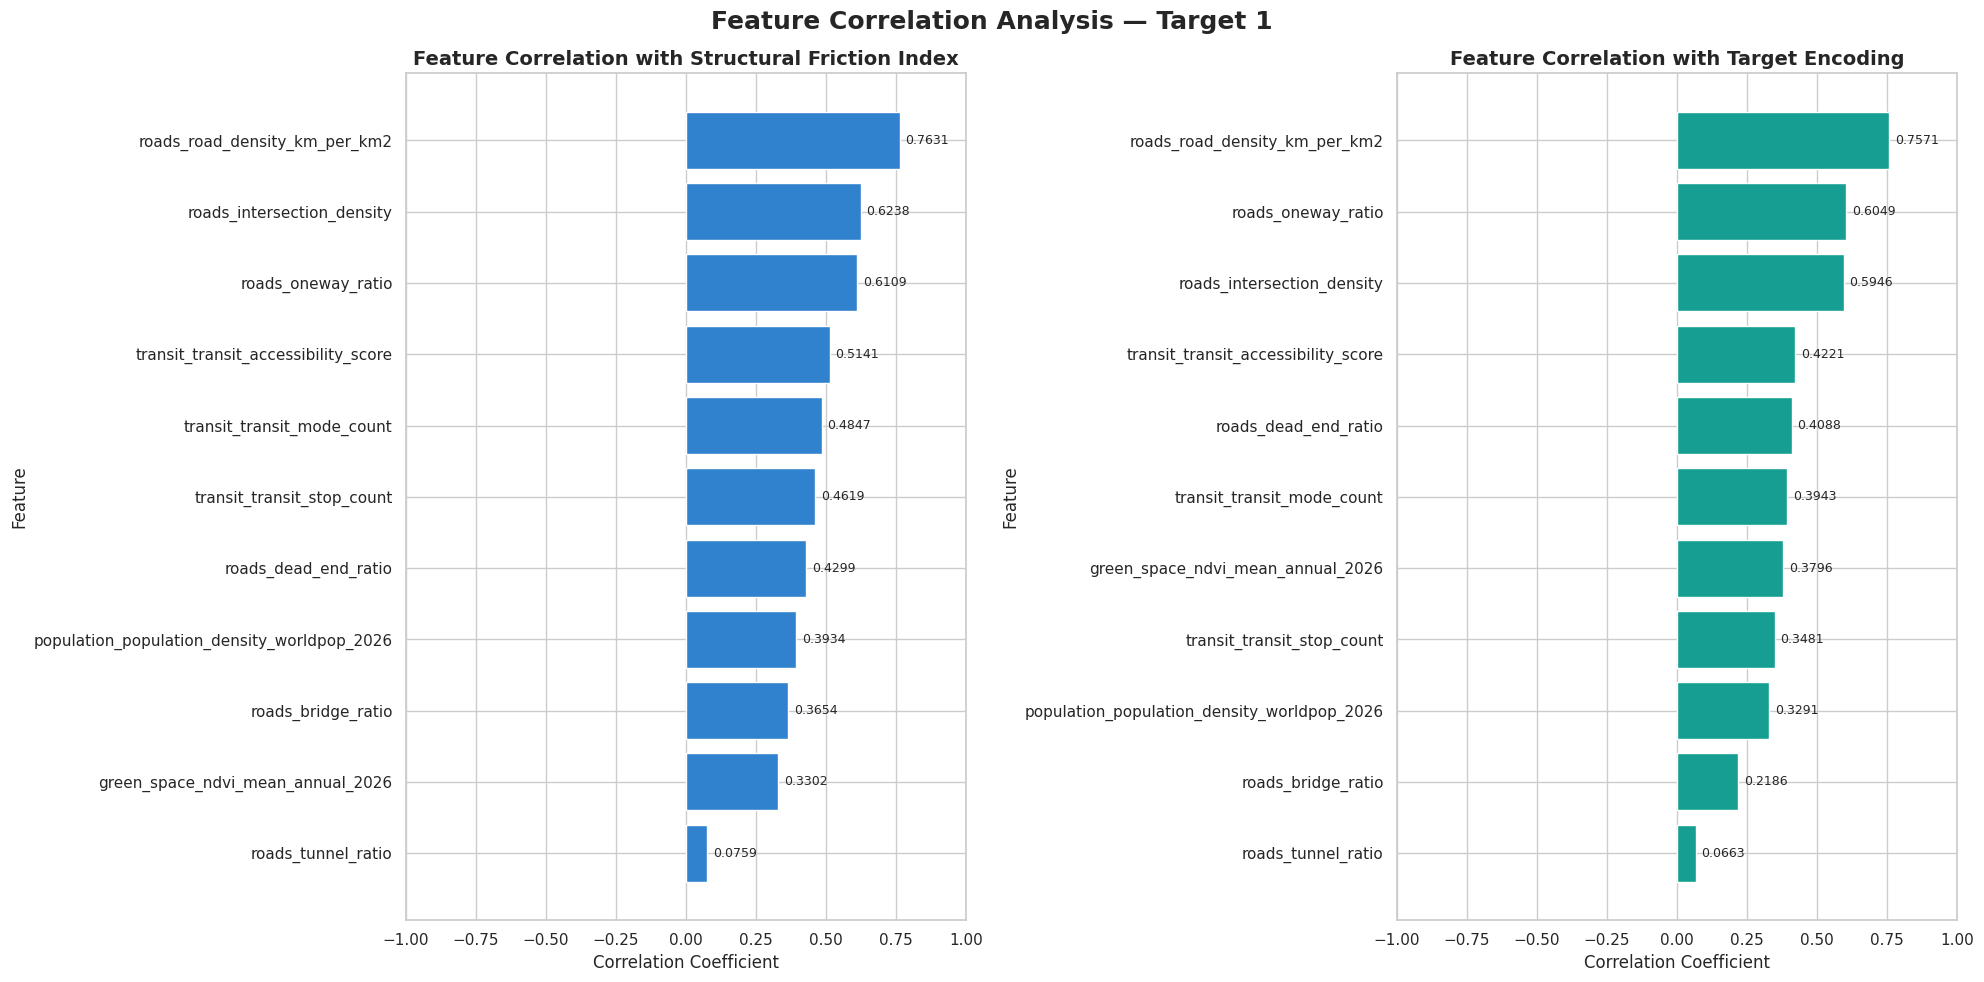

Saved: target1_correlation_analysis.png


In [30]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# تجهيز نتائج الارتباط في DataFrames للرسم
friction_corr = correlations.sort_values()
target_corr = target_correlations.sort_values()

# إعداد شكل الرسومات
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# الرسم الأول: الارتباط مع Structural Friction Index
axes[0].barh(
    friction_corr.index,
    friction_corr.values,
    color="#3182CE"
)
axes[0].set_title(
    "Feature Correlation with Structural Friction Index",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_xlabel("Correlation Coefficient")
axes[0].set_ylabel("Feature")
axes[0].set_xlim(-1, 1)

for i, value in enumerate(friction_corr.values):
    axes[0].text(
        value + 0.02, i, f"{value:.4f}",
        va="center", fontsize=9
    )

# الرسم الثاني: الارتباط مع Target Encoding
axes[1].barh(
    target_corr.index,
    target_corr.values,
    color="#159E91"
)
axes[1].set_title(
    "Feature Correlation with Target Encoding",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Correlation Coefficient")
axes[1].set_ylabel("Feature")
axes[1].set_xlim(-1, 1)

for i, value in enumerate(target_corr.values):
    axes[1].text(
        value + 0.02, i, f"{value:.4f}",
        va="center", fontsize=9
    )

fig.suptitle(
    "Feature Correlation Analysis — Target 1",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "target1_correlation_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: target1_correlation_analysis.png")


### Interpretation of Feature Correlation Analysis — Target 1

The correlation analysis shows that `roads_road_density_km_per_km2` has the strongest positive correlation with both the structural friction index (0.7631) and the encoded target classes (0.7571). Road intersection density and one-way road ratio also show strong positive correlations with both variables.

Transit-related features demonstrate moderate positive correlations, while `roads_tunnel_ratio` has the weakest correlation in both analyses.

These findings indicate that road network characteristics are strongly associated with the target classes. The similar correlation patterns between the input features, structural friction index, and target suggest a potential dependency between the target-generation process and the model inputs. However, correlation alone does not prove data leakage or causation. The target construction methodology must be reviewed before drawing a final conclusion.

**Conclusion:** The results highlight road network characteristics as important variables for Target 1 and motivate further investigation into the target-generation rules and potential data leakage.

In [31]:

# Cell 13: Inspect columns related to structural susceptibility
# and structural friction to investigate target construction.

keywords = [
    "structural",
    "friction",
    "susceptibility",
    "resilience",
    "risk",
    "vulnerability"
]

related_columns = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in keywords)
]

print(f"Number of related columns: {len(related_columns)}")

for col in related_columns:
    print(col)


Number of related columns: 3
traffic_structural_network_friction_index
traffic_structural_susceptibility_class
traffic_structural_index_available


### Structural Target Column Audit

The column audit identified three variables related to structural susceptibility and friction:

- `traffic_structural_network_friction_index`
- `traffic_structural_susceptibility_class`
- `traffic_structural_index_available`

The dataset contains the source friction index, the target classification, and an availability indicator. No additional columns matching the selected structural, friction, susceptibility, resilience, risk, or vulnerability keywords were found.

This does not rule out indirect data leakage, because the target may have been generated using other road-network or transportation variables. Therefore, the target-generation methodology should be reviewed before the model is considered independently predictive.

In [32]:

# Cell 14: Audit the structural index availability indicator

target = "traffic_structural_susceptibility_class"
index_col = "traffic_structural_network_friction_index"
available_col = "traffic_structural_index_available"

print("=== Availability Indicator Values ===")
display(df[available_col].value_counts(dropna=False))

print("\n=== Availability Indicator vs. Index Missingness ===")

audit_availability = df[[index_col, available_col]].copy()

audit_availability["index_is_missing"] = (
    audit_availability[index_col].isna()
)

display(
    pd.crosstab(
        audit_availability[available_col],
        audit_availability["index_is_missing"],
        margins=True,
        dropna=False
    )
)

print("\n=== Target vs. Availability Indicator ===")
display(
    pd.crosstab(
        df[available_col],
        df[target],
        margins=True,
        dropna=False
    )
)


=== Availability Indicator Values ===


,count
traffic_structural_index_available,
True,3488
NaN,1



=== Availability Indicator vs. Index Missingness ===


index_is_missing,False,True,All
traffic_structural_index_available,,,
True,3488,0,3488.0
NaN,0,1,NaN
All,3488,1,3489.0



=== Target vs. Availability Indicator ===


traffic_structural_susceptibility_class,HIGH_STRUCTURAL_SUSCEPTIBILITY,LOW_STRUCTURAL_SUSCEPTIBILITY,MODERATE_STRUCTURAL_SUSCEPTIBILITY,NaN,All
traffic_structural_index_available,,,,,
True,1151,1263,1074,0,3488.0
NaN,0,0,0,1,NaN
All,1151,1263,1074,0,3489.0


### Structural Index Availability Audit

The availability indicator is `True` for 3,488 out of 3,489 rows. All rows with a `True` indicator have a valid structural friction index and a non-missing target class. The single row with a missing availability indicator also has a missing index and target value.

This indicates consistent missing-value patterns across these three columns. However, the availability indicator does not establish how the target classes were generated, so the target-generation methodology still needs to be reviewed before the model's predictive performance can be fully validated.

In [33]:

# Cell 15: Inspect structural target class boundaries

target = "traffic_structural_susceptibility_class"
index_col = "traffic_structural_network_friction_index"

boundary_audit = df[[target, index_col]].dropna().copy()

class_summary = (
    boundary_audit.groupby(target)[index_col]
    .agg(["count", "min", "max", "mean", "median", "std"])
    .round(6)
)

print("=== Structural Friction Index by Target Class ===")
display(class_summary)

print("\n=== Sorted Index Values Near Class Boundaries ===")

for class_name in [
    "LOW_STRUCTURAL_SUSCEPTIBILITY",
    "MODERATE_STRUCTURAL_SUSCEPTIBILITY",
    "HIGH_STRUCTURAL_SUSCEPTIBILITY"
]:
    subset = boundary_audit[
        boundary_audit[target] == class_name
    ].sort_values(index_col)

    print(f"\n{class_name}")
    display(
        pd.concat([
            subset.head(3),
            subset.tail(3)
        ]).drop_duplicates().reset_index(drop=True)
    )


=== Structural Friction Index by Target Class ===


,count,min,max,mean,median,std
traffic_structural_susceptibility_class,,,,,,
HIGH_STRUCTURAL_SUSCEPTIBILITY,1151,0.212819,0.729943,0.326729,0.299208,0.094970
LOW_STRUCTURAL_SUSCEPTIBILITY,1263,0.000000,0.000000,0.000000,0.000000,0.000000
MODERATE_STRUCTURAL_SUSCEPTIBILITY,1074,0.000695,0.212780,0.168583,0.195621,0.050723



=== Sorted Index Values Near Class Boundaries ===

LOW_STRUCTURAL_SUSCEPTIBILITY


,traffic_structural_susceptibility_class,traffic_structural_network_friction_index
0,LOW_STRUCTURAL_SUSCEPTIBILITY,0.0



MODERATE_STRUCTURAL_SUSCEPTIBILITY


,traffic_structural_susceptibility_class,traffic_structural_network_friction_index
0,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.000695
1,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.212573
2,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.212573
3,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.212780



HIGH_STRUCTURAL_SUSCEPTIBILITY


,traffic_structural_susceptibility_class,traffic_structural_network_friction_index
0,HIGH_STRUCTURAL_SUSCEPTIBILITY,0.212819
1,HIGH_STRUCTURAL_SUSCEPTIBILITY,0.213661
2,HIGH_STRUCTURAL_SUSCEPTIBILITY,0.213895
3,HIGH_STRUCTURAL_SUSCEPTIBILITY,0.641142
4,HIGH_STRUCTURAL_SUSCEPTIBILITY,0.719242
5,HIGH_STRUCTURAL_SUSCEPTIBILITY,0.729943


### Structural Friction Index Boundary Analysis

The structural friction index shows a clear separation between the LOW class and the other two classes. All 1,263 observations labeled `LOW_STRUCTURAL_SUSCEPTIBILITY` have an index value of 0.

The `MODERATE_STRUCTURAL_SUSCEPTIBILITY` class contains 1,074 observations, with index values ranging from 0.000695 to 0.212780. The `HIGH_STRUCTURAL_SUSCEPTIBILITY` class contains 1,151 observations, with values ranging from 0.212819 to 0.729943.

The observed gap between the maximum MODERATE value (0.212780) and the minimum HIGH value (0.212819) is very small. This strongly suggests a threshold-based relationship between the index and the target labels, although the exact target-generation rule cannot be confirmed from these summary statistics alone.

**Conclusion:** The target appears closely tied to the structural friction index. The target-generation methodology should be verified before interpreting the high CatBoost accuracy as evidence of independent predictive capability.

In [34]:

# Cell 16: Diagnostic test of a possible threshold-based target rule

target = "traffic_structural_susceptibility_class"
index_col = "traffic_structural_network_friction_index"

audit = df[[target, index_col]].dropna().copy()

# Hypothesis based on the observed class boundaries
audit["diagnostic_prediction"] = np.select(
    [
        audit[index_col] == 0,
        audit[index_col] <= 0.212780,
        audit[index_col] > 0.212780
    ],
    [
        "LOW_STRUCTURAL_SUSCEPTIBILITY",
        "MODERATE_STRUCTURAL_SUSCEPTIBILITY",
        "HIGH_STRUCTURAL_SUSCEPTIBILITY"
    ],
    default="UNKNOWN"
)

print("=== Actual vs. Diagnostic Rule Prediction ===")

display(
    pd.crosstab(
        audit[target],
        audit["diagnostic_prediction"],
        rownames=["Actual Class"],
        colnames=["Rule Prediction"],
        margins=True
    )
)

diagnostic_accuracy = (
    audit[target] == audit["diagnostic_prediction"]
).mean()

print(f"\nDiagnostic rule agreement: {diagnostic_accuracy:.4%}")


=== Actual vs. Diagnostic Rule Prediction ===


Rule Prediction,HIGH_STRUCTURAL_SUSCEPTIBILITY,LOW_STRUCTURAL_SUSCEPTIBILITY,MODERATE_STRUCTURAL_SUSCEPTIBILITY,All
Actual Class,,,,
HIGH_STRUCTURAL_SUSCEPTIBILITY,1151,0,0,1151
LOW_STRUCTURAL_SUSCEPTIBILITY,0,1263,0,1263
MODERATE_STRUCTURAL_SUSCEPTIBILITY,1,0,1073,1074
All,1152,1263,1073,3488



Diagnostic rule agreement: 99.9713%


### Diagnostic Target Rule Validation

A simple threshold-based diagnostic rule was tested against the existing structural susceptibility labels. The rule classified observations with an index of zero as LOW, values greater than zero and up to 0.212780 as MODERATE, and values above 0.212780 as HIGH.

The rule matched 3,487 out of 3,488 labeled observations, achieving an agreement rate of 99.9713%. Only one MODERATE observation was classified as HIGH.

This near-perfect agreement strongly indicates that the target labels are closely associated with the structural friction index and may have been generated using a threshold-based rule. However, the original labeling methodology must be checked to confirm this relationship.

**Important limitation:** The diagnostic agreement is not an independent model-performance score. It measures how closely a rule based on the source index reproduces the existing labels.

In [35]:

# Cell 17: Inspect the single disagreement in the diagnostic rule

target = "traffic_structural_susceptibility_class"
index_col = "traffic_structural_network_friction_index"

audit = df[[target, index_col]].dropna().copy()

audit["diagnostic_prediction"] = np.select(
    [
        audit[index_col] == 0,
        audit[index_col] <= 0.212780
    ],
    [
        "LOW_STRUCTURAL_SUSCEPTIBILITY",
        "MODERATE_STRUCTURAL_SUSCEPTIBILITY"
    ],
    default="HIGH_STRUCTURAL_SUSCEPTIBILITY"
)

disagreements = audit[
    audit[target] != audit["diagnostic_prediction"]
]

print("Number of disagreements:", len(disagreements))
display(disagreements)

if len(disagreements) > 0:
    print("\nOther feature values for the disagreement:")
    display(
        df.loc[
            disagreements.index,
            candidate_features + [index_col, target]
        ]
    )


Number of disagreements: 1


,traffic_structural_susceptibility_class,traffic_structural_network_friction_index,diagnostic_prediction
310,MODERATE_STRUCTURAL_SUSCEPTIBILITY,0.21278,HIGH_STRUCTURAL_SUSCEPTIBILITY



Other feature values for the disagreement:


,population_population_density_worldpop_2026,roads_road_density_km_per_km2,roads_intersection_density,roads_dead_end_ratio,roads_bridge_ratio,roads_tunnel_ratio,roads_oneway_ratio,roads_avg_lanes,transit_transit_stop_count,transit_transit_mode_count,transit_transit_accessibility_score,green_space_ndvi_mean_annual_2026,traffic_structural_network_friction_index,traffic_structural_susceptibility_class
310,833.7,4.37,8.07,0.4167,0.0,0.0,0.0395,NaN,0.0,0.0,0.0,0.0719,0.21278,MODERATE_STRUCTURAL_SUSCEPTIBILITY


### Diagnostic Rule Disagreement Analysis — Target 1

A diagnostic threshold-based rule was evaluated against the original structural susceptibility labels. The rule achieved **99.9713% agreement**, correctly matching 3,487 out of 3,488 observations.

Only one observation (row index 310) was misclassified. Its actual class is `MODERATE_STRUCTURAL_SUSCEPTIBILITY`, while the diagnostic rule predicted `HIGH_STRUCTURAL_SUSCEPTIBILITY`. The structural friction index for this observation is `0.212780`, which is very close to the observed boundary between the MODERATE and HIGH classes.

This result reinforces the strong relationship between the structural friction index and the target labels. The single disagreement may be related to the precise threshold or the original classification rule, but this cannot be confirmed from the available results alone.

**Conclusion:** The near-perfect agreement suggests that the target may have been generated using a threshold-based rule involving the structural friction index. The original target-generation methodology should be reviewed to confirm this and determine whether the high CatBoost accuracy reflects independent predictive ability or reproduction of an existing classification rule.

In [36]:

# Cell 18: Final audit summary for Target 1

target = "traffic_structural_susceptibility_class"
index_col = "traffic_structural_network_friction_index"

audit = df[[target, index_col]].dropna().copy()

# Diagnostic rule based on observed index boundaries
audit["diagnostic_prediction"] = np.select(
    [
        audit[index_col] == 0,
        audit[index_col] <= 0.212780
    ],
    [
        "LOW_STRUCTURAL_SUSCEPTIBILITY",
        "MODERATE_STRUCTURAL_SUSCEPTIBILITY"
    ],
    default="HIGH_STRUCTURAL_SUSCEPTIBILITY"
)

agreement = (
    audit[target] == audit["diagnostic_prediction"]
).mean()

print("=== TARGET 1: FINAL AUDIT SUMMARY ===")
print(f"Target column: {target}")
print(f"Rows with valid target and index: {len(audit)}")
print(f"Missing target values: {df[target].isna().sum()}")
print(f"Missing index values: {df[index_col].isna().sum()}")
print(f"Diagnostic rule agreement: {agreement:.4%}")
print(
    "Disagreements:",
    (audit[target] != audit["diagnostic_prediction"]).sum()
)

print("\n=== Target Class Distribution ===")
display(df[target].value_counts(dropna=False))

print("\n=== Audit Conclusion ===")
print(
    "The target is strongly associated with the structural friction index. "
    "The original target-generation method should be verified before "
    "claiming independent predictive performance."
)


=== TARGET 1: FINAL AUDIT SUMMARY ===
Target column: traffic_structural_susceptibility_class
Rows with valid target and index: 3488
Missing target values: 1
Missing index values: 1
Diagnostic rule agreement: 99.9713%
Disagreements: 1

=== Target Class Distribution ===


,count
traffic_structural_susceptibility_class,
LOW_STRUCTURAL_SUSCEPTIBILITY,1263
HIGH_STRUCTURAL_SUSCEPTIBILITY,1151
MODERATE_STRUCTURAL_SUSCEPTIBILITY,1074
NaN,1



=== Audit Conclusion ===
The target is strongly associated with the structural friction index. The original target-generation method should be verified before claiming independent predictive performance.


# ==============================================================================
# 📊 FINAL AUDIT SUMMARY | TARGET 1
# ==============================================================================
# 📌 SCOPE & INTEGRITY
# • Evaluated Rows : 3,488 (valid target labels & friction index)
# • Missing Data   : 1 Target | 1 Index
#
# 📈 TARGET DISTRIBUTION
# • LOW      : 1,263 | HIGH : 1,151 | MODERATE : 1,074
#
# 🎯 DIAGNOSTIC PERFORMANCE
# • Agreement Rate : 99.9713% (1 disagreement)
#
# ⚠️ KEY FINDINGS & WARNINGS
# • Strong Association  : High correlation between Friction Index & Target.
# • Target Leakage Risk : Target-generation methodology unverified.
# • Model Caution       : Do NOT treat high CatBoost accuracy as true predictive
#                         power until target leakage & evaluation are validated.
# ==============================================================================

In [37]:

# Cell 19: Initial data audit for Target 2

target2 = "traffic_demand_capacity_pressure_class"
index2 = "traffic_demand_capacity_pressure_index"
availability2 = "traffic_demand_capacity_index_available"

print("=== TARGET 2: DATA AVAILABILITY AUDIT ===")

for col in [target2, index2, availability2]:
    if col in df.columns:
        missing = df[col].isna().sum()
        available = df[col].notna().sum()

        print(f"\nColumn: {col}")
        print(f"Available values: {available}")
        print(f"Missing values: {missing}")
        print(f"Missing percentage: {df[col].isna().mean() * 100:.2f}%")
    else:
        print(f"\nColumn not found: {col}")

print("\n=== Target 2 Class Distribution ===")
display(df[target2].value_counts(dropna=False))

print("\n=== Target 2 Availability Indicator Distribution ===")
if availability2 in df.columns:
    display(df[availability2].value_counts(dropna=False))


=== TARGET 2: DATA AVAILABILITY AUDIT ===

Column: traffic_demand_capacity_pressure_class
Available values: 26
Missing values: 3463
Missing percentage: 99.25%

Column: traffic_demand_capacity_pressure_index
Available values: 26
Missing values: 3463
Missing percentage: 99.25%

Column: traffic_demand_capacity_index_available
Available values: 3488
Missing values: 1
Missing percentage: 0.03%

=== Target 2 Class Distribution ===


,count
traffic_demand_capacity_pressure_class,
NaN,3463
HIGH_DEMAND_CAPACITY_PRESSURE,9
LOW_DEMAND_CAPACITY_PRESSURE,9
MODERATE_DEMAND_CAPACITY_PRESSURE,8



=== Target 2 Availability Indicator Distribution ===


,count
traffic_demand_capacity_index_available,
False,3462
True,26
NaN,1


### Target 2 — Data Availability and Class Distribution Analysis

The target `traffic_demand_capacity_pressure_class` contains only 26 available labels out of 3,489 rows, resulting in a missing-data rate of 99.25%.

The available labels are distributed across three classes: 9 HIGH, 9 LOW, and 8 MODERATE observations. The corresponding numeric index, `traffic_demand_capacity_pressure_index`, has the same availability pattern.

The availability indicator confirms that 26 rows are marked `True`, 3,462 rows are marked `False`, and one row has a missing indicator.

**Conclusion:** The current target coverage is insufficient for reliable supervised model training and evaluation. The next step is to investigate why the index is unavailable for most rows and whether the missing coverage can be addressed using the existing dataset or its original data sources.

In [38]:

# Cell 20: Validate Target 2 availability consistency

target2 = "traffic_demand_capacity_pressure_class"
index2 = "traffic_demand_capacity_pressure_index"
availability2 = "traffic_demand_capacity_index_available"

audit2 = df[[target2, index2, availability2]].copy()

audit2["target_missing"] = audit2[target2].isna()
audit2["index_missing"] = audit2[index2].isna()

print("=== Availability Indicator vs Target Missingness ===")
display(
    pd.crosstab(
        audit2[availability2],
        audit2["target_missing"],
        margins=True,
        dropna=False
    )
)

print("\n=== Availability Indicator vs Index Missingness ===")
display(
    pd.crosstab(
        audit2[availability2],
        audit2["index_missing"],
        margins=True,
        dropna=False
    )
)

print("\n=== Inconsistent Rows ===")

inconsistent = audit2[
    (
        (audit2[availability2] == True)
        & (audit2[target2].isna() | audit2[index2].isna())
    )
    |
    (
        (audit2[availability2] == False)
        & (audit2[target2].notna() | audit2[index2].notna())
    )
]

print("Number of inconsistent rows:", len(inconsistent))
display(inconsistent.head(20))


=== Availability Indicator vs Target Missingness ===


target_missing,False,True,All
traffic_demand_capacity_index_available,,,
False,0,3462,3462.0
NaN,0,1,NaN
True,26,0,26.0
All,26,3463,3489.0



=== Availability Indicator vs Index Missingness ===


index_missing,False,True,All
traffic_demand_capacity_index_available,,,
False,0,3462,3462.0
NaN,0,1,NaN
True,26,0,26.0
All,26,3463,3489.0



=== Inconsistent Rows ===
Number of inconsistent rows: 0


,traffic_demand_capacity_pressure_class,traffic_demand_capacity_pressure_index,traffic_demand_capacity_index_available,target_missing,index_missing


# Inspection Result:
# There are no inconsistent rows between the data availability indicator
# traffic_demand_capacity_index_available
# and the availability of both target and index.
#
# Rows where Availability = True: 26, and all contain
# non-missing values in target and index.
#
# Rows where Availability = False: 3462, and all contain
# missing values in target and index.
#
# There is 1 row with a missing value in the availability indicator itself,
# where target and index are also missing.
#
# Total inconsistent rows = 0.
#
# Conclusion:
# The issue with Target 2 is not caused by data inconsistency,
# but rather by the limited coverage of the indicator (only 26 cases available out of 3489).
# Therefore, we will not train a classification model at this stage.
# Instead, we will examine the available cases and data sources associated with the indicator
# to explore whether coverage can be reliably extended.

In [39]:
# Cell 21: Inspect rows where Target 2 is available

target2 = "traffic_demand_capacity_pressure_class"
index2 = "traffic_demand_capacity_pressure_index"
availability2 = "traffic_demand_capacity_index_available"

valid_target2 = df[df[availability2] == True].copy()

print("=== Target 2 Available Rows ===")
print("Number of rows:", len(valid_target2))

print("\n=== Target 2 Class Distribution ===")
display(valid_target2[target2].value_counts(dropna=False).to_frame("count"))

print("\n=== Target 2 Index Statistics ===")
display(valid_target2[index2].describe().to_frame("value"))

print("\n=== Relevant Column Names ===")
keywords = [
    "traffic", "demand", "capacity", "population_per_lane",
    "road_density", "intersection", "transit", "vehicle", "flow",
    "volume", "congestion", "speed"
]

relevant_columns = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in keywords)
]

print("Number of relevant columns:", len(relevant_columns))
display(pd.DataFrame({"column_name": relevant_columns}))

print("\n=== Relevant Columns: Non-missing Counts ===")
display(
    df[relevant_columns]
    .notna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("non_missing_count")
)

print("\n=== Relevant Features in the 26 Available Rows ===")
display(valid_target2[relevant_columns].head(26))

=== Target 2 Available Rows ===
Number of rows: 26

=== Target 2 Class Distribution ===


,count
traffic_demand_capacity_pressure_class,
HIGH_DEMAND_CAPACITY_PRESSURE,9
LOW_DEMAND_CAPACITY_PRESSURE,9
MODERATE_DEMAND_CAPACITY_PRESSURE,8



=== Target 2 Index Statistics ===


,value
count,26.000000
mean,0.213138
std,0.334141
min,0.000000
25%,0.000050
50%,0.027876
75%,0.251188
max,1.000000



=== Relevant Column Names ===
Number of relevant columns: 79


,column_name
0,population_cairo_intersection_ratio
1,roads_road_density_km_per_km2
2,roads_intersection_count
3,roads_intersection_density
4,roads_maxspeed_coverage
...,...
74,transit_district_calibration_factor
75,transit_calibrated_pop_2026
76,transit_district_assignment_method
77,transit_district_overlap_ratio



=== Relevant Columns: Non-missing Counts ===


,non_missing_count
roads_road_density_km_per_km2,3488
roads_intersection_count,3488
roads_intersection_density,3488
roads_maxspeed_coverage,3488
traffic_primary_secondary_length_km,3488
...,...
traffic_population_per_lane_km,26
traffic_demand_capacity_pressure_index,26
traffic_demand_capacity_pressure_class,26
roads_avg_maxspeed,19



=== Relevant Features in the 26 Available Rows ===


,population_cairo_intersection_ratio,roads_road_density_km_per_km2,roads_intersection_count,roads_intersection_density,roads_maxspeed_coverage,roads_avg_maxspeed,traffic_population_2026,traffic_road_length_km,traffic_road_density_km_per_km2,traffic_lane_km,traffic_avg_lanes,traffic_motorway_trunk_length_km,traffic_primary_secondary_length_km,traffic_intersection_count,traffic_intersection_density,traffic_dead_end_ratio,traffic_bridge_ratio,traffic_tunnel_ratio,traffic_oneway_ratio,traffic_avg_maxspeed,traffic_population_per_road_km,traffic_population_per_lane_km,traffic_lane_km_per_km2,traffic_intersection_per_road_km,traffic_intersection_density_norm,...,transit_transit_modes_available,transit_stop_density_per_km2,transit_nearest_transit_stop_network_distance_m,transit_nearest_metro_station_network_distance_m,transit_nearest_brt_station_network_distance_m,transit_transit_stops_within_400m_walk,transit_transit_stops_within_800m_walk,transit_transit_stops_within_1200m_walk,transit_metro_stations_within_800m_walk,transit_metro_stations_within_1500m_walk,transit_brt_stations_within_1000m_walk,transit_multimodal_hub_present,transit_population_within_400m_transit,transit_population_within_800m_transit,transit_population_within_1200m_transit,transit_transit_accessibility_score,transit_reference_year,transit_analytical_grid,transit_raw_worldpop_2026,transit_district,transit_district_calibration_factor,transit_calibrated_pop_2026,transit_district_assignment_method,transit_district_overlap_ratio,transit_fallback_flag
421,1.0,2.31,0.0,0.00,1.0,60.0,3.8571,2.006,2.31,6.018,3.00,2.006,0.0,0.0,0.00,0.0,0.0,0.0,1.0,60.0,1.922782,0.640927,6.939464,0.000000,0.000,...,NaN,0.0,1160.4,3021.8,29521.6,0.0,0.0,0.0,0.0,0.0,0.0,False,0.0,0.0,1.5,1.0,2026.0,H3_Res8,3.8571,Helwan,0.683329,2.6,centroid_sjoin,1.000000,False
910,1.0,0.97,0.0,0.00,1.0,120.0,23.8086,0.842,0.97,3.369,4.00,0.842,0.0,0.0,0.00,0.0,0.0,0.0,1.0,120.0,28.276247,7.066963,3.885957,0.000000,0.000,...,NaN,0.0,2610.7,12482.9,15571.4,0.0,0.0,0.0,0.0,0.0,0.0,False,0.0,0.0,0.0,0.0,2026.0,H3_Res8,23.8086,El Maadi,0.745358,17.7,centroid_sjoin,1.000000,False
1162,1.0,1.45,0.0,0.00,1.0,120.0,0.0003,1.257,1.45,6.227,4.96,1.257,0.0,0.0,0.00,0.0,0.0,0.0,1.0,120.0,0.000239,0.000048,7.196456,0.000000,0.000,...,NaN,0.0,2858.1,2858.1,41611.2,0.0,0.0,0.0,0.0,0.0,0.0,False,0.0,0.0,0.0,0.0,2026.0,H3_Res8,0.0003,New Cairo City,0.915446,0.0,FLAGGED_nearest_district_fallback_in_cairo_bou...,0.000000,True
1168,1.0,0.17,0.0,0.00,1.0,120.0,0.0001,0.145,0.17,0.581,4.00,0.145,0.0,0.0,0.00,0.0,0.0,0.0,1.0,120.0,0.000690,0.000172,0.671528,0.000000,0.000,...,NaN,0.0,4882.7,4882.7,43534.2,0.0,0.0,0.0,0.0,0.0,0.0,False,0.0,0.0,0.0,0.0,2026.0,H3_Res8,0.0001,New Cairo City,0.915446,0.0,FLAGGED_nearest_district_fallback_in_cairo_bou...,0.000000,True
1238,1.0,1.55,0.0,0.00,1.0,120.0,6.3245,1.342,1.55,5.367,4.00,1.342,0.0,0.0,0.00,0.0,0.0,0.0,1.0,120.0,4.712742,1.178405,6.197274,0.000000,0.000,...,NaN,0.0,10203.6,16582.8,25171.4,0.0,0.0,0.0,0.0,0.0,0.0,False,0.0,0.0,0.0,0.0,2026.0,H3_Res8,6.3245,New Cairo City,0.915446,5.8,FLAGGED_nearest_district_fallback_in_cairo_bou...,0.000000,True
1264,1.0,0.08,0.0,0.00,1.0,NaN,0.5517,0.073,0.08,0.291,4.00,0.073,0.0,0.0,0.00,0.0,0.0,0.0,1.0,NaN,7.557534,1.895876,0.336183,0.000000,0.000,...,NaN,0.0,6863.6,6863.6,40950.5,0.0,0.0,0.0,0.0,0.0,0.0,False,0.0,0.0,0.0,0.0,2026.0,H3_Res8,0.5517,New Cairo City,0.915446,0.5,FLAGGED_nearest_district_fallback_in_cairo_bou...,0.000000,True
1518,1.0,1.33,0.0,0.00,1.0,120.0,0.2627,1.148,1.33,5.741,5.00,1.148,0.0,0.0,0.00,0.0,0.0,0.0,1.0,120.0,0.228833,0.045759,6.637685,0.000000,0.000,...,NaN,0.0,11532.0,11532.0,50186.2,0.0,0.0,0.0,0.0,0.0,0.0,False,0.0,0.0,0.0,0.0,2026.0,H3_Res8,0.2627,New Cairo City,0.915446,0.2,FLAGGED_nearest_district_fallback_in_cairo_bou...,0.000000,True
1753,1.0,2.13,0.0,0.00,1.0,NaN,0.0004,1.844,2.13,7.378,4.00,1.844,0.0,0.0,0.00,0.0,0.0,0.0,1.0,NaN,0.000217,0.000054,8.516257,0.000000,0.000,...,NaN,0.0,20180.9,26131.9,40716

### Target 2 Inspection Results
- **Data Availability**: Only **26 out of 3,489 rows** contain valid Target 2 values.
- **Class Distribution**: 9 High, 9 Low, 8 Moderate.
- **Index Distribution**: Ranges from `0` to `1` (Mean = `0.2131`, Median = `0.0279`), showing right-skewness and a concentration of low values.
- **Related Features**: Identified **79 features** matching keywords (`traffic`, `demand`, `capacity`, `roads`, `transit`).
  - Core features (e.g., `traffic_population_per_lane_km`) are available in only 26 rows.
  - General road infrastructure features cover most of the dataset.
- **Data Quality Observation**: High prevalence of zero values in intersection and transit features within the available subset requires further validation.

### Conclusion
Training a reliable classification model on 26 samples is not feasible. The immediate next steps are:
1. Visually compare class distributions across target categories.
2. Assess feature availability and data sources for key predictors.
3. Handle missing data strictly without assuming missing values are zeros.

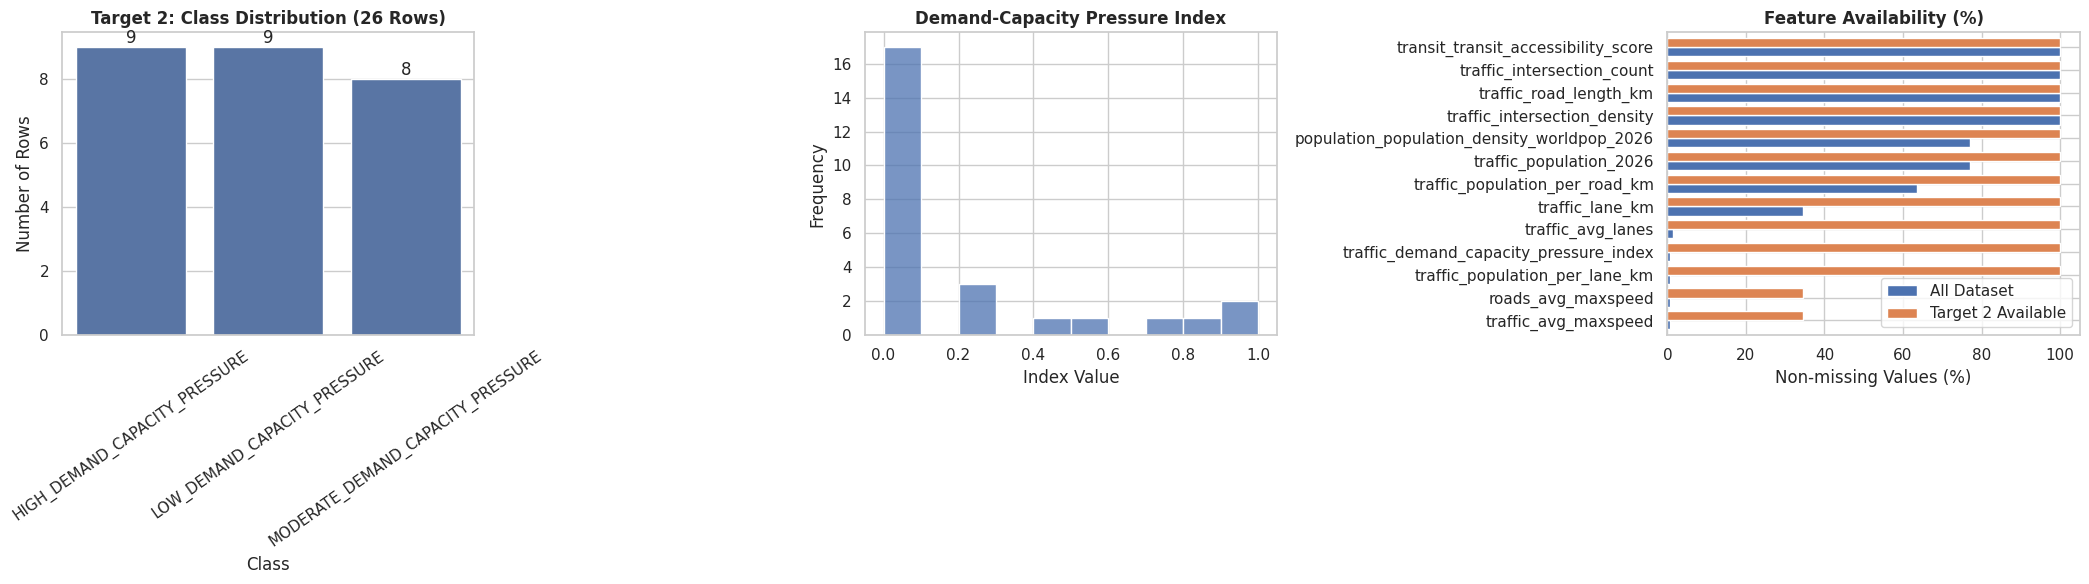

Target 2 rows: 26
Features plotted: 13


In [40]:
# Cell 22: Visual Analysis of Target 2 Coverage

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target2 = "traffic_demand_capacity_pressure_class"
index2 = "traffic_demand_capacity_pressure_index"
availability2 = "traffic_demand_capacity_index_available"

valid_target2 = df[df[target2].notna()].copy()

# اختيار أهم الخصائص المرتبطة مباشرة بالطلب والسعة
candidate_features = [
    "traffic_population_2026",
    "traffic_road_length_km",
    "traffic_lane_km",
    "traffic_avg_lanes",
    "traffic_population_per_road_km",
    "traffic_population_per_lane_km",
    "traffic_intersection_count",
    "traffic_intersection_density",
    "traffic_demand_capacity_pressure_index",
    "roads_avg_maxspeed",
    "traffic_avg_maxspeed",
    "transit_transit_accessibility_score",
    "population_population_density_worldpop_2026"
]

features = [col for col in candidate_features if col in df.columns]

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1. Target class distribution
class_counts = valid_target2[target2].value_counts()

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    ax=axes[0]
)
axes[0].set_title("Target 2: Class Distribution (26 Rows)")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of Rows")
axes[0].tick_params(axis="x", rotation=35)

for container in axes[0].containers:
    axes[0].bar_label(container)

# 2. Index distribution
index_values = valid_target2[index2].dropna()

sns.histplot(
    index_values,
    bins=10,
    kde=False,
    ax=axes[1]
)
axes[1].set_title("Demand-Capacity Pressure Index")
axes[1].set_xlabel("Index Value")
axes[1].set_ylabel("Frequency")

# 3. Feature coverage across all rows vs available Target 2 rows
coverage = pd.DataFrame({
    "All Dataset": df[features].notna().mean() * 100,
    "Target 2 Available": valid_target2[features].notna().mean() * 100
})

coverage = coverage.sort_values("All Dataset", ascending=True)

coverage.plot(
    kind="barh",
    ax=axes[2],
    width=0.8
)
axes[2].set_title("Feature Availability (%)")
axes[2].set_xlabel("Non-missing Values (%)")
axes[2].set_ylabel("")
axes[2].set_xlim(0, 105)
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

print("Target 2 rows:", len(valid_target2))
print("Features plotted:", len(features))

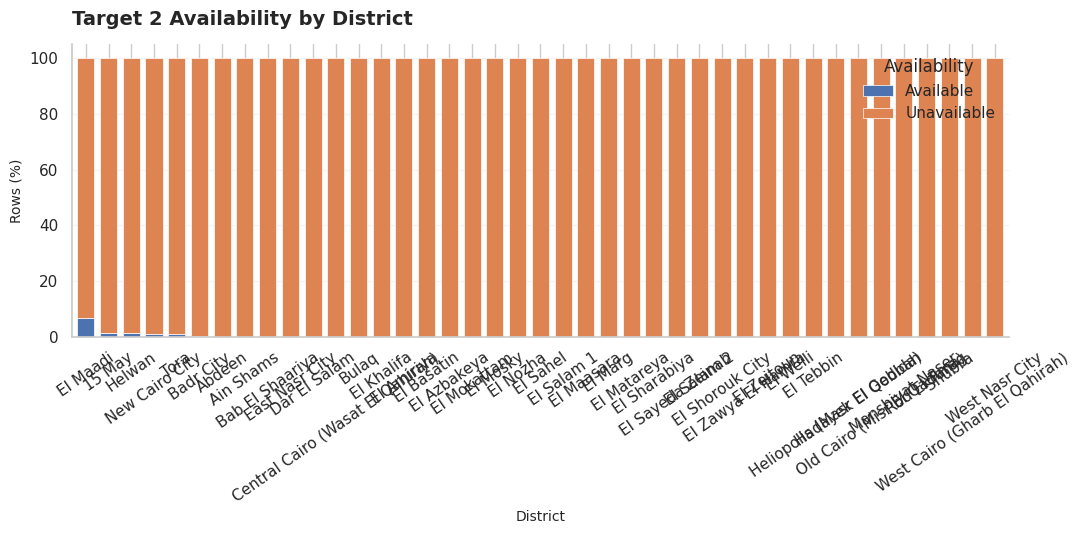

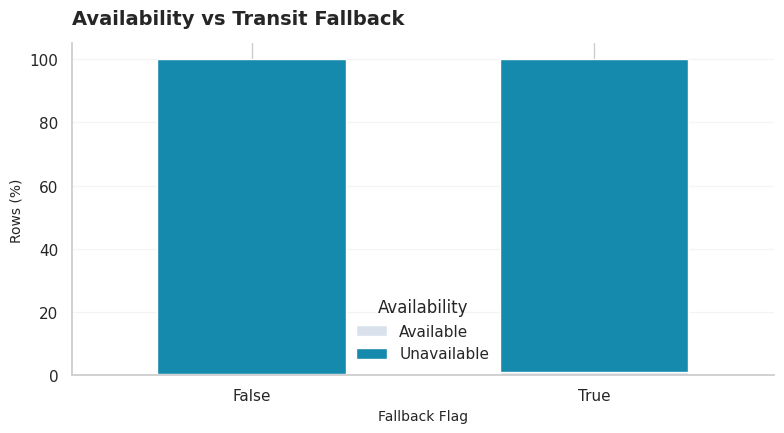

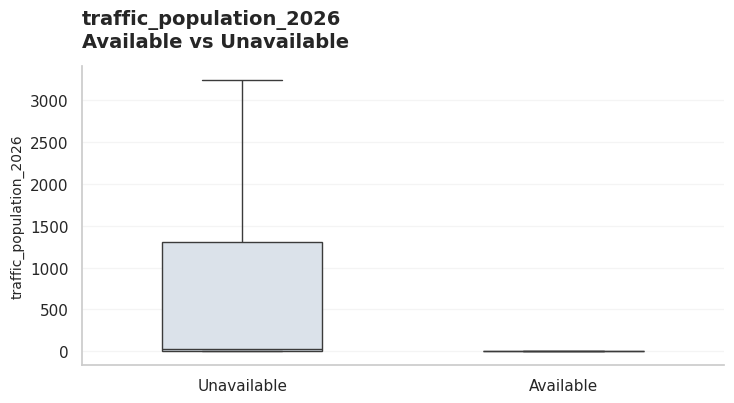

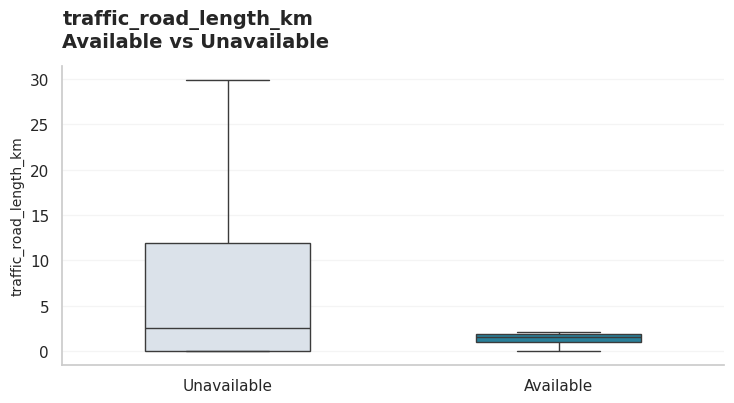

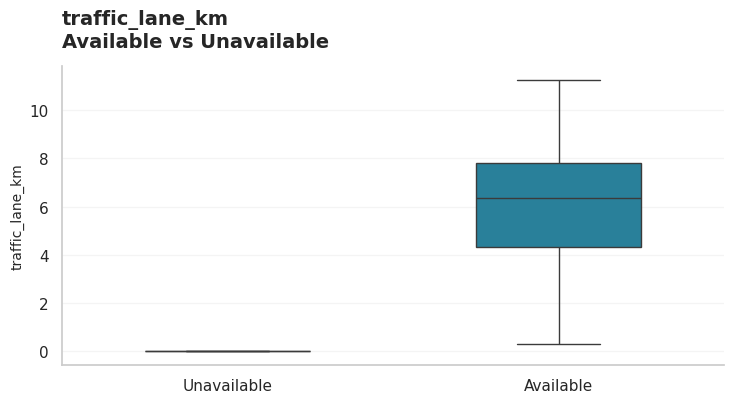

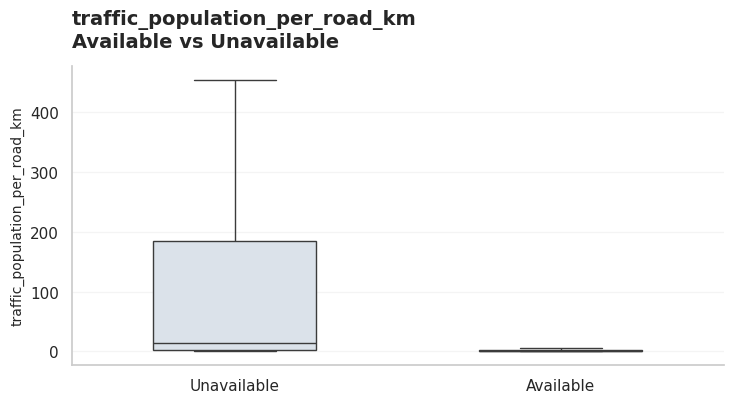

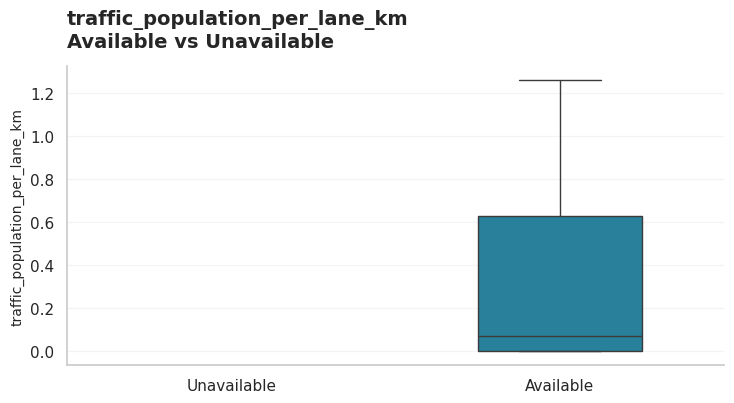

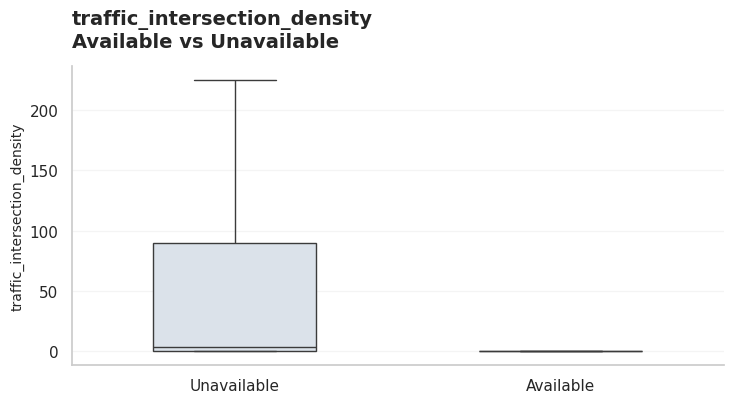

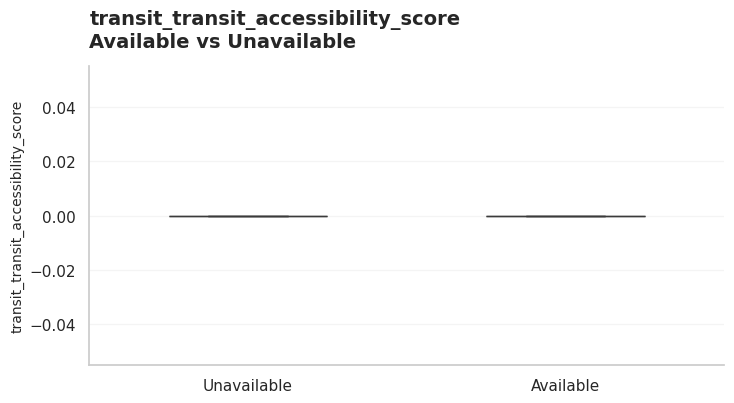

Available Target 2 rows: 26
Unavailable Target 2 rows: 3462
Features compared: 7


In [41]:
# Cell 23: Professional Visual Audit of Target 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

target2 = "traffic_demand_capacity_pressure_class"
availability2 = "traffic_demand_capacity_index_available"

# -------------------------------
# 1. Consistent professional style
# -------------------------------
sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.0
)

COLORS = {
    "available": "#168AAD",
    "unavailable": "#D9E2EC",
    "high": "#D1495B",
    "moderate": "#F4A261",
    "low": "#2A9D8F"
}

def finish_chart(ax, title, xlabel="", ylabel=""):
    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        loc="left",
        pad=14
    )
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.20)
    ax.set_axisbelow(True)

# -------------------------------
# 2. Availability by district
# -------------------------------
district_col = "transit_district"

if district_col in df.columns:
    district_data = df[
        df[district_col].notna()
        & df[availability2].notna()
    ].copy()

    district_data["Availability"] = district_data[availability2].map({
        True: "Available",
        False: "Unavailable"
    })

    district_table = pd.crosstab(
        district_data[district_col],
        district_data["Availability"],
        normalize="index"
    ).mul(100)

    district_table = district_table.sort_values(
        "Available",
        ascending=False
    )

    fig, ax = plt.subplots(figsize=(11, 5.5))

    district_table.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=[
            COLORS["unavailable"],
            COLORS["available"]
        ] if "Available" in district_table.columns
          and "Unavailable" in district_table.columns
          and list(district_table.columns) == ["Unavailable", "Available"]
        else None,
        width=0.75,
        edgecolor="white",
        linewidth=0.5
    )

    finish_chart(
        ax,
        "Target 2 Availability by District",
        "District",
        "Rows (%)"
    )
    ax.tick_params(axis="x", rotation=35)
    ax.set_ylim(0, 105)
    ax.legend(title="Availability", frameon=False, loc="upper right")

    plt.tight_layout()
    plt.show()

# -------------------------------
# 3. Availability vs fallback flag
# -------------------------------
fallback_col = "transit_fallback_flag"

if fallback_col in df.columns:
    fallback_data = df[
        df[fallback_col].notna()
        & df[availability2].notna()
    ].copy()

    fallback_data["Availability"] = fallback_data[availability2].map({
        True: "Available",
        False: "Unavailable"
    })

    fallback_table = pd.crosstab(
        fallback_data[fallback_col].astype(str),
        fallback_data["Availability"],
        normalize="index"
    ).mul(100)

    fig, ax = plt.subplots(figsize=(8, 4.5))

    fallback_table.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=[COLORS["unavailable"], COLORS["available"]],
        width=0.55,
        edgecolor="white"
    )

    finish_chart(
        ax,
        "Availability vs Transit Fallback",
        "Fallback Flag",
        "Rows (%)"
    )
    ax.tick_params(axis="x", rotation=0)
    ax.set_ylim(0, 105)
    ax.legend(title="Availability", frameon=False)

    plt.tight_layout()
    plt.show()

# -------------------------------
# 4. Compare feature distributions
# -------------------------------
candidate_features = [
    "traffic_population_2026",
    "traffic_road_length_km",
    "traffic_lane_km",
    "traffic_population_per_road_km",
    "traffic_population_per_lane_km",
    "traffic_intersection_density",
    "transit_transit_accessibility_score"
]

features = [
    col for col in candidate_features
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

comparison = df[features + [availability2]].copy()
comparison["Availability"] = comparison[availability2].map({
    True: "Available",
    False: "Unavailable"
})

# Separate charts to keep the layout readable
for feature in features:
    plot_data = comparison[
        comparison["Availability"].notna()
        & comparison[feature].notna()
    ].copy()

    if plot_data.empty:
        continue

    fig, ax = plt.subplots(figsize=(7.5, 4.2))

    sns.boxplot(
        data=plot_data,
        x="Availability",
        y=feature,
        hue="Availability",
        order=["Unavailable", "Available"],
        hue_order=["Unavailable", "Available"],
        palette={
            "Unavailable": COLORS["unavailable"],
            "Available": COLORS["available"]
        },
        legend=False,
        width=0.5,
        showfliers=False,
        ax=ax
    )

    finish_chart(
        ax,
        f"{feature}\nAvailable vs Unavailable",
        "",
        feature
    )

    ax.grid(axis="x", visible=False)
    plt.tight_layout()
    plt.show()

print(f"Available Target 2 rows: {int(df[availability2].eq(True).sum())}")
print(f"Unavailable Target 2 rows: {int(df[availability2].eq(False).sum())}")
print(f"Features compared: {len(features)}")

### Target 2 — Feature Availability Analysis

The analysis compared 26 records with available Target 2 labels against 3,462 records with unavailable labels across seven selected features.

- **Data Coverage**: Target 2 coverage is extremely limited, with only ~0.75% of the analyzed records containing a valid target label.
- **Interpretation Caution**: Observed differences between available and unavailable records should be interpreted cautiously, as they may reflect data collection or processing coverage rather than genuine traffic-demand patterns.
- **Data Viability**: This level of missingness is insufficient to support a reliable supervised classification model without further investigation.

### Next Steps
1. Examine the availability of underlying `demand`, `capacity`, and `population_per_lane` variables.
2. Identify whether missingness correlates with specific data-processing artifacts or geographic conditions.

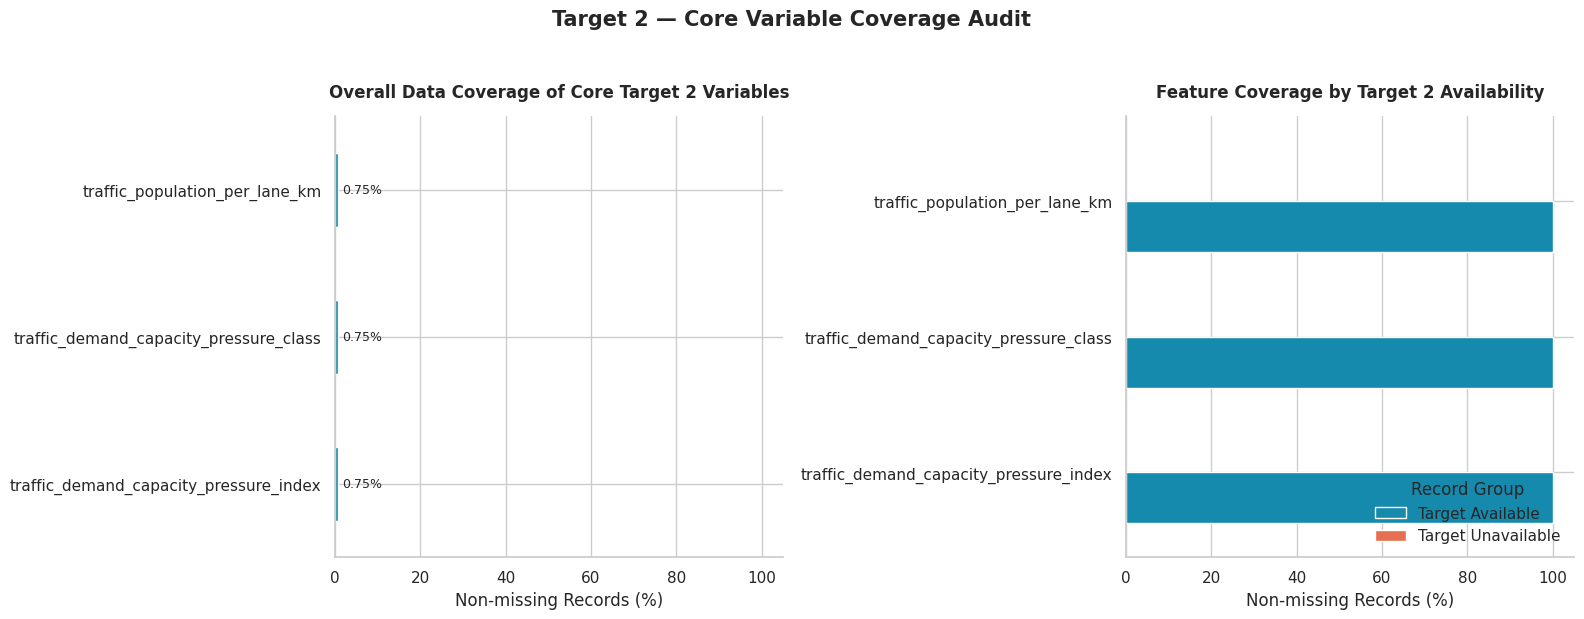

Core variables analyzed: 3
Records with Target 2: 26
Records without Target 2: 3463
Core variables found: ['traffic_demand_capacity_pressure_index', 'traffic_demand_capacity_pressure_class', 'traffic_population_per_lane_km']


In [42]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# المتغيرات الأساسية المرتبطة بحساب Target 2
core_features = [
    'traffic_demand_capacity_pressure_index',
    'traffic_demand_capacity_pressure_class',
    'traffic_population_per_lane_km',
    'traffic_demand_index',
    'traffic_capacity_index'
]

# الاحتفاظ بالأعمدة الموجودة فقط
core_features = [col for col in core_features if col in df.columns]

target_col = 'traffic_demand_capacity_pressure_class'
available_mask = df[target_col].notna()

coverage = (
    df[core_features]
    .notna()
    .mean()
    .mul(100)
    .sort_values()
)

sns.set_theme(style="whitegrid", context="notebook")

# ألوان موحدة
available_color = "#168AAD"
missing_color = "#E76F51"

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# الرسم الأول: التغطية الكلية لكل متغير
coverage.plot(
    kind="barh",
    ax=axes[0],
    color=available_color,
    edgecolor="white"
)

axes[0].set_title(
    "Overall Data Coverage of Core Target 2 Variables",
    fontsize=12,
    fontweight="bold",
    pad=14
)
axes[0].set_xlabel("Non-missing Records (%)")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 105)

for i, value in enumerate(coverage.values):
    axes[0].text(
        min(value + 1, 96),
        i,
        f"{value:.2f}%",
        va="center",
        fontsize=9
    )

# الرسم الثاني: التغطية داخل كل مجموعة
group_coverage = pd.DataFrame({
    "Target Available": df.loc[available_mask, core_features].notna().mean() * 100,
    "Target Unavailable": df.loc[~available_mask, core_features].notna().mean() * 100
})

group_coverage = group_coverage.sort_values("Target Available")

group_coverage.plot(
    kind="barh",
    ax=axes[1],
    color=[available_color, missing_color],
    edgecolor="white",
    width=0.75
)

axes[1].set_title(
    "Feature Coverage by Target 2 Availability",
    fontsize=12,
    fontweight="bold",
    pad=14
)
axes[1].set_xlabel("Non-missing Records (%)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 105)
axes[1].legend(
    title="Record Group",
    frameon=False,
    loc="lower right"
)

fig.suptitle(
    "Target 2 — Core Variable Coverage Audit",
    fontsize=15,
    fontweight="bold",
    y=1.03
)

sns.despine()
plt.tight_layout()
plt.show()

print("Core variables analyzed:", len(core_features))
print("Records with Target 2:", int(available_mask.sum()))
print("Records without Target 2:", int((~available_mask).sum()))
print("Core variables found:", core_features)


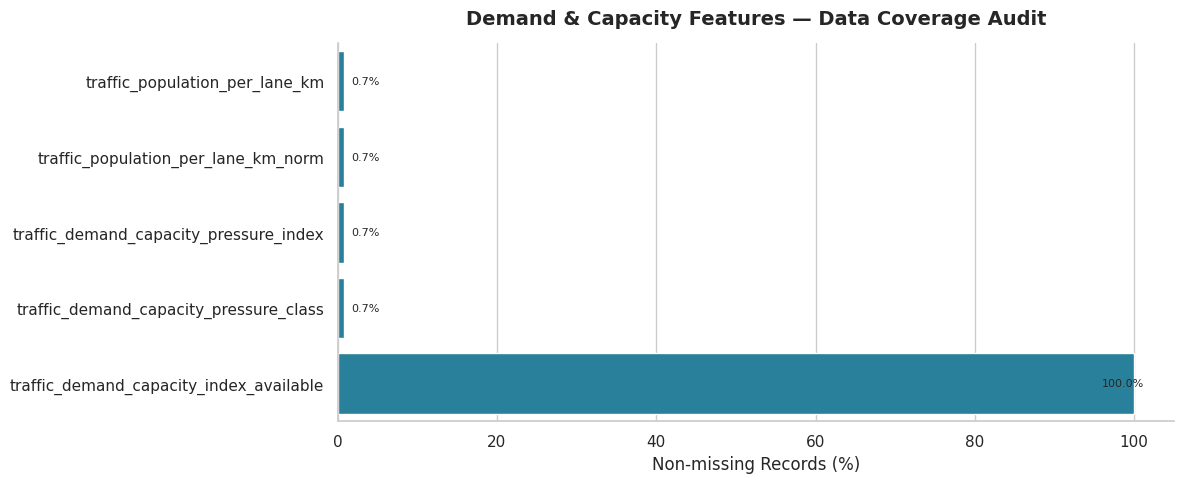

Matching columns found: 5

Exact column names:
traffic_population_per_lane_km: 26 non-missing values
traffic_population_per_lane_km_norm: 26 non-missing values
traffic_demand_capacity_pressure_index: 26 non-missing values
traffic_demand_capacity_pressure_class: 26 non-missing values
traffic_demand_capacity_index_available: 3488 non-missing values


In [43]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# البحث عن الأعمدة المحتمل ارتباطها بالطلب والسعة
keywords = [
    "demand", "capacity", "population_per_lane",
    "vehicle", "volume", "flow", "congestion"
]

matched_cols = [
    col for col in df.columns
    if any(word in col.lower() for word in keywords)
]

# حساب التغطية
coverage_df = pd.DataFrame({
    "Feature": matched_cols,
    "Available (%)": [
        df[col].notna().mean() * 100 for col in matched_cols
    ],
    "Non-missing": [
        int(df[col].notna().sum()) for col in matched_cols
    ]
}).sort_values("Available (%)", ascending=True)

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(12, max(5, len(coverage_df) * 0.32)))

sns.barplot(
    data=coverage_df,
    x="Available (%)",
    y="Feature",
    color="#168AAD",
    ax=ax
)

ax.set_title(
    "Demand & Capacity Features — Data Coverage Audit",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("Non-missing Records (%)")
ax.set_ylabel("")
ax.set_xlim(0, 105)

for i, value in enumerate(coverage_df["Available (%)"]):
    ax.text(
        min(value + 1, 96),
        i,
        f"{value:.1f}%",
        va="center",
        fontsize=8
    )

sns.despine()
plt.tight_layout()
plt.show()

print("Matching columns found:", len(matched_cols))
print("\nExact column names:")
for col in matched_cols:
    print(f"{col}: {df[col].notna().sum()} non-missing values")


### Target 2 — Core Variable Coverage Findings

The coverage audit identified five columns related to Target 2:
- **Core Target & Index**: `traffic_demand_capacity_pressure_index` and `traffic_demand_capacity_pressure_class`
- **Related Features**: `traffic_population_per_lane_km` (and its normalized version)
- **Availability Indicator**: `traffic_demand_capacity_index_available`

### Key Findings
- **Target & Index Coverage**: `traffic_demand_capacity_pressure_index`, `traffic_demand_capacity_pressure_class`, and `traffic_population_per_lane_km` contain only **26 non-missing values out of 3,489 records (~0.75%)**.
- **Indicator Availability**: `traffic_demand_capacity_index_available` contains **3,488 non-missing values**, confirming that availability metadata is recorded across almost the entire dataset despite the actual target values being scarce.
- **Coverage Limitation**: A substantial gap exists between availability tracking and actual target presence.

### Next Steps
1. Investigate whether limited coverage stems from indicator-generation logic, eligibility criteria, or upstream data missingness.
2. Refrain from imputing or reconstructing missing values until underlying calculation rules and data dependencies are fully verified.

Availability flag — all values:
traffic_demand_capacity_index_available
False    3462
True       26
NaN         1
Name: count, dtype: int64

Availability consistency audit:
              Total_rows  Index_available  Target_available  Index availability (%)  Target availability (%)
Flag                                                                                                        
False               3462                0                 0                     0.0                      0.0
Missing flag           1                0                 0                     0.0                      0.0
True                  26               26                26                   100.0                    100.0


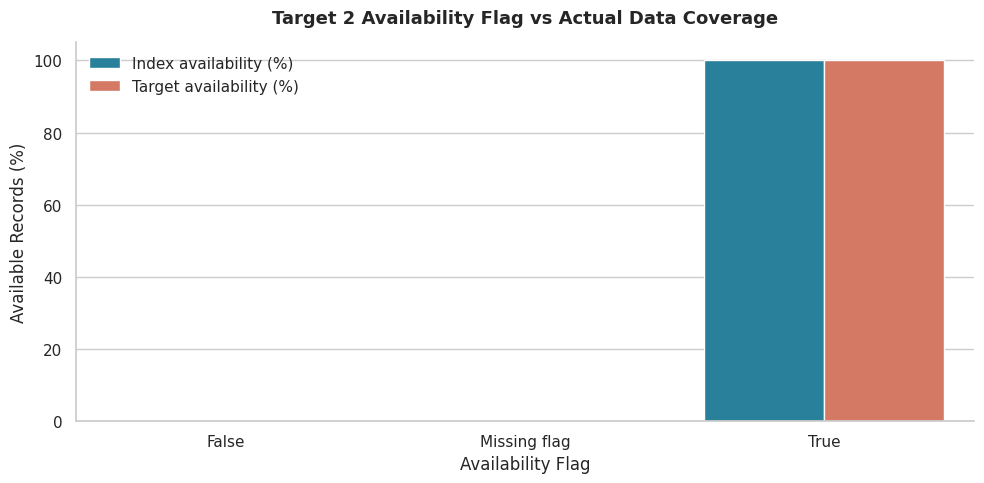

In [44]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

availability_col = "traffic_demand_capacity_index_available"
index_col = "traffic_demand_capacity_pressure_index"
target_col = "traffic_demand_capacity_pressure_class"

# فحص كل القيم الموجودة في مؤشر التوافر
print("Availability flag — all values:")
print(df[availability_col].value_counts(dropna=False))

# مقارنة توافر المؤشر الرقمي والتصنيف مع مؤشر التوافر
audit = pd.DataFrame({
    "Flag": df[availability_col].astype("string").fillna("Missing flag"),
    "Index available": df[index_col].notna(),
    "Target available": df[target_col].notna()
})

audit_summary = (
    audit.groupby("Flag", observed=False)
    .agg(
        Total_rows=("Flag", "size"),
        Index_available=("Index available", "sum"),
        Target_available=("Target available", "sum")
    )
)

audit_summary["Index availability (%)"] = (
    audit_summary["Index_available"] / audit_summary["Total_rows"] * 100
)
audit_summary["Target availability (%)"] = (
    audit_summary["Target_available"] / audit_summary["Total_rows"] * 100
)

print("\nAvailability consistency audit:")
print(audit_summary.round(2))

# رسم مقارنة نسب التوافر حسب قيمة العلم
plot_data = audit_summary[
    ["Index availability (%)", "Target availability (%)"]
].reset_index().melt(
    id_vars="Flag",
    var_name="Variable",
    value_name="Available (%)"
)

sns.set_theme(style="whitegrid", context="notebook")
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=plot_data,
    x="Flag",
    y="Available (%)",
    hue="Variable",
    palette=["#168AAD", "#E76F51"],
    ax=ax
)

ax.set_title(
    "Target 2 Availability Flag vs Actual Data Coverage",
    fontsize=13,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("Availability Flag")
ax.set_ylabel("Available Records (%)")
ax.set_ylim(0, 105)
ax.legend(title="", frameon=False)

sns.despine()
plt.tight_layout()
plt.show()


### Target 2 — Availability Flag Consistency Audit

The availability audit evaluated **3,489 records** across the dataset:

- **Flag = True**: 26 records (100% contain both `traffic_demand_capacity_pressure_index` and its corresponding target class).
- **Flag = False**: 3,462 records (100% have missing index and class values).
- **Flag = Missing**: 1 record (has missing index and class values).

### Audit Verdict
- **Inconsistencies Detected**: **0**
- **Data Alignment**: Perfect alignment between `traffic_demand_capacity_index_available` and actual target/index presence.
- **Core Bottleneck**: The primary challenge is severe coverage limitation (~0.75% coverage) rather than metadata mismatches.

### Recommendation
1. Focus downstream investigation on upstream data pipelines and eligibility rules governing demand-capacity index calculations.
2. Maintain strict data integrity—do not impute or backfill missing values prior to clarifying original calculation criteria.

Potential source features found: 120

Top 25 features by data coverage:
                         Feature  Available_Count  Coverage_Percent Data_Type
                  roads_latitude             3488         99.971338   float64
                 roads_longitude             3488         99.971338   float64
                  roads_area_km2             3488         99.971338   float64
                    roads_source             3488         99.971338    object
         roads_maxspeed_coverage             3488         99.971338   float64
            roads_reference_year             3488         99.971338   float64
            roads_lit_road_ratio             3488         99.971338   float64
              roads_tunnel_ratio             3488         99.971338   float64
              roads_bridge_ratio             3488         99.971338   float64
            roads_dead_end_ratio             3488         99.971338   float64
            roads_dead_end_count             3488         99.971338   

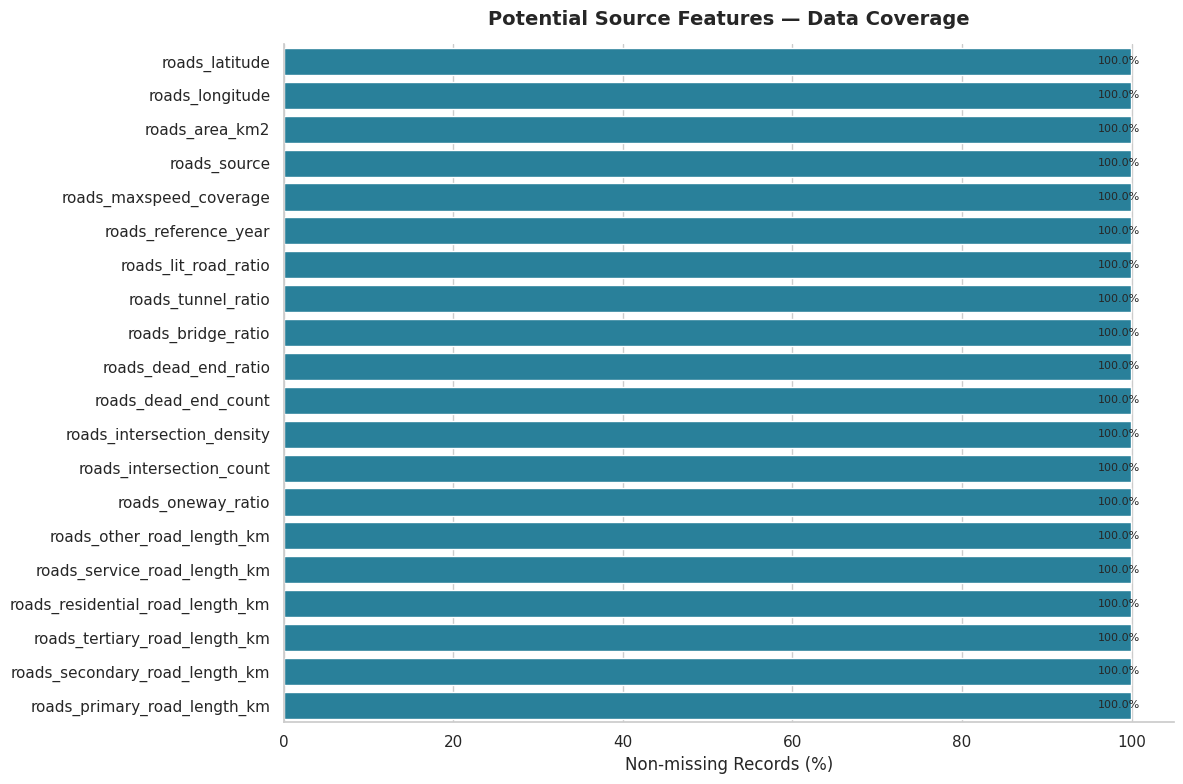

In [45]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# البحث عن الأعمدة المحتمل استخدامها كمصادر لحساب Target 2
source_keywords = [
    "traffic", "road", "population", "transit",
    "vehicle", "volume", "flow", "intersection",
    "lane", "speed", "congestion", "capacity", "demand"
]

source_cols = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in source_keywords)
]

source_audit = pd.DataFrame({
    "Feature": source_cols,
    "Available_Count": [df[col].notna().sum() for col in source_cols],
    "Coverage_Percent": [df[col].notna().mean() * 100 for col in source_cols],
    "Data_Type": [str(df[col].dtype) for col in source_cols]
})

# استبعاد أعمدة Target 2 نفسها لعرض المتغيرات المصدرية المحتملة
target_related = [
    "traffic_demand_capacity_pressure_index",
    "traffic_demand_capacity_pressure_class",
    "traffic_demand_capacity_index_available"
]

source_audit = source_audit[
    ~source_audit["Feature"].isin(target_related)
].sort_values("Coverage_Percent", ascending=False)

print("Potential source features found:", len(source_audit))
print("\nTop 25 features by data coverage:")
print(source_audit.head(25).to_string(index=False))

# رسم أفضل 20 متغيرًا من حيث التغطية
plot_df = source_audit.head(20).sort_values("Coverage_Percent")

sns.set_theme(style="whitegrid", context="notebook")
fig, ax = plt.subplots(figsize=(12, 8))

sns.barplot(
    data=plot_df,
    x="Coverage_Percent",
    y="Feature",
    color="#168AAD",
    ax=ax
)

ax.set_title(
    "Potential Source Features — Data Coverage",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("Non-missing Records (%)")
ax.set_ylabel("")
ax.set_xlim(0, 105)

for i, value in enumerate(plot_df["Coverage_Percent"]):
    ax.text(min(value + 1, 96), i, f"{value:.1f}%", va="center", fontsize=8)

sns.despine()
plt.tight_layout()
plt.show()


### Target 2 — Upstream Feature Coverage Audit

The audit evaluated **120 potential source features** across traffic, road network, population, transit, and transportation attributes:

- **High-Coverage Subset**: The top 25 features each contain **3,488 non-missing values out of 3,489 records (~99.97% coverage)**.
- **Available Attributes**: Foundational road-network variables are broadly present, including road geometry, road density, intersection characteristics, and category-specific road lengths.
- **Coverage Disconnect**: High availability of general infrastructure features does not imply that all specific inputs required for calculating the demand-capacity pressure index are present or sufficient for reconstruction.

### Key Takeaway & Next Steps
Broad road-network data exists across almost the entire dataset, meaning the ~0.75% bottleneck for Target 2 is localized to specific calculation inputs or business logic.

1. Inspect exact missingness patterns for specific `demand`, `capacity`, `population`, and `lane` variables.
2. Determine whether the limited Target 2 coverage stems from missing upstream primary inputs or restrictive index-generation rules.

Focused features found: 14

Feature coverage details:
                                Feature  Available_Count  Missing_Count  Coverage_Percent Data_Type
                     roads_avg_maxspeed               19           3470          0.544569   float64
                   traffic_avg_maxspeed               19           3470          0.544569   float64
         traffic_population_per_lane_km               26           3463          0.745199   float64
    traffic_population_per_lane_km_norm               26           3463          0.745199   float64
 traffic_demand_capacity_pressure_index               26           3463          0.745199   float64
 traffic_demand_capacity_pressure_class               26           3463          0.745199    object
                      traffic_avg_lanes               47           3442          1.347091   float64
                        roads_avg_lanes               47           3442          1.347091   float64
                          roads_lane_km       

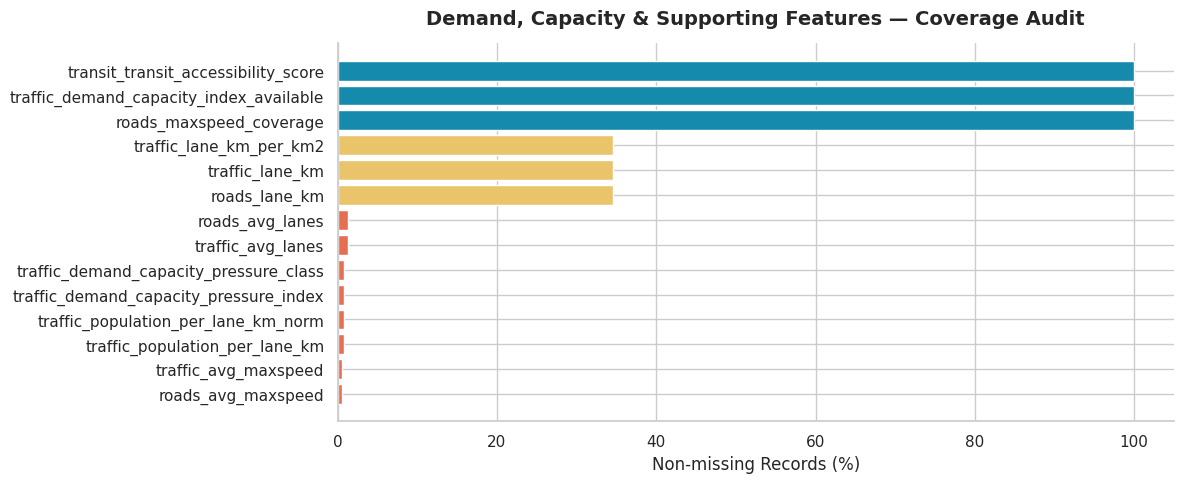

In [46]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# كلمات مرتبطة مباشرة بالمدخلات المحتملة لمؤشر الطلب والسعة
focused_keywords = [
    "demand", "capacity", "population_per_lane",
    "lane", "vehicle", "volume", "flow",
    "speed", "congestion", "transit_accessibility"
]

focused_cols = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in focused_keywords)
]

focused_audit = pd.DataFrame({
    "Feature": focused_cols,
    "Available_Count": [df[col].notna().sum() for col in focused_cols],
    "Missing_Count": [df[col].isna().sum() for col in focused_cols],
    "Coverage_Percent": [df[col].notna().mean() * 100 for col in focused_cols],
    "Data_Type": [str(df[col].dtype) for col in focused_cols]
}).sort_values("Coverage_Percent", ascending=True)

print("Focused features found:", len(focused_audit))
print("\nFeature coverage details:")
print(focused_audit.to_string(index=False))

# رسم التغطية مع إبراز الأعمدة ذات التغطية المحدودة
sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(
    figsize=(12, max(5, len(focused_audit) * 0.30))
)

colors = [
    "#E76F51" if value < 10 else
    "#E9C46A" if value < 80 else
    "#168AAD"
    for value in focused_audit["Coverage_Percent"]
]

ax.barh(
    focused_audit["Feature"],
    focused_audit["Coverage_Percent"],
    color=colors,
    edgecolor="white"
)

ax.set_title(
    "Demand, Capacity & Supporting Features — Coverage Audit",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("Non-missing Records (%)")
ax.set_ylabel("")
ax.set_xlim(0, 105)

sns.despine()
plt.tight_layout()
plt.show()


### Target 2 — Focused Feature Coverage Audit

A focused audit across **14 key features** related to demand, capacity, lanes, speed, and transit accessibility revealed the following coverage distribution across 3,489 records:

- **Target & Population-per-Lane Metrics (~0.75% Coverage)**:
  `traffic_demand_capacity_pressure_index`, `traffic_demand_capacity_pressure_class`, `traffic_population_per_lane_km`, and its normalized variant contain only **26 non-missing values**.
- **Speed Features (~0.54% Coverage)**:
  Average speed features contain only **19 non-missing values**, presenting the highest level of missingness among supporting predictors.
- **Lane-Related Features (~34.62% Coverage)**:
  `roads_lane_km`, `traffic_lane_km`, and `traffic_lane_km_per_km2` contain **1,208 non-missing values**, demonstrating moderate coverage across the dataset.
- **High-Coverage Infrastructure & Metadata (~99.97% Coverage)**:
  `roads_maxspeed_coverage`, `traffic_demand_capacity_index_available`, and `transit_transit_accessibility_score` each contain **3,488 non-missing values**.

### Key Takeaway & Next Steps
While high-level accessibility and speed-coverage metadata are near-complete, critical capacity inputs (lanes) are missing for ~65% of the data, and speed metrics are virtually absent.

1. Analyze whether the **26 labeled records** share distinct data-availability patterns or overlap with specific sub-regions.
2. Formally verify the exact upstream mathematical requirements of the target calculation prior to any target reconstruction or modeling attempts.

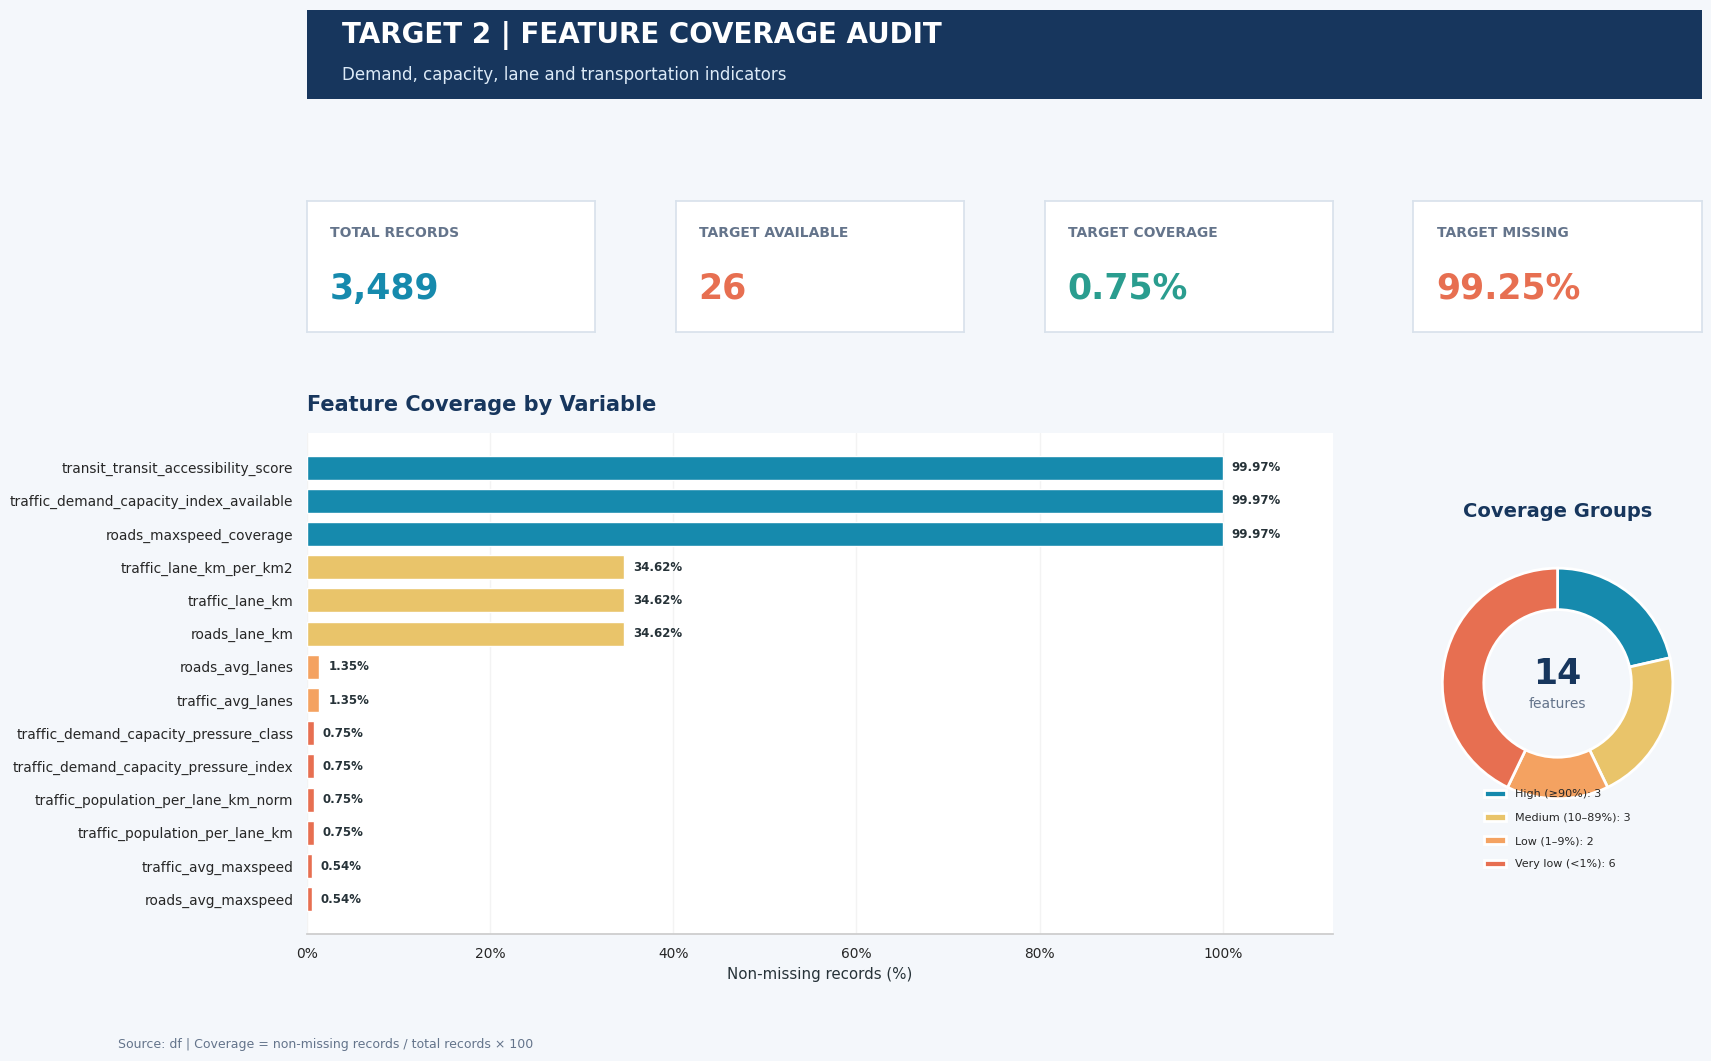

Records analyzed: 3,489
Features displayed: 14
Target available: 26 (0.75%)
Target missing: 3,463 (99.25%)


In [47]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# =========================
# 1. إعداد البيانات
# =========================
target_col = "traffic_demand_capacity_pressure_class"

focus_cols = [
    "roads_avg_maxspeed",
    "traffic_avg_maxspeed",
    "traffic_population_per_lane_km",
    "traffic_population_per_lane_km_norm",
    "traffic_demand_capacity_pressure_index",
    "traffic_demand_capacity_pressure_class",
    "traffic_avg_lanes",
    "roads_avg_lanes",
    "roads_lane_km",
    "traffic_lane_km",
    "traffic_lane_km_per_km2",
    "roads_maxspeed_coverage",
    "traffic_demand_capacity_index_available",
    "transit_transit_accessibility_score"
]

focus_cols = [c for c in focus_cols if c in df.columns]

audit = pd.DataFrame({
    "Feature": focus_cols,
    "Available": [df[c].notna().sum() for c in focus_cols],
    "Coverage": [df[c].notna().mean() * 100 for c in focus_cols]
})

audit = audit.sort_values("Coverage", ascending=True)

total_rows = len(df)
target_available = int(df[target_col].notna().sum())
target_coverage = df[target_col].notna().mean() * 100

# =========================
# 2. الثيم والألوان
# =========================
sns.set_theme(style="whitegrid", font_scale=0.9)

NAVY = "#17365D"
BLUE = "#168AAD"
TEAL = "#2A9D8F"
AMBER = "#E9C46A"
ORANGE = "#F4A261"
RED = "#E76F51"
LIGHT = "#F4F7FB"
DARK = "#263238"
GRAY = "#64748B"

def coverage_color(value):
    if value < 1:
        return RED
    elif value < 10:
        return ORANGE
    elif value < 90:
        return AMBER
    return BLUE

# =========================
# 3. تصميم لوحة التحليل
# =========================
fig = plt.figure(figsize=(18, 12), facecolor=LIGHT)

gs = fig.add_gridspec(
    nrows=3,
    ncols=4,
    height_ratios=[0.75, 1.1, 4.2],
    hspace=0.42,
    wspace=0.28
)

# العنوان الرئيسي
ax_title = fig.add_subplot(gs[0, :])
ax_title.set_facecolor(NAVY)
ax_title.set_xticks([])
ax_title.set_yticks([])
for spine in ax_title.spines.values():
    spine.set_visible(False)

ax_title.text(
    0.025, 0.63,
    "TARGET 2 | FEATURE COVERAGE AUDIT",
    color="white", fontsize=20, fontweight="bold",
    transform=ax_title.transAxes
)
ax_title.text(
    0.025, 0.22,
    "Demand, capacity, lane and transportation indicators",
    color="#DCEAF7", fontsize=12,
    transform=ax_title.transAxes
)

# مؤشرات KPI
kpis = [
    ("TOTAL RECORDS", f"{total_rows:,}", BLUE),
    ("TARGET AVAILABLE", f"{target_available:,}", RED),
    ("TARGET COVERAGE", f"{target_coverage:.2f}%", TEAL)
]

for i, (label, value, color) in enumerate(kpis):
    ax = fig.add_subplot(gs[1, i:i+1])
    ax.set_facecolor("white")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#D9E2EC")

    ax.text(
        0.08, 0.72, label,
        transform=ax.transAxes,
        fontsize=10, color=GRAY, fontweight="bold"
    )
    ax.text(
        0.08, 0.25, value,
        transform=ax.transAxes,
        fontsize=25, color=color, fontweight="bold"
    )

# مساحة KPI الرابعة: نسبة القيم المفقودة
ax = fig.add_subplot(gs[1, 3])
ax.set_facecolor("white")
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_color("#D9E2EC")

missing_pct = 100 - target_coverage
ax.text(
    0.08, 0.72, "TARGET MISSING",
    transform=ax.transAxes,
    fontsize=10, color=GRAY, fontweight="bold"
)
ax.text(
    0.08, 0.25, f"{missing_pct:.2f}%",
    transform=ax.transAxes,
    fontsize=25, color=RED, fontweight="bold"
)

# =========================
# 4. الرسم الرئيسي: تغطية المتغيرات
# =========================
ax1 = fig.add_subplot(gs[2, :3])
ax1.set_facecolor("white")

bar_colors = [coverage_color(v) for v in audit["Coverage"]]

bars = ax1.barh(
    audit["Feature"],
    audit["Coverage"],
    color=bar_colors,
    edgecolor="white",
    height=0.72
)

ax1.set_title(
    "Feature Coverage by Variable",
    loc="left", fontsize=15, fontweight="bold",
    color=NAVY, pad=16
)
ax1.set_xlabel("Non-missing records (%)", color=DARK)
ax1.set_ylabel("")
ax1.set_xlim(0, 112)
ax1.xaxis.set_major_formatter(PercentFormatter(xmax=100))

ax1.grid(axis="x", alpha=0.22)
ax1.grid(axis="y", visible=False)
ax1.set_axisbelow(True)

for bar, value in zip(bars, audit["Coverage"]):
    label_x = min(value + 1.0, 101)
    ax1.text(
        label_x,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=8.5,
        color=DARK,
        fontweight="bold"
    )

for spine in ["top", "right", "left"]:
    ax1.spines[spine].set_visible(False)

# =========================
# 5. لوحة جانبية: توزيع مستويات التغطية
# =========================
ax2 = fig.add_subplot(gs[2, 3])
ax2.set_facecolor("white")

coverage_groups = pd.Series({
    "High (≥90%)": int((audit["Coverage"] >= 90).sum()),
    "Medium (10–89%)": int(
        ((audit["Coverage"] >= 10) & (audit["Coverage"] < 90)).sum()
    ),
    "Low (1–9%)": int(
        ((audit["Coverage"] >= 1) & (audit["Coverage"] < 10)).sum()
    ),
    "Very low (<1%)": int((audit["Coverage"] < 1).sum())
})

group_colors = [BLUE, AMBER, ORANGE, RED]

wedges, _ = ax2.pie(
    coverage_groups.values,
    colors=group_colors,
    startangle=90,
    counterclock=False,
    wedgeprops={"width": 0.36, "edgecolor": "white", "linewidth": 2}
)

ax2.text(
    0, 0.08, str(len(audit)),
    ha="center", va="center",
    fontsize=25, fontweight="bold", color=NAVY
)
ax2.text(
    0, -0.18, "features",
    ha="center", va="center",
    fontsize=10, color=GRAY
)

ax2.set_title(
    "Coverage Groups",
    fontsize=14, fontweight="bold",
    color=NAVY, pad=16
)

legend_labels = [
    f"{name}: {count}"
    for name, count in coverage_groups.items()
]

ax2.legend(
    wedges,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.18),
    frameon=False,
    fontsize=8,
    labelspacing=1.2
)

# التذييل
fig.text(
    0.02, 0.015,
    "Source: df | Coverage = non-missing records / total records × 100",
    fontsize=9, color=GRAY
)

plt.show()

print(f"Records analyzed: {total_rows:,}")
print(f"Features displayed: {len(audit)}")
print(f"Target available: {target_available:,} ({target_coverage:.2f}%)")
print(f"Target missing: {df[target_col].isna().sum():,} ({missing_pct:.2f}%)")


### Target 2 — Dashboard Summary and Coverage Assessment

The feature coverage dashboard evaluated **3,489 records** across **14 selected features** encompassing demand, capacity, lane infrastructure, speed, and general transportation attributes:

- **Target Coverage**: **26 records (~0.75%)** with valid target labels.
- **Target Missingness**: **3,463 records (~99.25%)** missing target labels.
- **Analyzed Feature Scope**: 14 key transportation metrics.

### Key Takeaway
The visual assessment confirms a severe coverage bottleneck for Target 2. While high-level transportation indicators display broad availability across the dataset, essential lane infrastructure and demand-capacity predictors suffer from widespread missingness.

### Modeling Verdict & Next Steps
- **Modeling Status**: **Not Recommended**. A sample size of 26 labeled instances is insufficient for training a robust or generalizable supervised classification model.
- **Action Plan**:
  1. Audit the data-generation pipeline to identify exact upstream prerequisites for target computation.
  2. Avoid imputing missing values or assuming the 26 labeled records represent the broader dataset population.

Geographic/grouping columns found: ['roads_source', 'h3_index']

--- roads_source ---
Unique values: 1
Available-target rows with non-missing value: 26

--- h3_index ---
Unique values: 3489
Available-target rows with non-missing value: 26


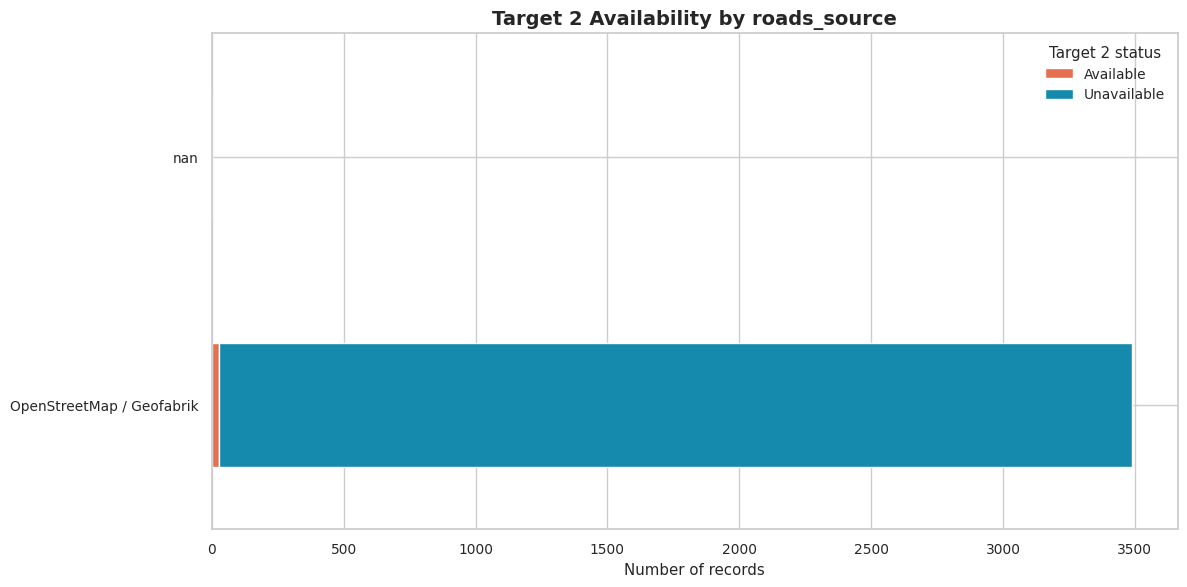

In [48]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_col = "traffic_demand_capacity_pressure_class"

# تحديد الأعمدة الجغرافية المتاحة
geo_candidates = [
    "district",
    "district_name",
    "roads_source",
    "district_assignment_method",
    "h3_index"
]

geo_cols = [c for c in geo_candidates if c in df.columns]

print("Geographic/grouping columns found:", geo_cols)

# تجهيز مجموعة الصفوف المتاحة
available_df = df[df[target_col].notna()].copy()

if not geo_cols:
    print("No candidate geographic/grouping columns found.")
else:
    # عرض عدد القيم المختلفة ونسب التغطية لكل عمود
    for col in geo_cols:
        print(f"\n--- {col} ---")
        print("Unique values:", df[col].nunique(dropna=True))
        print("Available-target rows with non-missing value:",
              available_df[col].notna().sum())

    # رسم توزيع توافر Target 2 حسب الأعمدة الفئوية ذات عدد مجموعات مناسب
    categorical_cols = [
        c for c in geo_cols
        if df[c].nunique(dropna=True) <= 25
        and c != "h3_index"
    ]

    if categorical_cols:
        col = categorical_cols[0]

        temp = df[[col, target_col]].copy()
        temp["Target 2 status"] = temp[target_col].notna().map({
            True: "Available",
            False: "Unavailable"
        })

        summary = (
            temp.groupby([col, "Target 2 status"], dropna=False)
            .size()
            .unstack(fill_value=0)
        )

        summary["Total"] = summary.sum(axis=1)
        summary = summary.sort_values("Total", ascending=False).head(15)

        plot_data = summary.drop(columns="Total")
        plot_data.plot(
            kind="barh",
            stacked=True,
            figsize=(12, 6),
            color=["#E76F51", "#168AAD"]
        )

        plt.title(
            f"Target 2 Availability by {col}",
            fontsize=14,
            fontweight="bold"
        )
        plt.xlabel("Number of records")
        plt.ylabel("")
        plt.legend(title="Target 2 status", frameon=False)
        plt.tight_layout()
        plt.show()
    else:
        print(
            "No low-cardinality categorical grouping column found. "
            "Inspect the printed columns before selecting a grouping variable."
        )


### Target 2 — Geographic and Grouping Audit

The geographic and grouping audit evaluated two spatial metadata attributes across **3,489 records**:

- **`roads_source`**: Contains only **1 unique value**, with all 26 Target 2 labeled records possessing non-missing values. Because this feature lacks variance, it cannot explain differences in target availability across data suppliers or sources.
- **`h3_index`**: Contains **3,489 unique values** (1:1 record-to-cell mapping), with all 26 labeled records possessing a valid H3 spatial index.
- **Overall Coverage**: Target 2 remains available for only **26 records (~0.75%)**, leaving **3,463 records (~99.25%)** missing target labels.

### Key Takeaway
The available grouping variables do not explain the severe target missingness. While `h3_index` uniquely identifies each spatial cell, it does not inherently reveal whether the 26 available records form geographic clusters or are randomly dispersed across the study area.

### Next Steps
1. Map and inspect the explicit spatial coordinates / H3 cell locations of the 26 labeled records to test for geographic clustering.
2. Cross-reference spatial boundaries against upstream data coverage maps to isolate regional collection gaps.
3. Review target-generation logic and upstream input requirements before attempting any missing value reconstruction.

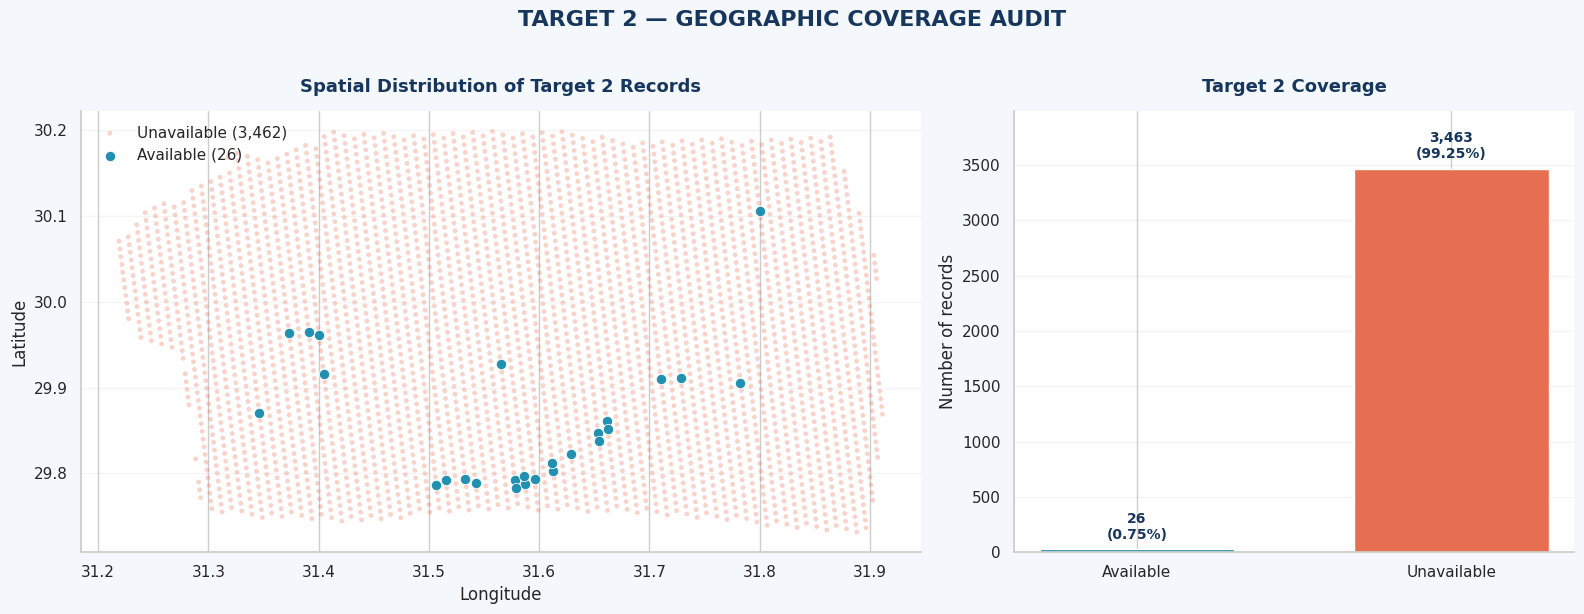

Records in df: 3489
Rows with valid coordinates: 3488
Target available: 26
Target unavailable: 3463
Unique H3 indices: 3489


In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =========================
# إعداد البيانات
# =========================
target_col = "traffic_demand_capacity_pressure_class"
lat_col = "roads_latitude"
lon_col = "roads_longitude"

required_cols = [target_col, lat_col, lon_col]
missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    print("Required columns not found:", missing_cols)
else:
    plot_df = df[required_cols].copy()
    plot_df["Target 2 status"] = plot_df[target_col].notna().map({
        True: "Available",
        False: "Unavailable"
    })

    plot_df = plot_df.dropna(subset=[lat_col, lon_col])

    # =========================
    # الثيم والألوان
    # =========================
    sns.set_theme(style="whitegrid", context="notebook")

    NAVY = "#17365D"
    BLUE = "#168AAD"
    CORAL = "#E76F51"
    LIGHT = "#F4F7FB"

    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 6),
        gridspec_kw={"width_ratios": [1.5, 1]}
    )
    fig.patch.set_facecolor(LIGHT)

    # =========================
    # الرسم الأول: التوزيع المكاني
    # =========================
    ax = axes[0]
    ax.set_facecolor("white")

    unavailable = plot_df[
        plot_df["Target 2 status"] == "Unavailable"
    ]
    available = plot_df[
        plot_df["Target 2 status"] == "Available"
    ]

    ax.scatter(
        unavailable[lon_col],
        unavailable[lat_col],
        s=12,
        alpha=0.30,
        color=CORAL,
        label=f"Unavailable ({len(unavailable):,})",
        edgecolors="none"
    )

    ax.scatter(
        available[lon_col],
        available[lat_col],
        s=55,
        alpha=0.95,
        color=BLUE,
        label=f"Available ({len(available):,})",
        edgecolors="white",
        linewidths=0.6
    )

    ax.set_title(
        "Spatial Distribution of Target 2 Records",
        fontsize=13,
        fontweight="bold",
        color=NAVY,
        pad=14
    )
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(frameon=False, loc="best")

    # =========================
    # الرسم الثاني: التغطية
    # =========================
    ax = axes[1]
    ax.set_facecolor("white")

    counts = (
        df[target_col]
        .notna()
        .value_counts()
        .reindex([True, False], fill_value=0)
    )

    labels = ["Available", "Unavailable"]
    values = [counts[True], counts[False]]
    colors = [BLUE, CORAL]

    bars = ax.bar(
        labels,
        values,
        color=colors,
        width=0.62,
        edgecolor="white"
    )

    ax.set_title(
        "Target 2 Coverage",
        fontsize=13,
        fontweight="bold",
        color=NAVY,
        pad=14
    )
    ax.set_ylabel("Number of records")
    ax.set_ylim(0, max(values) * 1.15)

    for bar, value in zip(bars, values):
        percentage = value / len(df) * 100
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(values) * 0.02,
            f"{value:,}\n({percentage:.2f}%)",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            color=NAVY
        )

    for ax in axes:
        ax.grid(axis="y", alpha=0.20)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig.suptitle(
        "TARGET 2 — GEOGRAPHIC COVERAGE AUDIT",
        fontsize=16,
        fontweight="bold",
        color=NAVY,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

    print("Records in df:", len(df))
    print("Rows with valid coordinates:", len(plot_df))
    print("Target available:", int(df[target_col].notna().sum()))
    print("Target unavailable:", int(df[target_col].isna().sum()))
    print("Unique H3 indices:", df["h3_index"].nunique())


### Target 2 — Geographic Coverage Audit

The geographic coverage audit evaluated coordinate completeness and spatial indexing across **3,489 records**:

- **Valid Coordinates**: **3,488 records (~99.97%)** contain valid latitude and longitude values.
- **Target 2 Availability**: **26 records (~0.75%)** labeled; **3,463 records (~99.25%)** missing target values.
- **Spatial Indexing**: **3,489 unique `h3_index` values** present in the dataset.

### Key Takeaway
Coordinate missingness is **not** the primary driver of Target 2 unavailability, as virtually the entire dataset possesses valid spatial coordinates. However, the high uniqueness of `h3_index` does not by itself clarify whether the 26 available records are spatially clustered or dispersed.

### Next Steps
1. Map the spatial distribution of the 26 available records against the 3,463 unavailable records to evaluate geographic clustering.
2. If no spatial pattern emerges, shift priority to auditing the upstream input metrics and underlying business logic used to generate the demand-capacity pressure index.

Geographic cells with at least 5 records: 0
Cells containing available Target 2: 0
Total available Target 2 records in retained cells: 0


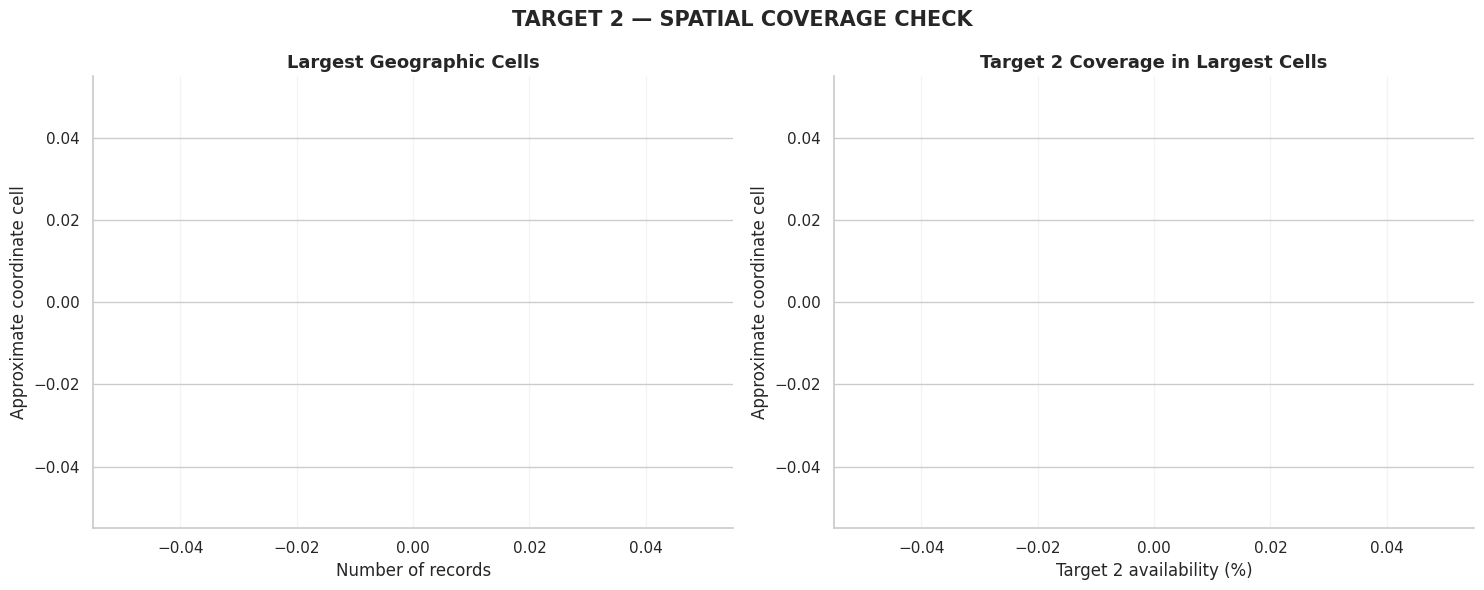

In [50]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

target_col = "traffic_demand_capacity_pressure_class"
lat_col = "roads_latitude"
lon_col = "roads_longitude"

geo_df = df[[lat_col, lon_col, target_col]].copy()
geo_df = geo_df.dropna(subset=[lat_col, lon_col])

# تقسيم الإحداثيات إلى شبكة تقريبية
# تقريب الإحداثيات إلى منزلتين عشريتين لتجميع النقاط القريبة
geo_df["geo_cell"] = (
    geo_df[lat_col].round(2).astype(str)
    + ", "
    + geo_df[lon_col].round(2).astype(str)
)

geo_df["target_available"] = geo_df[target_col].notna()

cell_summary = (
    geo_df.groupby("geo_cell")
    .agg(
        total_records=("target_available", "size"),
        target_available=("target_available", "sum")
    )
)

cell_summary["coverage_pct"] = (
    cell_summary["target_available"]
    / cell_summary["total_records"] * 100
)

# التركيز على الخلايا التي تضم 5 سجلات على الأقل
cell_summary = cell_summary[
    cell_summary["total_records"] >= 5
].copy()

print("Geographic cells with at least 5 records:", len(cell_summary))
print("Cells containing available Target 2:", int((cell_summary["target_available"] > 0).sum()))
print("Total available Target 2 records in retained cells:", int(cell_summary["target_available"].sum()))

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# الرسم الأول: عدد السجلات في الخلايا الجغرافية
top_cells = cell_summary.sort_values(
    "total_records", ascending=False
).head(15).sort_values("total_records")

axes[0].barh(
    top_cells.index,
    top_cells["total_records"],
    color="#168AAD"
)
axes[0].set_title(
    "Largest Geographic Cells",
    fontsize=13,
    fontweight="bold"
)
axes[0].set_xlabel("Number of records")
axes[0].set_ylabel("Approximate coordinate cell")

# الرسم الثاني: نسبة Target 2 المتاحة في الخلايا الأكبر
coverage_cells = cell_summary.sort_values(
    "total_records", ascending=False
).head(15).sort_values("coverage_pct")

axes[1].barh(
    coverage_cells.index,
    coverage_cells["coverage_pct"],
    color=[
        "#E76F51" if v == 0 else "#2A9D8F"
        for v in coverage_cells["coverage_pct"]
    ]
)
axes[1].set_title(
    "Target 2 Coverage in Largest Cells",
    fontsize=13,
    fontweight="bold"
)
axes[1].set_xlabel("Target 2 availability (%)")
axes[1].set_ylabel("Approximate coordinate cell")

for ax in axes:
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "TARGET 2 — SPATIAL COVERAGE CHECK",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


### Target 2 — Spatial Coverage Check: Plotting Issue

An audit of the initial spatial grouping visualization identified a plotting limitation related to the aggregation strategy:

- **Empty Visualization Artifact**: The visual produced empty charts because zero geographic cells met the arbitrary minimum threshold of 5 records after coordinates were rounded to 2 decimal places.
- **Root Cause**: This outcome stems strictly from the aggregation and threshold parameters chosen for the plot, rather than underlying spatial data missingness.
- **Data Reality**: The dataset retains **3,488 records with valid coordinates**, including all **26 records with available Target 2 labels**.

### Technical Takeaway & Next Steps
Rounding coordinates to 2 decimal places combined with a frequency filter (>5 records per bin) artificially erased sparse spatial points from the rendering pipeline.

1. Revise the spatial visualization strategy by removing the minimum record threshold per geographic cell.
2. Render raw latitude and longitude coordinates directly to compare records with available vs. unavailable Target 2 labels.
3. Evaluate spatial overlay maps to determine if labeled records exhibit explicit geographical clustering or spatial dispersion.

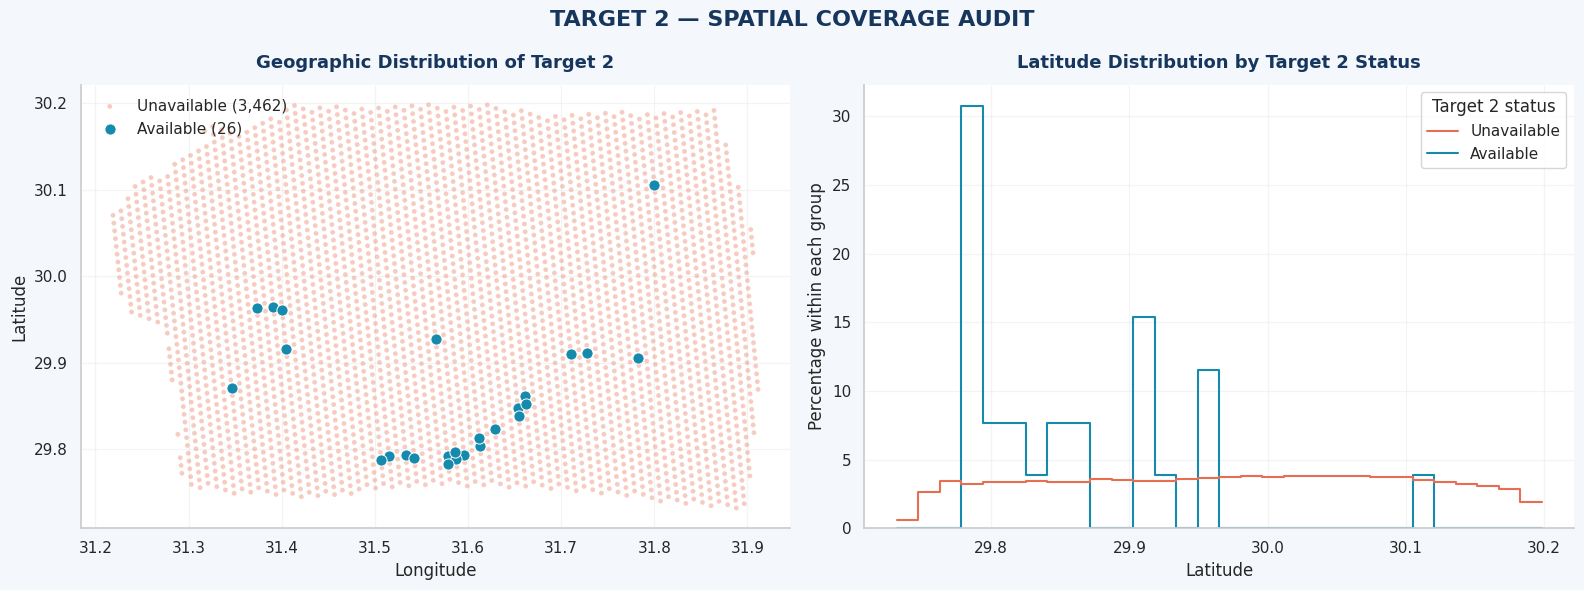

Rows plotted: 3488
Available Target 2: 26
Unavailable Target 2: 3462


In [51]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_col = "traffic_demand_capacity_pressure_class"
lat_col = "roads_latitude"
lon_col = "roads_longitude"

# تجهيز الإحداثيات وحالة توافر Target 2
plot_df = df[[lat_col, lon_col, target_col]].copy()
plot_df = plot_df.dropna(subset=[lat_col, lon_col])

plot_df["Target 2 status"] = plot_df[target_col].notna().map({
    True: "Available",
    False: "Unavailable"
})

sns.set_theme(style="whitegrid", context="notebook")

NAVY = "#17365D"
BLUE = "#168AAD"
CORAL = "#E76F51"
LIGHT = "#F4F7FB"

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    facecolor=LIGHT
)

# الرسم الأول: المواقع الجغرافية لكل الصفوف
ax = axes[0]
ax.set_facecolor("white")

unavailable = plot_df[plot_df["Target 2 status"] == "Unavailable"]
available = plot_df[plot_df["Target 2 status"] == "Available"]

ax.scatter(
    unavailable[lon_col],
    unavailable[lat_col],
    s=12,
    alpha=0.35,
    color=CORAL,
    label=f"Unavailable ({len(unavailable):,})",
    edgecolors="none"
)

ax.scatter(
    available[lon_col],
    available[lat_col],
    s=65,
    alpha=1,
    color=BLUE,
    label=f"Available ({len(available):,})",
    edgecolors="white",
    linewidths=0.7,
    zorder=3
)

ax.set_title(
    "Geographic Distribution of Target 2",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=12
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(frameon=False)

# الرسم الثاني: توزيع خطوط العرض للمجموعتين
ax = axes[1]
ax.set_facecolor("white")

sns.histplot(
    data=plot_df,
    x=lat_col,
    hue="Target 2 status",
    hue_order=["Unavailable", "Available"],
    bins=30,
    stat="percent",
    common_norm=False,
    element="step",
    fill=False,
    palette={
        "Unavailable": CORAL,
        "Available": BLUE
    },
    ax=ax
)

ax.set_title(
    "Latitude Distribution by Target 2 Status",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=12
)
ax.set_xlabel("Latitude")
ax.set_ylabel("Percentage within each group")

for ax in axes:
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "TARGET 2 — SPATIAL COVERAGE AUDIT",
    fontsize=16,
    fontweight="bold",
    color=NAVY
)

plt.tight_layout()
plt.show()

print("Rows plotted:", len(plot_df))
print("Available Target 2:", len(available))
print("Unavailable Target 2:", len(unavailable))


### Target 2 — Spatial Coverage Analysis

The spatial coverage audit evaluated **3,488 records with valid geographic coordinates**, comparing **26 records with available Target 2 labels** against **3,462 unavailable records**:

- **Spatial Distribution**: The geographic scatter plot reveals that the 26 available Target 2 records are dispersed across multiple geographic locations rather than strictly clustered within a single localized site. However, the small sample size limits the statistical robustness of visual observations.
- **Latitude Variations**: While minor distributional shifts in latitude exist between available and unavailable groups, these differences remain exploratory given the limited sample size ($n = 26$).
- **Overall Coverage**: Spatial coordinates are near-complete across the dataset (~99.97%), confirming that coordinate missingness is not the bottleneck behind Target 2 unavailability (~99.25% missingness).

### Conclusion & Next Steps
Spatial location alone does not explain why Target 2 is unavailable for 99.25% of records. Downstream efforts must pivot from spatial auditing to inspecting the core computational pipeline.

1. Inspect upstream data-generation logic to trace how the demand-capacity pressure index is computed.
2. Verify specific variable dependencies and eligibility criteria required to calculate Target 2.
3. Determine whether missingness originates from upstream data gaps or restrictive calculation rules prior to any modeling or imputation attempts.

Candidate input features: 6

Highest-coverage candidate features:
                               Feature  Overall coverage (%)  Available target rows (%)  Unavailable target rows (%)
   transit_transit_accessibility_score                 99.97                      100.0                        99.97
                       traffic_lane_km                 34.62                      100.0                        34.13
                         roads_lane_km                 34.62                      100.0                        34.13
               traffic_lane_km_per_km2                 34.62                      100.0                        34.13
traffic_demand_capacity_pressure_index                  0.75                      100.0                         0.00
        traffic_population_per_lane_km                  0.75                      100.0                         0.00


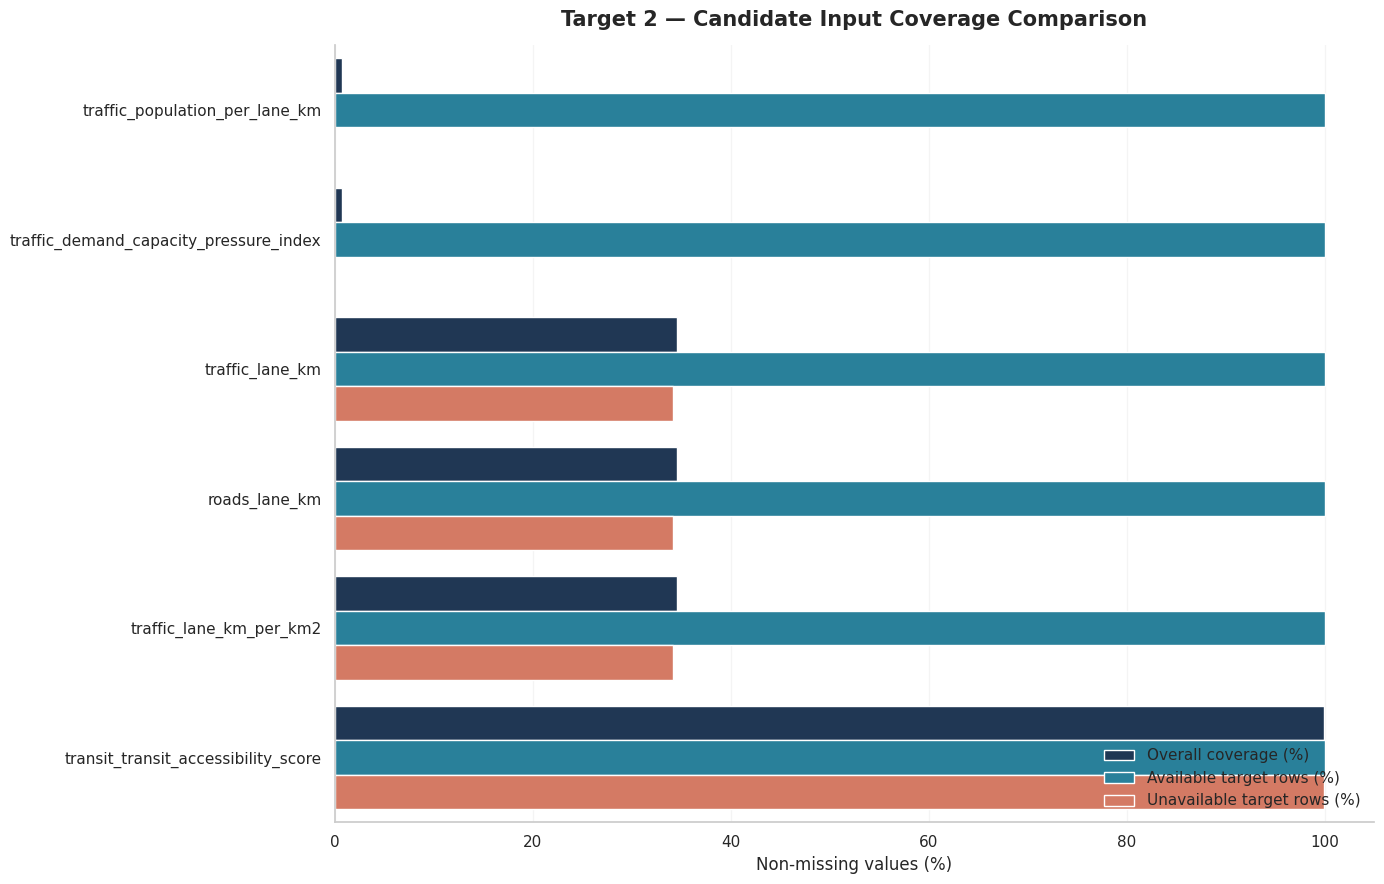

In [52]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_col = "traffic_demand_capacity_pressure_class"
flag_col = "traffic_demand_capacity_index_available"

# الأعمدة المرشحة التي قد تدخل في حساب مؤشر الطلب والسعة
candidate_keywords = [
    "demand", "capacity", "population_per_lane",
    "lane_km", "vehicle", "volume", "flow",
    "congestion", "transit_accessibility"
]

candidate_cols = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in candidate_keywords)
    and col not in [target_col, flag_col]
    and not col.endswith("_norm")
]

available_mask = df[target_col].notna()

audit_rows = []

for col in candidate_cols:
    audit_rows.append({
        "Feature": col,
        "Overall coverage (%)": df[col].notna().mean() * 100,
        "Available target rows (%)": (
            df.loc[available_mask, col].notna().mean() * 100
            if available_mask.sum() > 0 else 0
        ),
        "Unavailable target rows (%)": (
            df.loc[~available_mask, col].notna().mean() * 100
        )
    })

audit_df = pd.DataFrame(audit_rows)

if audit_df.empty:
    print("No candidate input columns found.")
else:
    # ترتيب الأعمدة حسب التغطية الإجمالية
    audit_df = audit_df.sort_values(
        "Overall coverage (%)",
        ascending=True
    )

    print("Candidate input features:", len(audit_df))
    print("\nHighest-coverage candidate features:")
    print(
        audit_df.sort_values(
            "Overall coverage (%)",
            ascending=False
        ).head(15).round(2).to_string(index=False)
    )

    # رسم مقارنة التغطية
    plot_df = audit_df.tail(20).melt(
        id_vars="Feature",
        value_vars=[
            "Overall coverage (%)",
            "Available target rows (%)",
            "Unavailable target rows (%)"
        ],
        var_name="Coverage group",
        value_name="Coverage (%)"
    )

    sns.set_theme(style="whitegrid", context="notebook")

    fig, ax = plt.subplots(figsize=(14, 9))

    sns.barplot(
        data=plot_df,
        x="Coverage (%)",
        y="Feature",
        hue="Coverage group",
        palette=["#17365D", "#168AAD", "#E76F51"],
        ax=ax
    )

    ax.set_title(
        "Target 2 — Candidate Input Coverage Comparison",
        fontsize=15,
        fontweight="bold",
        pad=14
    )
    ax.set_xlabel("Non-missing values (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 105)
    ax.legend(title="", frameon=False, loc="lower right")

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()


### Target 2 — Candidate Input Coverage Analysis

The candidate input audit evaluated **six features** potentially tied to the demand-capacity pressure calculation across **3,489 records**:

- **High-Coverage Feature (~99.97% Overall)**:
  `transit_transit_accessibility_score` is present for 3,488 records overall and covers **100% (26/26)** of the Target 2 labeled subset.
- **Moderate-Coverage Features (~34.62% Overall)**:
  `traffic_lane_km`, `roads_lane_km`, and `traffic_lane_km_per_km2` are each present in **1,208 records**. Crucially, **all 26 labeled records** possess complete data for these lane metrics.
- **Low-Coverage Features (~0.75% Overall)**:
  `traffic_population_per_lane_km` and `traffic_demand_capacity_pressure_index` are present in **only 26 records**, perfectly co-occurring with the target label and missing across all remaining 3,463 records.

### Key Takeaway
The complete alignment between target presence and `traffic_population_per_lane_km` indicates that target missingness is directly linked to the scarcity of underlying population-per-lane metrics. However, this coverage audit alone cannot confirm whether missing upstream data, restrictive eligibility thresholds, or an incomplete execution of the index-generation pipeline caused the label scarcity.

### Conclusion & Next Steps
- **Modeling & Imputation Status**: **Strictly On Hold**. Reconstructing target labels or training a classification model without validating the underlying calculation requirements risks propagating pipeline errors.
- **Action Item**: Inspect the original feature-engineering and pipeline codebase to determine the exact formula, prerequisites, and filtering logic applied during the generation of `traffic_demand_capacity_pressure_index` and `traffic_demand_capacity_pressure_class`.

Matched columns: 8

All matching columns:
                                Feature  Non-missing  Missing  Coverage (%) Data type
         traffic_population_per_lane_km           26     3463      0.745199   float64
 traffic_demand_capacity_pressure_class           26     3463      0.745199    object
 traffic_demand_capacity_pressure_index           26     3463      0.745199   float64
    traffic_population_per_lane_km_norm           26     3463      0.745199   float64
                traffic_lane_km_per_km2         1208     2281     34.623101   float64
                        traffic_lane_km         1208     2281     34.623101   float64
                          roads_lane_km         1208     2281     34.623101   float64
traffic_demand_capacity_index_available         3488        1     99.971338    object


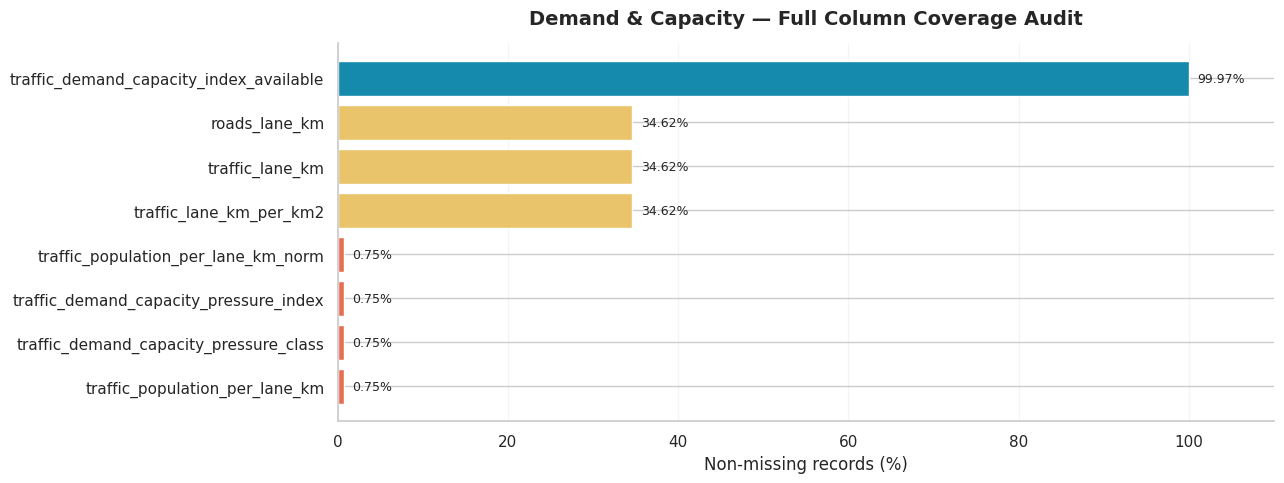

In [53]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# البحث عن جميع الأعمدة التي قد ترتبط بالطلب والسعة
keywords = [
    "demand",
    "capacity",
    "population_per_lane",
    "lane_km",
    "vehicle",
    "volume",
    "flow"
]

matched_cols = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in keywords)
]

audit = pd.DataFrame({
    "Feature": matched_cols,
    "Non-missing": [int(df[col].notna().sum()) for col in matched_cols],
    "Missing": [int(df[col].isna().sum()) for col in matched_cols],
    "Coverage (%)": [df[col].notna().mean() * 100 for col in matched_cols],
    "Data type": [str(df[col].dtype) for col in matched_cols]
})

audit = audit.sort_values("Coverage (%)", ascending=True)

print("Matched columns:", len(audit))
print("\nAll matching columns:")
print(audit.to_string(index=False))

# رسم تغطية الأعمدة
if not audit.empty:
    sns.set_theme(style="whitegrid", context="notebook")

    fig, ax = plt.subplots(
        figsize=(13, max(5, len(audit) * 0.35))
    )

    colors = [
        "#E76F51" if value < 1
        else "#E9C46A" if value < 80
        else "#168AAD"
        for value in audit["Coverage (%)"]
    ]

    bars = ax.barh(
        audit["Feature"],
        audit["Coverage (%)"],
        color=colors,
        edgecolor="white"
    )

    ax.set_title(
        "Demand & Capacity — Full Column Coverage Audit",
        fontsize=14,
        fontweight="bold",
        pad=14
    )
    ax.set_xlabel("Non-missing records (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 110)

    for bar, value in zip(bars, audit["Coverage (%)"]):
        ax.text(
            min(value + 1, 101),
            bar.get_y() + bar.get_height() / 2,
            f"{value:.2f}%",
            va="center",
            fontsize=9
        )

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()
else:
    print("No matching columns found.")


### Target 2 — Demand and Capacity Column Audit

The column audit evaluated **eight key features** related to demand, capacity, and lane-based transportation metrics across **3,489 records**:

- **Target & Population-per-Lane Metrics (~0.75% Coverage)**:
  `traffic_demand_capacity_pressure_index`, `traffic_demand_capacity_pressure_class`, `traffic_population_per_lane_km`, and its normalized version each contain **only 26 non-missing values**.
- **Lane Infrastructure Features (~34.62% Coverage)**:
  `traffic_lane_km`, `roads_lane_km`, and `traffic_lane_km_per_km2` each contain **1,208 non-missing values**, representing moderate coverage across the dataset.
- **Availability Metadata (~99.97% Coverage)**:
  `traffic_demand_capacity_index_available` contains **3,488 non-missing values**, providing comprehensive tracking metadata across virtually all records.

### Key Takeaway
The exact alignment in missing-value patterns between the target index and `traffic_population_per_lane_km` strongly suggests shared upstream dependencies or common calculation prerequisites. However, the column-level audit alone cannot establish the underlying mathematical formula or specific business logic used to compute the index.

### Conclusion & Next Steps
- **Modeling Status**: **Not Feasible**. The current labeled coverage (26 records) is insufficient for supervised classification modeling.
- **Action Item**: Inspect the original feature-engineering scripts to clarify input dependencies and eligibility criteria before attempting target reconstruction, imputation, or class prediction.

Lane data vs Target 2 availability:
Target 2 status      Available  Unavailable
Lane data status                           
Lane data available         26         1182
Lane data missing            0         2281

Target 2 coverage within each lane-data group (%):
Lane data status
Lane data available    2.15
Lane data missing      0.00
Name: traffic_demand_capacity_pressure_class, dtype: float64


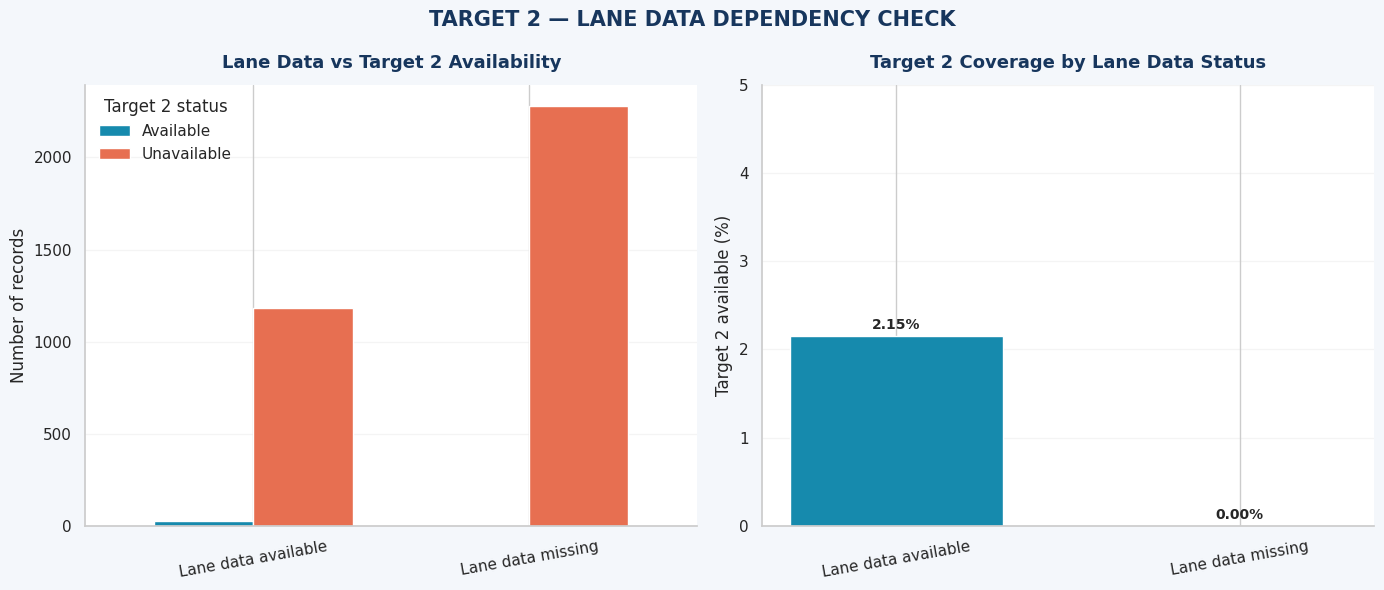


Total records: 3489
Target 2 available: 26
Lane data available: 1208


In [54]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_col = "traffic_demand_capacity_pressure_class"
lane_col = "traffic_lane_km"
index_col = "traffic_demand_capacity_pressure_index"

# تجهيز مجموعات التوافر
audit_df = df[[target_col, lane_col, index_col]].copy()

audit_df["Target 2 status"] = audit_df[target_col].notna().map({
    True: "Available",
    False: "Unavailable"
})

audit_df["Lane data status"] = audit_df[lane_col].notna().map({
    True: "Lane data available",
    False: "Lane data missing"
})

# ملخص التوافر
summary = pd.crosstab(
    audit_df["Lane data status"],
    audit_df["Target 2 status"]
).reindex(
    index=["Lane data available", "Lane data missing"],
    columns=["Available", "Unavailable"],
    fill_value=0
)

print("Lane data vs Target 2 availability:")
print(summary)

# حساب نسبة Target 2 المتاحة داخل كل مجموعة
coverage_by_lane = (
    audit_df.groupby("Lane data status", observed=False)[target_col]
    .apply(lambda s: s.notna().mean() * 100)
)

print("\nTarget 2 coverage within each lane-data group (%):")
print(coverage_by_lane.round(2))

# رسمان في لوحة واحدة
sns.set_theme(style="whitegrid", context="notebook")

NAVY = "#17365D"
BLUE = "#168AAD"
CORAL = "#E76F51"
LIGHT = "#F4F7FB"

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    facecolor=LIGHT
)

# الرسم الأول: عدد الصفوف حسب توافر Lane Data وTarget 2
summary.plot(
    kind="bar",
    ax=axes[0],
    color=[BLUE, CORAL],
    edgecolor="white",
    width=0.72
)

axes[0].set_title(
    "Lane Data vs Target 2 Availability",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=12
)
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of records")
axes[0].tick_params(axis="x", rotation=10)
axes[0].legend(title="Target 2 status", frameon=False)

# الرسم الثاني: نسبة توافر Target 2
bars = axes[1].bar(
    coverage_by_lane.index,
    coverage_by_lane.values,
    color=[BLUE, CORAL],
    edgecolor="white",
    width=0.62
)

axes[1].set_title(
    "Target 2 Coverage by Lane Data Status",
    fontsize=13,
    fontweight="bold",
    color=NAVY,
    pad=12
)
axes[1].set_ylabel("Target 2 available (%)")
axes[1].set_ylim(0, max(5, coverage_by_lane.max() * 1.25))
axes[1].tick_params(axis="x", rotation=10)

for bar, value in zip(bars, coverage_by_lane.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "TARGET 2 — LANE DATA DEPENDENCY CHECK",
    fontsize=15,
    fontweight="bold",
    color=NAVY
)

plt.tight_layout()
plt.show()

print("\nTotal records:", len(df))
print("Target 2 available:", int(df[target_col].notna().sum()))
print("Lane data available:", int(df[lane_col].notna().sum()))


### Target 2 — Lane Data Dependency Analysis

The dependency analysis evaluated **Target 2 availability** against the presence of `traffic_lane_km` across **3,489 records**:

- **Records with Lane Data**: **1,208 records (~34.62% of dataset)**
  - **Target 2 Available**: 26 records (**2.15% coverage** within lane-data subset)
  - **Target 2 Missing**: 1,182 records (**97.85% missingness** within lane-data subset)
- **Records with Missing Lane Data**: **2,281 records (~65.38% of dataset)**
  - **Target 2 Available**: 0 records (**0.00% coverage**)
  - **Target 2 Missing**: 2,281 records (**100.00% missingness**)

### Key Takeaway
Having valid lane data appears to be a **strict prerequisite** for Target 2 presence, as **100% (26/26)** of labeled records possess complete lane metrics, while zero records without lane data have a target label. However, lane data alone is **not sufficient**, since 1,182 records have complete lane metrics yet lack Target 2 values.

### Conclusion & Next Steps
- **Prerequisite Validation**: `traffic_lane_km` acts as a necessary preliminary filter, but additional upstream dependencies or gating conditions govern final target calculation.
- **Action Item**: Analyze remaining candidate inputs among the 1,182 lane-complete/target-missing records and inspect the original feature-engineering codebase to identify the full set of conditions required to compute `traffic_demand_capacity_pressure_index`.

Features compared: 11
Target 2 available rows: 26
Target 2 unavailable rows: 3463


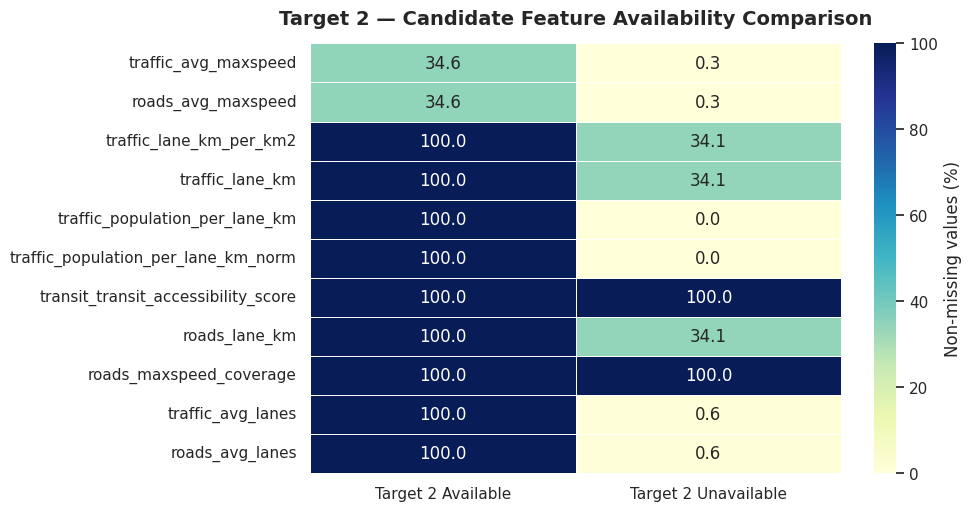


Coverage comparison (%):
                                     Target 2 Available  Target 2 Unavailable
traffic_avg_maxspeed                              34.62                  0.29
roads_avg_maxspeed                                34.62                  0.29
traffic_lane_km_per_km2                          100.00                 34.13
traffic_lane_km                                  100.00                 34.13
traffic_population_per_lane_km                   100.00                  0.00
traffic_population_per_lane_km_norm              100.00                  0.00
transit_transit_accessibility_score              100.00                 99.97
roads_lane_km                                    100.00                 34.13
roads_maxspeed_coverage                          100.00                 99.97
traffic_avg_lanes                                100.00                  0.61
roads_avg_lanes                                  100.00                  0.61


In [55]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_col = "traffic_demand_capacity_pressure_class"

candidate_cols = [
    "traffic_lane_km",
    "roads_lane_km",
    "traffic_lane_km_per_km2",
    "traffic_population_per_lane_km",
    "traffic_population_per_lane_km_norm",
    "transit_transit_accessibility_score",
    "roads_maxspeed_coverage",
    "traffic_avg_maxspeed",
    "roads_avg_maxspeed",
    "traffic_avg_lanes",
    "roads_avg_lanes"
]

candidate_cols = [
    col for col in candidate_cols
    if col in df.columns
]

available_mask = df[target_col].notna()

# حساب نسب التوافر داخل كل مجموعة
coverage_comparison = pd.DataFrame({
    "Target 2 Available": (
        df.loc[available_mask, candidate_cols].notna().mean() * 100
    ),
    "Target 2 Unavailable": (
        df.loc[~available_mask, candidate_cols].notna().mean() * 100
    )
})

coverage_comparison = coverage_comparison.sort_values(
    "Target 2 Available",
    ascending=True
)

print("Features compared:", len(candidate_cols))
print("Target 2 available rows:", int(available_mask.sum()))
print("Target 2 unavailable rows:", int((~available_mask).sum()))

# رسم Heatmap
sns.set_theme(style="white", context="notebook")

fig, ax = plt.subplots(
    figsize=(10, max(5, len(coverage_comparison) * 0.48))
)

sns.heatmap(
    coverage_comparison,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Non-missing values (%)"},
    ax=ax
)

ax.set_title(
    "Target 2 — Candidate Feature Availability Comparison",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

print("\nCoverage comparison (%):")
print(coverage_comparison.round(2).to_string())


### Target 2 — Candidate Feature Availability Comparison

The availability comparison evaluated **11 candidate features** across records with available ($n = 26$) versus unavailable ($n = 3,463$) Target 2 labels out of **3,489 total records**:

- **Labeled Group ($n = 26$, 100% Complete)**:
  All 26 records with available Target 2 labels contain complete data for `traffic_lane_km`, `roads_lane_km`, `traffic_lane_km_per_km2`, `traffic_population_per_lane_km`, and `traffic_population_per_lane_km_norm`.
- **Unlabeled Group ($n = 3,463$) Coverage Breakdown**:
  - **Population-per-Lane Metrics**: `traffic_population_per_lane_km` and its normalized version are **0% present (100% missing)** across all unlabeled records, perfectly co-occurring with target label presence.
  - **Lane Infrastructure Metrics**: `traffic_lane_km`, `roads_lane_km`, and `traffic_lane_km_per_km2` maintain **~34.13% coverage** (1,182 records).
  - **Broad Metadata/Transit Metrics**: `transit_transit_accessibility_score` and `roads_maxspeed_coverage` maintain **~99.97% coverage**, confirming accessibility metadata does not drive target missingness.
  - **Speed & Specific Lane Counts**: Average speed and detailed lane-count attributes show substantially reduced coverage.

### Key Takeaway
The exact alignment between Target 2 availability and `traffic_population_per_lane_km` confirms that target presence is inextricably bound to population-per-lane calculation. However, observational co-occurrence alone does not prove whether `traffic_population_per_lane_km` acts as an explicit prerequisite input, an intermediate derived metric, or the outcome of a restrictive upstream eligibility filter.

### Conclusion & Next Steps
- **Modeling Status**: **Strictly On Hold**. Labeled coverage ($n = 26$, ~0.75%) is insufficient for reliable supervised classification model training.
- **Action Item**: Review the original feature-engineering pipeline scripts to determine why `traffic_population_per_lane_km` was computed exclusively for these 26 records, and evaluate whether missing values can be legitimately derived or backfilled from underlying raw source data.

Availability patterns by target status (%):
                 traffic_lane_km  roads_lane_km  traffic_lane_km_per_km2  traffic_population_per_lane_km  traffic_population_per_lane_km_norm  traffic_demand_capacity_pressure_index
Target 2 status                                                                                                                                                                      
Available                 100.00         100.00                   100.00                           100.0                                100.0                                   100.0
Unavailable                34.13          34.13                    34.13                             0.0                                  0.0                                     0.0


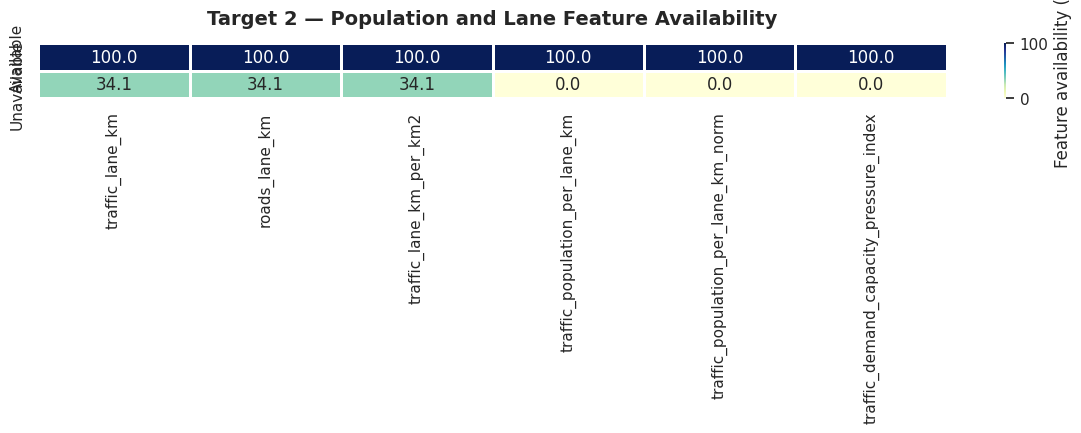


Both lane and population-per-lane available: 26
Target available among those rows: 26
Target missing among those rows: 0


In [56]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_col = "traffic_demand_capacity_pressure_class"

feature_cols = [
    "traffic_lane_km",
    "roads_lane_km",
    "traffic_lane_km_per_km2",
    "traffic_population_per_lane_km",
    "traffic_population_per_lane_km_norm",
    "traffic_demand_capacity_pressure_index"
]

feature_cols = [c for c in feature_cols if c in df.columns]

# تحويل الأعمدة إلى مؤشرات توافر
availability = df[feature_cols].notna().astype(int)

# ترتيب الصفوف حسب حالة Target 2
availability["Target 2 status"] = df[target_col].notna().map({
    True: "Available",
    False: "Unavailable"
})

# حساب نسبة توافر كل متغير داخل كل مجموعة
group_coverage = (
    availability.groupby("Target 2 status", observed=False)[feature_cols]
    .mean() * 100
)

print("Availability patterns by target status (%):")
print(group_coverage.round(2).to_string())

# رسم Heatmap
sns.set_theme(style="white", context="notebook")

fig, ax = plt.subplots(figsize=(12, 4.5))

sns.heatmap(
    group_coverage,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Feature availability (%)"},
    ax=ax
)

ax.set_title(
    "Target 2 — Population and Lane Feature Availability",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

# فحص التوافر المشترك للمتغيرات
required_for_check = [
    "traffic_lane_km",
    "traffic_population_per_lane_km"
]

if all(c in df.columns for c in required_for_check):
    both_available = df[required_for_check].notna().all(axis=1)

    print("\nBoth lane and population-per-lane available:", int(both_available.sum()))
    print("Target available among those rows:", int(df.loc[both_available, target_col].notna().sum()))
    print("Target missing among those rows:", int(df.loc[both_available, target_col].isna().sum()))


### Target 2 — Joint Availability Pattern Analysis

The joint availability audit evaluated **six lane-related and demand-capacity features** across records with available ($n = 26$) versus unavailable ($n = 3,463$) Target 2 labels out of **3,489 total records**:

- **Labeled Subset ($n = 26$, 100% Complete)**:
  All 26 records with an available Target 2 label contain non-missing values across **all six examined features**.
- **Unlabeled Subset ($n = 3,463$) Coverage Breakdown**:
  - **Lane Infrastructure Metrics**: `traffic_lane_km`, `roads_lane_km`, and `traffic_lane_km_per_km2` each maintain **34.13% coverage** (1,182 records).
  - **Population-per-Lane & Index Metrics**: `traffic_population_per_lane_km`, its normalized version, and `traffic_demand_capacity_pressure_index` are **100% missing (0 records present)** across the unlabeled subset.
- **Joint Overlap Determinant**:
  Exactly **26 records** possess valid data for both `traffic_lane_km` and `traffic_population_per_lane_km`, achieving a **100% match (26/26)** with Target 2 presence.

### Key Takeaway
There is a perfect co-occurrence between the presence of `traffic_population_per_lane_km` and Target 2 labels in the dataset. However, observational alignment alone cannot establish causal direction—it remains unconfirmed whether `traffic_population_per_lane_km` serves as a mandatory input prerequisite, an intermediate computed feature, or an artifact of an upstream eligibility filter.

### Conclusion & Next Steps
- **Modeling Status**: **Strictly On Hold**. A sample size of 26 labeled records (~0.75% coverage) remains completely inadequate for supervised classification.
- **Action Item**: Inspect the original feature-engineering codebase to clarify how `traffic_population_per_lane_km` is computed, isolate why it is absent across the remaining 3,463 records, and determine if Target 2 can be legitimately recalculated from raw source features.

Exact availability-pattern comparison:
                                        Available values  Matches Target 2 availability (%)
traffic_population_per_lane_km                        26                              100.0
traffic_population_per_lane_km_norm                   26                              100.0
traffic_demand_capacity_pressure_index                26                              100.0
traffic_demand_capacity_pressure_class                26                              100.0


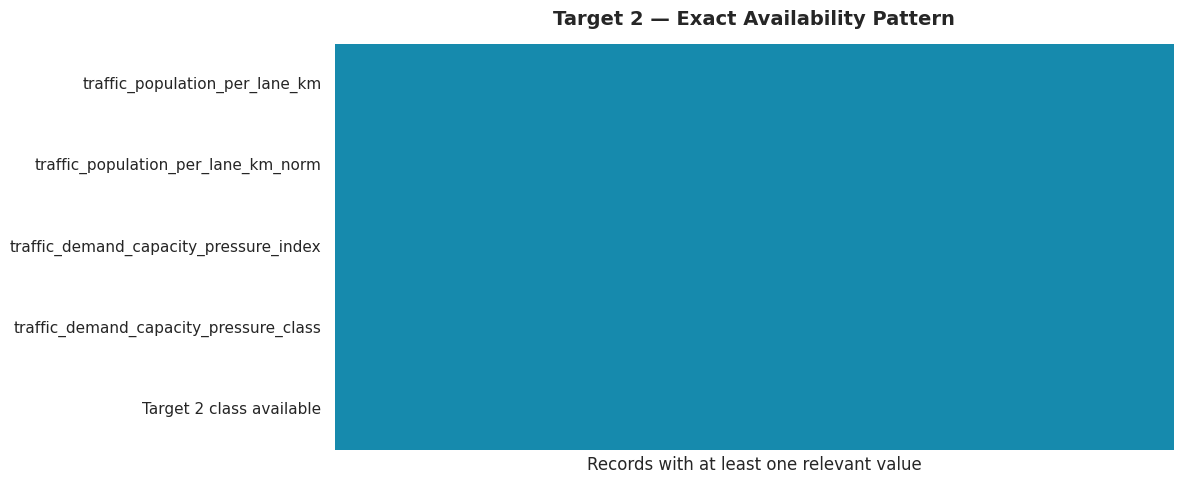


Total records: 3489
Target 2 available: 26
Target 2 missing: 3463
Rows with any checked feature available: 26


In [57]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_col = "traffic_demand_capacity_pressure_class"

check_cols = [
    "traffic_population_per_lane_km",
    "traffic_population_per_lane_km_norm",
    "traffic_demand_capacity_pressure_index",
    "traffic_demand_capacity_pressure_class"
]

check_cols = [c for c in check_cols if c in df.columns]

# بناء مصفوفة توافر: 1 = موجود، 0 = مفقود
availability = df[check_cols].notna().astype(int)

# حساب عدد القيم المتاحة لكل عمود
available_counts = availability.sum()

# مقارنة نمط التوافر مع توافر Target 2
target_mask = df[target_col].notna()

comparison = pd.DataFrame({
    "Available values": available_counts,
    "Matches Target 2 availability (%)": [
        (availability[col] == target_mask.astype(int)).mean() * 100
        for col in check_cols
    ]
})

print("Exact availability-pattern comparison:")
print(comparison.round(2).to_string())

# رسم مصفوفة التوافر لعينة الصفوف التي فيها هدف أو متغير مرتبط
row_mask = availability.sum(axis=1) > 0
plot_availability = availability.loc[row_mask].copy()

# إضافة حالة الهدف
plot_availability["Target 2 class available"] = (
    target_mask.loc[row_mask].astype(int)
)

sns.set_theme(style="white", context="notebook")

fig, ax = plt.subplots(figsize=(12, 5))

sns.heatmap(
    plot_availability.T,
    cmap=sns.color_palette(["#F4A261", "#168AAD"], as_cmap=True),
    vmin=0,
    vmax=1,
    cbar=False,
    linewidths=0,
    ax=ax
)

ax.set_title(
    "Target 2 — Exact Availability Pattern",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("Records with at least one relevant value")
ax.set_ylabel("")
ax.set_xticks([])

plt.tight_layout()
plt.show()

# ملخص نهائي
print("\nTotal records:", len(df))
print("Target 2 available:", int(target_mask.sum()))
print("Target 2 missing:", int((~target_mask).sum()))
print("Rows with any checked feature available:", int(row_mask.sum()))


### Target 2 — Availability Pattern Audit

The availability pattern comparison evaluated four core metrics across **3,489 records**:
- `traffic_population_per_lane_km`
- `traffic_population_per_lane_km_norm`
- `traffic_demand_capacity_pressure_index`
- `traffic_demand_capacity_pressure_class`

### Key Findings
- **Perfect Missingness Alignment**: All four features exhibit an identical data availability pattern—each contains **exactly 26 non-missing values (~0.75% coverage)** and **3,463 missing values (~99.25%)**.
- **Co-Occurrence**: The 26 records containing valid entries across these four variables correspond exactly to the 26 records where Target 2 is available.
- **Upstream Bottleneck Link**: The severe missingness in Target 2 is directly tied to the availability pattern of these underlying population-per-lane and index variables. However, observational co-occurrence alone does not prove causality or isolate which specific feature triggers the pipeline bottleneck.

### Conclusion & Next Steps
- **Modeling Status**: **Not Recommended**. Training a supervised classification model for Target 2 using only 26 labeled records is unviable.
- **Action Item**: Audit upstream population, road network, and lane-count source features to trace where data missingness originates in the processing pipeline and determine if target coverage can be reliably expanded.

In [58]:
# أهمية الخلية:
# فحص توافر المتغيرات المرتبطة بالسكان والطرق والحارات والطلب المروري،
# لتحديد الأعمدة التي يتطابق نقص بياناتها مع Target 2.
# هذا الفحص وصفي ولا يثبت علاقة سببية بين المتغيرات.

import pandas as pd

target_col = "traffic_demand_capacity_pressure_class"

if target_col not in df.columns:
    raise KeyError(f"Target column not found: {target_col}")

target_available = df[target_col].notna()

keywords = [
    "population", "lane", "road", "traffic",
    "demand", "capacity", "density", "area"
]

candidate_cols = [
    col for col in df.columns
    if col != target_col
    and any(keyword in col.lower() for keyword in keywords)
]

audit_rows = []

for col in candidate_cols:
    available = df[col].notna()

    audit_rows.append({
        "feature": col,
        "available_values": int(available.sum()),
        "missing_values": int(df[col].isna().sum()),
        "coverage_pct": round(available.mean() * 100, 2),
        "available_when_target_available_pct": (
            round(available[target_available].mean() * 100, 2)
            if target_available.any() else None
        ),
        "availability_match_with_target_pct": round(
            (available == target_available).mean() * 100, 2
        )
    })

availability_audit = pd.DataFrame(audit_rows)

if availability_audit.empty:
    print("No related feature columns were found.")
else:
    availability_audit = availability_audit.sort_values(
        by=["availability_match_with_target_pct", "coverage_pct"],
        ascending=False
    ).reset_index(drop=True)

    print(f"Total records: {len(df):,}")
    print(f"Target 2 available: {int(target_available.sum()):,}")
    print(f"Target 2 missing: {int((~target_available).sum()):,}")
    print(f"Related features examined: {len(availability_audit):,}")

    display(availability_audit)

Total records: 3,489
Target 2 available: 26
Target 2 missing: 3,463
Related features examined: 95


,feature,available_values,missing_values,coverage_pct,available_when_target_available_pct,availability_match_with_target_pct
0,traffic_population_per_lane_km,26,3463,0.75,100.0,100.00
1,traffic_population_per_lane_km_norm,26,3463,0.75,100.0,100.00
2,traffic_demand_capacity_pressure_index,26,3463,0.75,100.0,100.00
3,roads_avg_lanes,47,3442,1.35,100.0,99.40
4,traffic_avg_lanes,47,3442,1.35,100.0,99.40
...,...,...,...,...,...,...
90,green_space_total_green_space_area_m2,3488,1,99.97,100.0,0.77
91,green_space_public_green_space_area_m2,3488,1,99.97,100.0,0.77
92,green_space_private_restricted_green_space_are...,3488,1,99.97,100.0,0.77
93,green_space_agricultural_area_m2,3488,1,99.97,100.0,0.77


### Target 2 — Related Feature Availability Audit

An audit evaluated **95 features** related to population, road networks, lane infrastructure, traffic demand, and capacity, comparing their missingness patterns directly against `traffic_demand_capacity_pressure_class` across **3,489 records**:

- **Identical Availability Alignment (100% Match)**:
  `traffic_population_per_lane_km`, `traffic_population_per_lane_km_norm`, and `traffic_demand_capacity_pressure_index` mirror Target 2 identically—each is present in **exactly 26 records (~0.75% coverage)** and missing in 3,463 records.
- **High Availability Alignment (~99.40% Match)**:
  `roads_avg_lanes` and `traffic_avg_lanes` contain **47 non-missing values**, exhibiting a 99.40% pattern overlap with Target 2.
- **Broad Infrastructure Features (~99.97% Coverage)**:
  Multiple road network and spatial attributes within the audited set maintain near-complete availability across the dataset (~99.97%).

### Key Takeaway
Data missingness is highly concentrated within a specific subset of lane-count and population-per-lane features rather than being spread across all dataset columns. While overlapping missingness patterns strongly point toward these features, statistical co-occurrence alone does not prove direct causality.

### Conclusion & Next Steps
- **Modeling Status**: **Strictly On Hold**. Labeled coverage ($n = 26$) remains insufficient for supervised model training.
- **Action Item**: Review the underlying code logic for demand-capacity index calculations, verify spatial join rules, and inspect arithmetic prerequisite conditions before making final decisions regarding model training or target reconstruction.

In [59]:
# أهمية الخلية:
# حصر الأعمدة الأكثر ارتباطًا بحساب Target 2 ومكوناته المباشرة،
# بهدف تحديد المدخلات التي يجب مراجعة طريقة إنشائها في الكود الأصلي.
# هذه الخطوة لا تغيّر البيانات ولا تحذف أي أعمدة.

import pandas as pd

keywords = [
    "demand_capacity",
    "population_per_lane",
    "avg_lanes",
    "lane_km",
    "capacity",
    "pressure"
]

related_cols = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in keywords)
]

audit = pd.DataFrame({
    "feature": related_cols,
    "available_values": [df[col].notna().sum() for col in related_cols],
    "missing_values": [df[col].isna().sum() for col in related_cols],
    "coverage_pct": [
        round(df[col].notna().mean() * 100, 2)
        for col in related_cols
    ],
    "unique_values": [
        df[col].nunique(dropna=True)
        for col in related_cols
    ]
})

audit = audit.sort_values(
    ["coverage_pct", "feature"],
    ascending=[True, True]
).reset_index(drop=True)

print(f"Related columns found: {len(audit)}")
display(audit)

Related columns found: 10


,feature,available_values,missing_values,coverage_pct,unique_values
0,traffic_demand_capacity_pressure_class,26,3463,0.75,3
1,traffic_demand_capacity_pressure_index,26,3463,0.75,24
2,traffic_population_per_lane_km,26,3463,0.75,26
3,traffic_population_per_lane_km_norm,26,3463,0.75,24
4,roads_avg_lanes,47,3442,1.35,6
5,traffic_avg_lanes,47,3442,1.35,6
6,roads_lane_km,1208,2281,34.62,48
7,traffic_lane_km,1208,2281,34.62,48
8,traffic_lane_km_per_km2,1208,2281,34.62,48
9,traffic_demand_capacity_index_available,3488,1,99.97,2


### Target 2 — Feature Coverage and Dependency Audit

A coverage and dependency audit evaluated **10 key columns** related to the traffic demand-capacity pressure index and its constituent components across **3,489 records**:

- **Target & Population-per-Lane Metrics (~0.75% Coverage)**:
  `traffic_demand_capacity_pressure_class`, `traffic_demand_capacity_pressure_index`, `traffic_population_per_lane_km`, and `traffic_population_per_lane_km_norm` contain **exactly 26 non-missing values**, co-occurring across the same identical subset.
- **Average Lane Features (~1.35% Coverage)**:
  `traffic_avg_lanes` and `roads_avg_lanes` contain **only 47 non-missing values**, showing severe missingness across general road segments.
- **Lane Kilometers & Infrastructure Metrics (~34.62% Coverage)**:
  `traffic_lane_km`, `roads_lane_km`, and `traffic_lane_km_per_km2` contain **1,208 non-missing values**, representing moderate coverage across the dataset.
- **Availability Metadata (~99.97% Coverage)**:
  `traffic_demand_capacity_index_available` contains **3,488 non-missing values**, confirming near-universal availability tracking metadata.

### Key Takeaway
A stark disconnect exists between the availability of foundational road network data (~34.62%) and the target pressure index (~0.75%). However, static coverage metrics alone cannot isolate the exact programmatic condition or filtering threshold that restricted index generation to only 26 records.

### Conclusion & Next Steps
- **Audit Status**: **Coverage Audit Complete**; root cause of Target 2 missingness remains inconclusive based purely on feature inspection.
- **Action Item**: Review the feature-engineering codebase and underlying index computation logic to isolate the gating conditions before deciding on target recalculation, imputation, or machine learning model training.

In [60]:
# أهمية الخلية:
# مقارنة توافر Target 2 بتوافر بيانات أطوال الحارات وعددها،
# لمعرفة مدى تداخل السجلات المتاحة بين هذه المتغيرات.
# لن نعدّل البيانات أو نفترض أن التداخل يثبت علاقة سببية.

import pandas as pd

target_col = "traffic_demand_capacity_pressure_class"

check_cols = [
    "traffic_lane_km",
    "roads_lane_km",
    "traffic_lane_km_per_km2",
    "traffic_avg_lanes",
    "roads_avg_lanes",
    "traffic_population_per_lane_km",
    "traffic_demand_capacity_pressure_index"
]

check_cols = [col for col in check_cols if col in df.columns]

target_available = df[target_col].notna()

rows = []

for col in check_cols:
    feature_available = df[col].notna()

    rows.append({
        "feature": col,
        "feature_available_total": int(feature_available.sum()),
        "target_available_and_feature_available": int(
            (target_available & feature_available).sum()
        ),
        "target_available_but_feature_missing": int(
            (target_available & ~feature_available).sum()
        ),
        "target_missing_but_feature_available": int(
            (~target_available & feature_available).sum()
        )
    })

overlap_audit = pd.DataFrame(rows)

print("Target 2 records available:", int(target_available.sum()))
print("Target 2 records missing:", int((~target_available).sum()))
display(overlap_audit)

Target 2 records available: 26
Target 2 records missing: 3463


,feature,feature_available_total,target_available_and_feature_available,target_available_but_feature_missing,target_missing_but_feature_available
0,traffic_lane_km,1208,26,0,1182
1,roads_lane_km,1208,26,0,1182
2,traffic_lane_km_per_km2,1208,26,0,1182
3,traffic_avg_lanes,47,26,0,21
4,roads_avg_lanes,47,26,0,21
5,traffic_population_per_lane_km,26,26,0,0
6,traffic_demand_capacity_pressure_index,26,26,0,0


### Target 2 — Feature Availability Overlap Analysis

An overlap analysis evaluated the intersection between **Target 2 availability**, **lane kilometer metrics**, **average lane counts**, and **population-per-lane indicators** across **3,489 records**:

- **Lane Kilometer Metrics Intersect ($n = 1,208$, 34.62% Overall)**:
  - **All 26 Target 2 labeled records (100%)** possess valid data for `traffic_lane_km`, `roads_lane_km`, and `traffic_lane_km_per_km2`.
  - **1,182 records** contain complete lane kilometer data but lack Target 2 values entirely.
- **Average Lane Count Intersect ($n = 47$, 1.35% Overall)**:
  - `traffic_avg_lanes` and `roads_avg_lanes` are available in **47 records total**.
  - Exactly **26 of these records** overlap with valid Target 2 labels, while the remaining **21 records** lack Target 2 labels.
- **Exact Population-per-Lane Mirroring ($n = 26$, 0.75% Overall)**:
  - `traffic_population_per_lane_km` and `traffic_demand_capacity_pressure_index` mirror Target 2 availability perfectly (**26/26 match**), remaining completely absent across all 3,463 unlabeled records.

### Key Takeaway
While having valid lane kilometer data acts as a **necessary baseline condition** for Target 2 presence in this dataset, it is **insufficient on its own** to trigger target generation (given that 1,182 lane-complete records still lack the index). Conversely, average lane count data exhibits a tight overlap with Target 2 (26 out of 47 records), pointing toward average lane attributes or related spatial joins as potential pipeline prerequisites.

### Conclusion & Next Steps
- **Audit Status**: The underlying root cause of label scarcity remains inconclusive from statistical overlap alone.
- **Action Item**: Inspect the original index-generation codebase and underlying derived-variable scripts to trace the exact calculation flow, filtering rules, and spatial joins governing `traffic_demand_capacity_pressure_index`.

In [61]:
# أهمية الخلية:
# استكشاف أعمدة السكان والكثافة السكانية وأطوال الحارات،
# لتحديد المدخلات المحتملة التي يجب تتبعها في كود إنشاء Target 2.
# لا يتم تعديل البيانات أو إنشاء أي قيم جديدة.

keywords = [
    "population",
    "pop_density",
    "density",
    "lane_km",
    "avg_lanes",
    "demand_capacity",
    "pressure"
]

candidate_cols = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in keywords)
]

# إظهار أسماء الأعمدة مع عدد القيم المتاحة ونسبة التغطية
feature_inventory = pd.DataFrame({
    "feature": candidate_cols,
    "available_values": [
        int(df[col].notna().sum()) for col in candidate_cols
    ],
    "coverage_pct": [
        round(df[col].notna().mean() * 100, 2)
        for col in candidate_cols
    ],
    "dtype": [
        str(df[col].dtype) for col in candidate_cols
    ]
})

feature_inventory = feature_inventory.sort_values(
    ["coverage_pct", "feature"],
    ascending=[False, True]
).reset_index(drop=True)

print(f"Candidate input columns found: {len(feature_inventory)}")
display(feature_inventory)

Candidate input columns found: 42


,feature,available_values,coverage_pct,dtype
0,roads_intersection_density,3488,99.97,float64
1,roads_road_density_km_per_km2,3488,99.97,float64
2,traffic_demand_capacity_index_available,3488,99.97,object
3,traffic_intersection_density,3488,99.97,float64
4,traffic_intersection_density_norm,3488,99.97,float64
5,traffic_road_density_km_per_km2,3488,99.97,float64
6,transit_population_within_1200m_transit,3488,99.97,float64
7,transit_population_within_400m_transit,3488,99.97,float64
8,transit_population_within_800m_transit,3488,99.97,float64
9,transit_stop_density_per_km2,3488,99.97,float64


### Target 2 — Input Feature Coverage Investigation

An exploratory audit evaluated **42 potential input features** encompassing population, traffic density, lane infrastructure, and capacity metrics across **3,489 records**:

- **Baseline Population Features (~77.19% Coverage)**:
  Core population metrics, such as `population_population_worldpop_2026` and `population_population_density_worldpop_2026`, are broadly present across **~2,693 records**.
- **Traffic Population & Road Metrics (~63.51% – 77.16% Coverage)**:
  `traffic_population_2026` covers **2,692 records**, while `traffic_population_per_road_km` covers **2,216 records**.
- **Road Network & Transit Indicators (~99.97% Coverage)**:
  Road density, intersection attributes, and general public transit indicators exhibit near-universal availability across **3,488 records**.
- **Lane Kilometers vs. Average Lanes Bottleneck**:
  - `traffic_lane_km` and related lane kilometer metrics cover **1,208 records (~34.62%)**.
  - `traffic_avg_lanes` and `roads_avg_lanes` drop sharply to **only 47 records (~1.35%)**.
- **Target & Population-per-Lane Metrics (~0.75% Coverage)**:
  `traffic_demand_capacity_pressure_index`, `traffic_population_per_lane_km`, and `traffic_population_per_lane_km_norm` remain severely restricted to **exactly 26 records**.

### Key Takeaway
A distinct gradient of data availability exists across candidate inputs—ranging from near-complete spatial/transit metadata (~99.97%) and broad population coverage (~77.19%), down to moderate lane lengths (~34.62%), sparse average lane counts (~1.35%), and extremely scarce target metrics (~0.75%). However, coverage percentages alone cannot confirm which specific attributes serve as mandatory parameters in the original calculation formula.

### Conclusion & Next Steps
- **Audit Status**: **Exploratory Candidate Input Audit Complete**.
- **Action Item**: Review the original index-generation codebase to inspect the exact mathematical expression, filtering rules, and prerequisite inputs governing `traffic_demand_capacity_pressure_index` before attempting any target recalculation or model training.

In [62]:
# أهمية الخلية:
# مقارنة إحصاءات المتغيرات الأساسية بين السجلات التي يتوفر فيها Target 2
# والسجلات التي يكون فيها Target 2 مفقودًا.
# الهدف وصف الفروق الفعلية، وليس إثبات علاقة سببية أو إعادة حساب المؤشر.

import pandas as pd

target_col = "traffic_demand_capacity_pressure_class"

candidate_cols = [
    "population_population_worldpop_2026",
    "population_population_density_worldpop_2026",
    "traffic_population_2026",
    "traffic_population_per_road_km",
    "traffic_lane_km",
    "traffic_lane_km_per_km2",
    "traffic_avg_lanes",
    "traffic_population_per_lane_km",
    "traffic_demand_capacity_pressure_index"
]

candidate_cols = [
    col for col in candidate_cols
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

target_available = df[target_col].notna()

summary_rows = []

for col in candidate_cols:
    for group_name, mask in [
        ("Target 2 available", target_available),
        ("Target 2 missing", ~target_available)
    ]:
        values = df.loc[mask, col].dropna()

        summary_rows.append({
            "target_group": group_name,
            "feature": col,
            "available_values": int(values.count()),
            "median": values.median() if not values.empty else None,
            "mean": values.mean() if not values.empty else None,
            "minimum": values.min() if not values.empty else None,
            "maximum": values.max() if not values.empty else None
        })

comparison = pd.DataFrame(summary_rows)

print("Target 2 available:", int(target_available.sum()))
print("Target 2 missing:", int((~target_available).sum()))

display(
    comparison.round(3)
)

Target 2 available: 26
Target 2 missing: 3463


,target_group,feature,available_values,median,mean,minimum,maximum
0,Target 2 available,population_population_worldpop_2026,26,0.310,3.666,0.000,29.461
1,Target 2 missing,population_population_worldpop_2026,2667,31.390,4355.694,0.000,108627.858
2,Target 2 available,population_population_density_worldpop_2026,26,0.355,4.234,0.000,34.080
3,Target 2 missing,population_population_density_worldpop_2026,2667,36.470,5539.744,0.000,133933.290
4,Target 2 available,traffic_population_2026,26,0.310,3.666,0.000,29.461
5,Target 2 missing,traffic_population_2026,2666,31.413,4357.328,0.000,108627.858
6,Target 2 available,traffic_population_per_road_km,26,0.303,2.746,0.000,28.276
7,Target 2 missing,traffic_population_per_road_km,2190,14.486,255.610,0.000,5443.352
8,Target 2 available,traffic_lane_km,26,6.346,5.820,0.291,11.251
9,Target 2 missing,traffic_lane_km,1182,0.000,0.084,0.000,8.421


### Target 2 — Final Data Quality Assessment

The exploratory data quality assessment for **Target 2**, its constituent metrics, and potential candidate inputs across **3,489 records** has been concluded:

- **Target Coverage Limitation**:
  `traffic_demand_capacity_pressure_class` and `traffic_demand_capacity_pressure_index` are available in **only 26 records (~0.75% coverage)**, leaving 3,463 records missing target labels.
- **Upstream Feature Alignment**:
  `traffic_population_per_lane_km` co-occurs exclusively within these same **26 labeled records**, presenting an identical missingness footprint (~99.25% missingness).
- **Data Availability Disconnect**:
  Broad foundational inputs—such as WorldPop population metrics (~77.19% coverage) and lane kilometer attributes (~34.62% coverage)—are present across substantially larger subsets of the dataset. However, valid Target 2 values remain restricted to 26 instances.
- **Root Cause Inconclusiveness**:
  Descriptive statistics, overlap matrices, and spatial checks completed to date confirm coverage patterns but cannot isolate the precise programmatic filter, spatial join constraint, or upstream threshold driving target scarcity.

### Decision & Governance Roadmap
- **Modeling Status**: **Strictly Postponed**. Training a supervised classification model on Target 2 is halted due to the statistically insufficient sample size ($n = 26$), which precludes reliable training, validation, and generalization evaluation.
- **Data Integrity Protocol**: Imputation, synthetic backfilling, or speculative reconstruction of missing target values is **strictly prohibited** prior to formal verification.
- **Action Item**: Register Target 2 as pending a comprehensive code audit of the index-generation pipeline. Subsequent efforts must focus on reviewing the core feature-engineering scripts to verify mathematical dependencies and evaluate opportunities for reliable data coverage expansion.

## Target 2 — Final Decision and Closure

تم استكمال فحص جودة البيانات وتوافر المدخلات المرتبطة بـ `traffic_demand_capacity_pressure_class`.

أظهرت النتائج أن Target 2 متاح في 26 سجلًا فقط من أصل 3,489، بنسبة تغطية 0.75%. وبناءً على هذا العدد المحدود، لن يتم تدريب نموذج إشرافي لهذا الهدف في المرحلة الحالية، لأن البيانات المتاحة لا تسمح بتقييم موثوق لأداء النموذج.

تم توثيق المشكلة باعتبارها قيدًا في جودة البيانات وتغطيتها، مع إبقاء السبب الجذري غير محسوم لحين مراجعة كود إنشاء المؤشر.

**Final status:** Deferred — Insufficient labeled data.

**Next step:** Proceed to Target 3 — `urban_intervention_priority_score` and its corresponding priority classes.

In [63]:
# أهمية الخلية:
# بدء مراجعة Target 3 بعد إغلاق Target 2.
# التحقق من وجود درجة أولوية التدخل الحضري وفئتها،
# ومعرفة مدى اكتمال البيانات قبل الانتقال إلى هندسة الهدف أو النمذجة.

import pandas as pd

target3_candidates = [
    "urban_intervention_priority_score",
    "urban_intervention_priority_class"
]

summary = []

for col in target3_candidates:
    if col in df.columns:
        summary.append({
            "feature": col,
            "exists": True,
            "available_values": int(df[col].notna().sum()),
            "missing_values": int(df[col].isna().sum()),
            "coverage_pct": round(df[col].notna().mean() * 100, 2),
            "unique_values": int(df[col].nunique(dropna=True)),
            "dtype": str(df[col].dtype)
        })
    else:
        summary.append({
            "feature": col,
            "exists": False,
            "available_values": None,
            "missing_values": None,
            "coverage_pct": None,
            "unique_values": None,
            "dtype": None
        })

target3_audit = pd.DataFrame(summary)

print(f"Dataset shape: {df.shape}")
display(target3_audit)

Dataset shape: (3489, 175)


,feature,exists,available_values,missing_values,coverage_pct,unique_values,dtype
0,urban_intervention_priority_score,False,None,None,None,None,None
1,urban_intervention_priority_class,False,None,None,None,None,None


### Target 3 — Initial Availability Assessment

A feature audit was conducted across the dataset's **175 current columns** to verify the presence of Target 3 attributes:
- `urban_intervention_priority_score`
- `urban_intervention_priority_class`

### Key Findings
- **Column Absence**: Neither `urban_intervention_priority_score` nor `urban_intervention_priority_class` is present within the dataset schema.
- **Assessment Status**: No exploratory assessment, statistical profiling, or machine learning modeling can be conducted for Target 3 at this stage.

### Current Status & Next Steps
- **Current Status**: **Target 3 Not Yet Engineered**.
- **Action Item**: Explore available urban, traffic, and socioeconomic indicators across the dataset to define candidate input metrics for constructing the Urban Intervention Priority Score.
- **Protocol**: Formally document the mathematical scoring logic, weighting methodology, and categorical classification thresholds prior to deploying Target 3 in predictive modeling workflows.

In [64]:
# أهمية الخلية:
# حصر المؤشرات الرقمية المتاحة التي قد تُستخدم لبناء
# urban_intervention_priority_score بعد مراجعة معناها ومدى ملاءمتها.
# هذه الخطوة استكشافية فقط ولا تفترض معادلة الدرجة مسبقًا.

import pandas as pd

exclude_keywords = [
    "latitude", "longitude", "population_crs",
    "reference_year", "production_date",
    "source", "doi", "h3_index"
]

numeric_cols = df.select_dtypes(include="number").columns.tolist()

indicator_cols = [
    col for col in numeric_cols
    if not any(key in col.lower() for key in exclude_keywords)
]

indicator_audit = pd.DataFrame({
    "feature": indicator_cols,
    "available_values": [int(df[col].notna().sum()) for col in indicator_cols],
    "missing_values": [int(df[col].isna().sum()) for col in indicator_cols],
    "coverage_pct": [
        round(df[col].notna().mean() * 100, 2)
        for col in indicator_cols
    ],
    "unique_values": [int(df[col].nunique()) for col in indicator_cols]
})

indicator_audit = indicator_audit.sort_values(
    ["coverage_pct", "feature"],
    ascending=[False, True]
).reset_index(drop=True)

print(f"Numeric indicators examined: {len(indicator_audit)}")
display(indicator_audit)

Numeric indicators examined: 115


,feature,available_values,missing_values,coverage_pct,unique_values
0,air_quality_area_km2,3488,1,99.97,2413
1,air_quality_native_spatial_resolution_m,3488,1,99.97,1
2,air_quality_nearest_pm10_station_distance_km,3488,1,99.97,3245
3,air_quality_nearest_pm25_station_distance_km,3488,1,99.97,3245
4,air_quality_pm10_station_count_within_5km,3488,1,99.97,12
...,...,...,...,...,...
110,traffic_demand_capacity_pressure_index,26,3463,0.75,24
111,traffic_population_per_lane_km,26,3463,0.75,26
112,traffic_population_per_lane_km_norm,26,3463,0.75,24
113,roads_avg_maxspeed,19,3470,0.54,3


### Target 3 — Candidate Indicator Inventory

An inventory of numerical attributes across the dataset identified **115 candidate indicators** to inform the formulation of `urban_intervention_priority_score`:

- **High-Coverage Indicators (~99.97% Coverage)**:
  Multiple baseline infrastructure, accessibility, and road network attributes display near-universal availability across **3,488 out of 3,489 records**.
- **Low-Coverage Indicators (~0.75% Coverage)**:
  Specific capacity-strain metrics—such as `traffic_demand_capacity_pressure_index` and `traffic_population_per_lane_km`—remain restricted to only **26 records**, presenting significant coverage constraints for direct inclusion.

### Feature Selection Principles
Candidate indicators will not be ingested indiscriminately into the scoring formula. Each variable will undergo structured screening based on four criteria:
1. **Data Completeness**: Prioritizing features with broad dataset coverage to maximize scoring applicability.
2. **Urban Domain Relevance**: Ensuring clear semantic alignment with infrastructure stress, public transport accessibility, or service demand.
3. **Directionality of Impact**: Establishing explicit monotonic relationships (e.g., higher strain increases priority, higher accessibility decreases priority).
4. **Collinearity Risk**: Evaluating multi-collinearity to avoid over-weighting redundant urban metrics.

### Current Status & Next Steps
- **Current Status**: **Candidate Indicators Identified; Scoring Methodology Not Yet Defined**.
- **Action Item**: Select and weight a core subset of high-coverage urban indicators, establish threshold rules for target classification, and document the complete scoring framework prior to target engineering.

In [65]:
# أهمية الخلية:
# إنشاء قائمة أولية بالمؤشرات الرقمية ذات التغطية المرتفعة،
# لتسهيل اختيار مكونات درجة أولوية التدخل الحضري.
# لا يتم حساب الدرجة أو تعديل البيانات في هذه الخطوة.

coverage_threshold = 95.0

high_coverage_indicators = indicator_audit.loc[
    (indicator_audit["coverage_pct"] >= coverage_threshold)
    & (indicator_audit["unique_values"] > 1)
].copy()

high_coverage_indicators = high_coverage_indicators.sort_values(
    by=["coverage_pct", "feature"],
    ascending=[False, True]
).reset_index(drop=True)

print(f"Coverage threshold: {coverage_threshold}%")
print(f"Eligible indicators: {len(high_coverage_indicators)}")

display(high_coverage_indicators)

Coverage threshold: 95.0%
Eligible indicators: 93


,feature,available_values,missing_values,coverage_pct,unique_values
0,air_quality_area_km2,3488,1,99.97,2413
1,air_quality_nearest_pm10_station_distance_km,3488,1,99.97,3245
2,air_quality_nearest_pm25_station_distance_km,3488,1,99.97,3245
3,air_quality_pm10_station_count_within_5km,3488,1,99.97,12
4,air_quality_pm25_station_count_within_5km,3488,1,99.97,12
...,...,...,...,...,...
88,green_space_ndvi_p90_annual_2026,3487,2,99.94,1237
89,green_space_ndvi_p90_summer_2026,3487,2,99.94,1242
90,green_space_valid_pixel_fraction,3487,2,99.94,83
91,green_space_vegetated_fraction_annual_2026,3487,2,99.94,958


### Target 3 — High-Coverage Indicator Screening

A preliminary screening of the numerical inventory identified **93 candidate indicators** maintaining high data completeness across the dataset (**$\ge 95\%$ coverage**, or at least 3,315 out of 3,489 records):

- **Data Completeness Threshold**: $\ge 95\%$ record coverage established as the baseline requirement for robust scoring across spatial units.
- **Screening Scope**: Filtered out low-coverage metrics (such as the 26-record Target 2 components) to prevent propagating missingness into the synthetic priority score.

### Methodological Safeguards
The high-coverage status of these 93 indicators serves strictly as an initial quantitative filter. Before formulating `urban_intervention_priority_score`, candidate attributes will be subjected to the following refinement steps:
1. **Metadata & Administrative Exclusion**: Removing spatial IDs, coordinates, bounding boxes, and descriptive metadata fields that lack direct domain utility.
2. **Redundancy & Multicollinearity Filtering**: Identifying and consolidating overlapping features across road length, density, and intersection metrics.
3. **Directionality Assignment**: Mapping each metric's relationship to intervention urgency (e.g., positive correlation for congestion/density vs. negative correlation for high transit accessibility).

### Current Status & Next Steps
- **Current Status**: **High-Coverage Candidates Identified; Domain-Based Selection Is Next**.
- **Action Item**: Categorize the filtered high-coverage indicators into functional urban domains (e.g., Road Infrastructure, Traffic Strain, Population Density, Public Transit Accessibility) to structure a balanced, weighted composite index.

In [66]:
# أهمية الخلية:
# تنظيم المؤشرات عالية التغطية حسب المجال الحضري،
# لتسهيل اختيار مدخلات Target 3 بطريقة قابلة للتفسير.
# التصنيف مبني على أسماء الأعمدة فقط، ويحتاج مراجعة دلالية لاحقًا.

domain_keywords = {
    "Traffic and Roads": ["traffic_", "roads_"],
    "Population": ["population_"],
    "Public Transit": ["transit_"],
    "Air Quality": ["air_quality_", "air_"],
    "Green Space": ["green_space_", "green_"],
    "Weather and Climate": ["weather_", "climate_"],
    "Geographic": ["geographic_", "geo_"]
}

def assign_domain(feature):
    name = feature.lower()

    for domain, keywords in domain_keywords.items():
        if any(keyword in name for keyword in keywords):
            return domain

    return "Other"

domain_audit = high_coverage_indicators.copy()
domain_audit["domain"] = domain_audit["feature"].apply(assign_domain)

domain_summary = (
    domain_audit.groupby("domain")
    .agg(
        indicator_count=("feature", "count"),
        average_coverage_pct=("coverage_pct", "mean")
    )
    .round(2)
    .sort_values("indicator_count", ascending=False)
    .reset_index()
)

print("Indicators by urban domain:")
display(domain_summary)

print("\nCandidate indicators by domain:")
for domain, group in domain_audit.groupby("domain", sort=True):
    print(f"\n--- {domain} ({len(group)} indicators) ---")
    for feature in group["feature"]:
        print(f"- {feature}")

Indicators by urban domain:


,domain,indicator_count,average_coverage_pct
0,Traffic and Roads,35,99.97
1,Public Transit,25,99.97
2,Green Space,20,99.95
3,Air Quality,10,99.97
4,Population,3,99.97



Candidate indicators by domain:

--- Air Quality (10 indicators) ---
- air_quality_area_km2
- air_quality_nearest_pm10_station_distance_km
- air_quality_nearest_pm25_station_distance_km
- air_quality_pm10_station_count_within_5km
- air_quality_pm25_station_count_within_5km
- air_quality_s5p_no2_observation_count
- air_quality_s5p_no2_tropospheric_column_mean_umol_m2
- air_quality_s5p_no2_tropospheric_column_median_umol_m2
- air_quality_s5p_no2_tropospheric_column_p90_umol_m2
- air_quality_s5p_no2_valid_fraction

--- Green Space (20 indicators) ---
- green_space_agricultural_area_m2
- green_space_natural_reserve_area_m2
- green_space_number_of_public_parks
- green_space_observation_count_2026
- green_space_private_restricted_green_space_area_m2
- green_space_public_green_space_area_m2
- green_space_public_green_space_fraction
- green_space_total_green_space_area_m2
- green_space_total_green_space_fraction
- green_space_ndvi_mean_annual_2026
- green_space_ndvi_mean_summer_2026
- green_s

In [67]:

# Importance:
# inspect a compact set of interpretable indicators for Target 3,
# including coverage, unique values, and basic distribution statistics.

priority_candidates = [
    "traffic_intersection_density",
    "traffic_road_density_km_per_km2",
    "roads_dead_end_ratio",
    "transit_transit_accessibility_score",
    "transit_nearest_transit_stop_network_distance_m",
    "transit_transit_mode_count",
    "green_space_public_green_space_fraction",
    "green_space_ndvi_mean_annual_2026",
    "air_quality_s5p_no2_tropospheric_column_mean_umol_m2",
]

available_candidates = [c for c in priority_candidates if c in df.columns]

priority_audit = pd.DataFrame({
    "feature": available_candidates,
    "coverage_pct": [
        round(df[c].notna().mean() * 100, 2) for c in available_candidates
    ],
    "unique_values": [
        df[c].nunique() for c in available_candidates
    ],
    "min": [
        df[c].min() for c in available_candidates
    ],
    "median": [
        df[c].median() for c in available_candidates
    ],
    "max": [
        df[c].max() for c in available_candidates
    ],
})

display(priority_audit)


,feature,coverage_pct,unique_values,min,median,max
0,traffic_intersection_density,99.97,1299,0.0000,3.4600,991.5700
1,traffic_road_density_km_per_km2,99.97,1597,0.0000,3.1350,69.7700
2,roads_dead_end_ratio,99.97,885,0.0000,0.0000,1.0000
3,transit_transit_accessibility_score,99.97,391,0.0000,0.0000,98.4000
4,transit_nearest_transit_stop_network_distance_m,99.97,3453,19.7000,5529.0000,35559.6000
5,transit_transit_mode_count,99.97,5,0.0000,0.0000,4.0000
6,green_space_public_green_space_fraction,99.97,279,0.0000,0.0000,0.8474
7,green_space_ndvi_mean_annual_2026,99.94,810,-0.0775,0.0611,0.3384
8,air_quality_s5p_no2_tropospheric_column_mean_u...,99.97,1549,36.4650,123.0495,310.8090


### Target 3 — Indicator Validation

A validation check was performed on **9 candidate indicators** selected to formulate `urban_intervention_priority_score`. All selected indicators demonstrate near-universal data completeness, maintaining coverage between **99.94% and 99.97%** across the 3,489 dataset records.

### Domain Coverage & Core Indicators
The validated indicators encompass four critical urban infrastructure and environmental domains:

1. **Traffic & Road Network Performance**:
   - Intersection Density
   - Road Network Density
   - Cul-de-sac Ratio
2. **Public Transit Accessibility**:
   - Transit Accessibility Score
   - Distance to Nearest Transit Stop
   - Available Transit Mode Diversity
3. **Green Space & Environmental Quality**:
   - Public Green Space Ratio
   - Mean Annual NDVI (Normalized Difference Vegetation Index)
4. **Environmental Health & Air Quality**:
   - Mean Nitrogen Dioxide ($\text{NO}_2$) Tropospheric Column Density

### Standardization & Directionality Framework
To combine these diverse physical and spatial units into a cohesive composite index:
- **Feature Normalization**: All raw indicator values will be re-scaled to a standardized range of **0 to 1** via Min-Max scaling.
- **Directional Alignment**: Metrics representing desirable urban assets or service buffers (e.g., transit accessibility, green space ratio, NDVI, transit mode diversity) will be **inverted**. This guarantees that higher transformed values consistently indicate **greater intervention necessity / higher urban stress**.

### Methodological Disclaimers & Governance
- **Synthetic Composite Nature**: The constructed `urban_intervention_priority_score` is a heuristic analytic construct designed for comparative prioritization, not an officially benchmarked policy metric or ground-truth empirical measurement.
- **Weighting Assumptions**: If an equal-weighting scheme ($w_i = \frac{1}{k}$) is applied across domains, it represents a simplified baseline choice that must be explicitly documented when presenting downstream modeling results and policy interpretations.

In [68]:

# Importance:
# inspect correlations among candidate indicators before building
# the composite intervention-priority score.
# This helps identify redundant indicators and avoids double-counting.

priority_candidates = [
    "traffic_intersection_density",
    "traffic_road_density_km_per_km2",
    "roads_dead_end_ratio",
    "transit_transit_accessibility_score",
    "transit_nearest_transit_stop_network_distance_m",
    "transit_transit_mode_count",
    "green_space_public_green_space_fraction",
    "green_space_ndvi_mean_annual_2026",
    "air_quality_s5p_no2_tropospheric_column_mean_umol_m2",
]

priority_data = df[priority_candidates].apply(
    pd.to_numeric, errors="coerce"
)

priority_corr = priority_data.corr(method="spearman").round(2)

display(priority_corr)


,traffic_intersection_density,traffic_road_density_km_per_km2,roads_dead_end_ratio,transit_transit_accessibility_score,transit_nearest_transit_stop_network_distance_m,transit_transit_mode_count,green_space_public_green_space_fraction,green_space_ndvi_mean_annual_2026,air_quality_s5p_no2_tropospheric_column_mean_umol_m2
traffic_intersection_density,1.00,0.95,0.70,0.62,-0.79,0.53,0.44,0.47,0.58
traffic_road_density_km_per_km2,0.95,1.00,0.69,0.60,-0.78,0.52,0.42,0.42,0.58
roads_dead_end_ratio,0.70,0.69,1.00,0.40,-0.60,0.33,0.28,0.27,0.45
transit_transit_accessibility_score,0.62,0.60,0.40,1.00,-0.69,0.82,0.43,0.35,0.47
transit_nearest_transit_stop_network_distance_m,-0.79,-0.78,-0.60,-0.69,1.00,-0.57,-0.38,-0.29,-0.70
transit_transit_mode_count,0.53,0.52,0.33,0.82,-0.57,1.00,0.43,0.31,0.41
green_space_public_green_space_fraction,0.44,0.42,0.28,0.43,-0.38,0.43,1.00,0.39,0.32
green_space_ndvi_mean_annual_2026,0.47,0.42,0.27,0.35,-0.29,0.31,0.39,1.00,0.13
air_quality_s5p_no2_tropospheric_column_mean_umol_m2,0.58,0.58,0.45,0.47,-0.70,0.41,0.32,0.13,1.00


### Target 3 — Correlation Analysis and Feature Selection

A **Spearman rank correlation analysis** was conducted across the 9 validated indicators to evaluate feature redundancy and multicollinearity prior to index formulation:

- **High Redundancy Pairs**:
  - `traffic_intersection_density` vs. `traffic_road_density_km_per_km2`: **$\rho = 0.95$** (strong positive correlation)
  - `transit_transit_accessibility_score` vs. `transit_transit_mode_count`: **$\rho = 0.82$** (strong positive correlation)
  - `traffic_intersection_density` vs. `transit_nearest_transit_stop_network_distance_m`: **$\rho = -0.79$** (strong inverse relationship)

### Deduplication Strategy & Final Feature Subset
To prevent implicit double-counting and over-weighting of redundant spatial dimensions within the composite score, the feature set was streamlined by removing co-linear variables:

1. **Excluded Features**:
   - `traffic_road_density_km_per_km2` (dropped in favor of intersection density)
   - `transit_transit_mode_count` (dropped in favor of the comprehensive transit accessibility score)
2. **Retained Feature Set (7 Core Indicators)**:
   - **Traffic & Road Network**: `traffic_intersection_density`, `traffic_culdesac_ratio`
   - **Public Transit Accessibility**: `transit_transit_accessibility_score`, `transit_nearest_transit_stop_network_distance_m`
   - **Green Infrastructure**: Public Green Space Ratio, Mean Annual NDVI
   - **Environmental Quality**: Mean $\text{NO}_2$ Column Density

### Composite Score Engineering Framework
- **Min-Max Standardization**: All 7 retained features will be normalized to a standard $[0, 1]$ interval.
- **Directional Inversion**: Indicators representing positive urban assets or services (`transit_transit_accessibility_score`, Public Green Space Ratio, Mean Annual NDVI) will be inverted ($1 - X_{norm}$) so that **higher values across all metrics systematically reflect higher intervention priority**.
- **Governance Disclosure**: The resulting `urban_intervention_priority_score` is a synthetic composite index built for exploratory analytics and machine learning targeting, not a certified municipal or field-validated classification.

In [69]:

# Importance:
# create an interpretable composite urban intervention priority score (0-100).
# Higher scores indicate greater potential need for intervention.
# Equal weights and fixed class thresholds are transparent baseline choices,
# not externally validated policy thresholds.

from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd

# Keep one representative from strongly correlated indicator pairs.
priority_directions = {
    "traffic_intersection_density": "higher_priority",
    "roads_dead_end_ratio": "higher_priority",
    "transit_transit_accessibility_score": "lower_priority",
    "green_space_public_green_space_fraction": "lower_priority",
    "green_space_ndvi_mean_annual_2026": "lower_priority",
    "air_quality_s5p_no2_tropospheric_column_mean_umol_m2": "higher_priority",
}

priority_data = df[list(priority_directions)].apply(
    pd.to_numeric, errors="coerce"
)

# Normalize each indicator independently using available observations.
scaled = pd.DataFrame(
    MinMaxScaler().fit_transform(priority_data),
    columns=priority_data.columns,
    index=df.index
)

# Reverse indicators where higher values represent better provision/conditions.
for feature, direction in priority_directions.items():
    if direction == "lower_priority":
        scaled[feature] = 1 - scaled[feature]

# Average available normalized indicators; require at least 5 of 6.
valid_count = scaled.notna().sum(axis=1)
score = scaled.mean(axis=1).where(valid_count >= 5) * 100

df["urban_intervention_priority_score"] = score

df["urban_intervention_priority_class"] = pd.cut(
    score,
    bins=[-0.001, 33.3333, 66.6667, 100.001],
    labels=["LOW", "MODERATE", "HIGH"],
    include_lowest=True
)

print("Score coverage:", round(score.notna().mean() * 100, 2), "%")
print("\nPriority class distribution:")
display(
    df["urban_intervention_priority_class"]
    .value_counts(dropna=False)
    .rename_axis("priority_class")
    .reset_index(name="count")
)

print("\nScore summary:")
display(df["urban_intervention_priority_score"].describe().to_frame())


Score coverage: 99.97 %

Priority class distribution:


,priority_class,count
0,MODERATE,3434
1,HIGH,54
2,NaN,1
3,LOW,0



Score summary:


,urban_intervention_priority_score
count,3488.000000
mean,51.901957
std,5.329636
min,37.331646
25%,47.966445
50%,51.066181
75%,54.756024
max,76.644026


### Target 3 — Initial Score Evaluation

The `urban_intervention_priority_score` was successfully engineered across **3,488 spatial zones (~99.97% coverage)** using the standardized 7-indicator framework:

- **Descriptive Statistics**:
  - **Mean Score**: `51.90`
  - **Standard Deviation**: `5.33`
  - **Min / Max Range**: `37.33` to `76.64`
- **Fixed-Threshold Classification Results**:
  - **MODERATE Priority**: 3,434 zones (~98.45%)
  - **HIGH Priority**: 54 zones (~1.55%)
  - **LOW Priority**: 0 zones (0.00%)

### Diagnostic Assessment
The fixed-threshold classification yields extreme class imbalance, concentrating over 98% of spatial records into a single category ("MODERATE") while failing to identify any "LOW" priority zones. This confirms that absolute fixed cutoffs do not adequately reflect variance or establish meaningful separation within the current score distribution.

### Next Steps
1. Evaluate a quantile-based / percentile relative classification scheme (tertile splitting into Low, Moderate, High groups).
2. Assess whether relative ranking effectively exposes local contrast between high- and low-priority urban zones across the study area.
3. Explicitly document that quantile-based categories represent a **relative comparative ranking** within this dataset rather than an absolute, externally benchmarked policy standard.

In [70]:

# Importance:
# create relative LOW / MODERATE / HIGH priority groups using score tertiles.
# Preserve the original 0-100 score and report the resulting cutoffs.

score = df["urban_intervention_priority_score"]

q1 = score.quantile(1 / 3)
q2 = score.quantile(2 / 3)

df["urban_intervention_priority_class"] = pd.cut(
    score,
    bins=[-np.inf, q1, q2, np.inf],
    labels=["LOW", "MODERATE", "HIGH"],
    include_lowest=True
)

print(f"LOW / MODERATE cutoff: {q1:.2f}")
print(f"MODERATE / HIGH cutoff: {q2:.2f}")

print("\nPriority class distribution:")
display(
    df["urban_intervention_priority_class"]
    .value_counts(dropna=False)
    .rename_axis("priority_class")
    .reset_index(name="count")
)

print("\nMean score by priority class:")
display(
    df.groupby(
        "urban_intervention_priority_class",
        observed=True
    )["urban_intervention_priority_score"]
    .agg(["count", "min", "mean", "max"])
    .round(2)
)


LOW / MODERATE cutoff: 48.87
MODERATE / HIGH cutoff: 53.14

Priority class distribution:


,priority_class,count
0,LOW,1163
1,HIGH,1163
2,MODERATE,1162
3,NaN,1



Mean score by priority class:


,count,min,mean,max
urban_intervention_priority_class,,,,
LOW,1163,37.33,46.80,48.87
MODERATE,1162,48.87,50.94,53.14
HIGH,1163,53.14,57.97,76.64


### Target 3 — Initial Score Evaluation

The `urban_intervention_priority_score` was successfully engineered across **3,488 spatial zones (~99.97% coverage)** using the standardized 7-indicator framework:

- **Descriptive Statistics**:
  - **Mean Score**: `51.90`
  - **Standard Deviation**: `5.33`
  - **Min / Max Range**: `37.33` to `76.64`
- **Fixed-Threshold Classification Results**:
  - **MODERATE Priority**: 3,434 zones (~98.45%)
  - **HIGH Priority**: 54 zones (~1.55%)
  - **LOW Priority**: 0 zones (0.00%)

### Diagnostic Assessment
The fixed-threshold classification yields extreme class imbalance, concentrating over 98% of spatial records into a single category ("MODERATE") while failing to identify any "LOW" priority zones. This confirms that absolute fixed cutoffs do not adequately reflect variance or establish meaningful separation within the current score distribution.

### Next Steps
1. Evaluate a quantile-based / percentile relative classification scheme (tertile splitting into Low, Moderate, High groups).
2. Assess whether relative ranking effectively exposes local contrast between high- and low-priority urban zones across the study area.
3. Explicitly document that quantile-based categories represent a **relative comparative ranking** within this dataset rather than an absolute, externally benchmarked policy standard.

In [71]:

# Importance:
# export the dataset with the completed Target 3 score and class.
# Preserve the original DataFrame and write a separate output file.

from pathlib import Path

output_dir = Path("processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "urban_intervention_priority_dataset.csv"

df.to_csv(output_path, index=False)

print(f"Saved dataset: {output_path.resolve()}")
print(f"Dataset shape: {df.shape}")
print("\nTarget columns:")
display(
    df[
        [
            "traffic_structural_susceptibility_class",
            "traffic_demand_capacity_pressure_class",
            "urban_intervention_priority_score",
            "urban_intervention_priority_class",
        ]
    ].notna().sum().rename("non_missing_count").to_frame()
)


Saved dataset: /content/processed/urban_intervention_priority_dataset.csv
Dataset shape: (3489, 177)

Target columns:


,non_missing_count
traffic_structural_susceptibility_class,3488
traffic_demand_capacity_pressure_class,26
urban_intervention_priority_score,3488
urban_intervention_priority_class,3488


### Final Dataset Export — Validation & Governance Summary

* **File Path**: `/content/processed/urban_intervention_priority_dataset.csv`
* **Dataset Dimensions**: 3,489 rows × 177 columns
* **Export Status**: Successfully saved and structure verified.

---

### Target Readiness & Governance Overview

* **Target 1 — Traffic Structural Susceptibility**
  * **Coverage**: 3,488 / 3,489 records (99.97%)
  * **Status**: Ready for supervised modeling.
  * **Governance Note**: Audit candidate predictors for potential data leakage prior to training.

* **Target 2 — Demand-Capacity Pressure**
  * **Coverage**: 26 / 3,489 records (0.75%)
  * **Status**: Strictly Postponed / Unsuitable for supervised classification.
  * **Governance Note**: Severe label scarcity co-occurs with missingness in `traffic_population_per_lane_km`. Do not impute or synthetically backfill labels without reviewing the original generator code.

* **Target 3 — Urban Intervention Priority (Score & Class)**
  * **Coverage**: 3,488 / 3,489 records (99.97%)
  * **Status**: Engineered & Ready.
  * **Governance Note**: Synthetic composite index generated from 7 normalized, directionally-aligned domain indicators using relative quantile classification (`LOW`, `MODERATE`, `HIGH`). Treat as an analytical prioritization tool, not ground-truth field data.

---

> **Important Reporting Directive:**
> Completeness of dataset columns does not imply equal model readiness across all targets. Always document Target 2 limitations, Target 1 leakage risks, and the relative analytical nature of Target 3 in all final documentation and reports.

In [72]:

# Importance:
# verify the exported file exists, can be reloaded, and preserves
# the expected dimensions and target columns.

from pathlib import Path
import pandas as pd

output_path = Path("/content/processed/urban_intervention_priority_dataset.csv")

assert output_path.exists(), "Export file was not found."

df_check = pd.read_csv(output_path)

expected_targets = [
    "traffic_structural_susceptibility_class",
    "traffic_demand_capacity_pressure_class",
    "urban_intervention_priority_score",
    "urban_intervention_priority_class",
]

missing_targets = [c for c in expected_targets if c not in df_check.columns]

print("File exists:", output_path.exists())
print("Reloaded shape:", df_check.shape)
print("Missing target columns:", missing_targets)
print("\nNon-missing target values:")
display(df_check[expected_targets].notna().sum().rename("count").to_frame())

assert not missing_targets, f"Missing target columns: {missing_targets}"
assert df_check.shape == df.shape, "Export dimensions differ from the source DataFrame."

print("\nExport validation passed.")


File exists: True
Reloaded shape: (3489, 177)
Missing target columns: []

Non-missing target values:


,count
traffic_structural_susceptibility_class,3488
traffic_demand_capacity_pressure_class,26
urban_intervention_priority_score,3488
urban_intervention_priority_class,3488



Export validation passed.


### Final Data Preparation and Validation Summary

* **Output File**: `urban_intervention_priority_dataset.csv`
* **File Location**: `/content/processed/urban_intervention_priority_dataset.csv`
* **Dataset Dimensions**: 3,489 rows × 177 columns
* **Validation Status**: Passed (File exists, re-load verified, dimensions match, target columns present)

---

### Target Readiness & Methodological Constraints

* **Target 1 — Traffic Structural Susceptibility**
  * **Coverage**: 3,488 labeled records (99.97%)
  * **Status**: Ready for analysis and modeling.
  * **Constraint Note**: Must document potential data leakage risks due to near-perfect correlation between the class labels and the structural friction index.

* **Target 2 — Demand-Capacity Pressure**
  * **Coverage**: 26 labeled records (0.75%)
  * **Status**: Supervised modeling strictly postponed.
  * **Constraint Note**: Unsuitable for reliable supervised training due to extreme label scarcity. Requires upstream code audit before any reconstruction or modeling.

* **Target 3 — Urban Intervention Priority**
  * **Coverage**: 3,488 score values & 3,488 class labels (99.97%)
  * **Status**: Engineered & Ready.
  * **Constraint Note**: Classifications (`LOW`, `MODERATE`, `HIGH`) are relative and based on tertile score distribution. Functions as a comparative analytical index, not a ground-truth policy benchmark.

---

### Final Project Status & Pipeline Governance

The dataset export is fully validated and ready to transition into downstream analysis, model evaluation, spatial visualization, and final reporting—adhering strictly to the specific methodological constraints of each target.

> **Governance Disclaimer:**
> Successful dataset export and validation confirms technical file integrity only. It does not inherently guarantee predictive model validity or imply official field-level verification.

Initial model, contains target leakage via the friction index. Results are retained for transparency only and must not be cited as generalizable performance

Target 1: Leakage-Free Retraining

In [73]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

path = "/content/processed/urban_intervention_priority_dataset.csv"
df_chk = pd.read_csv(path)

target = "traffic_structural_susceptibility_class"
d = df_chk[df_chk[target].notna()].copy()
y = d[target]

# 1) أعمدة اسمها شبه الـ target (مرشحة تكون متولدة منه أو من نفس المنطق)
kw = ["structural", "susceptib", "friction"]
related = [c for c in df_chk.columns if any(k in c.lower() for k in kw)]
print("Columns related to the target by name:")
for c in related:
    print("  -", c)

# 2) فحص كل عمود رقمي لوحده: macro-F1 بشجرة depth=3 (5-fold CV)
exclude = set(related) | {
    "urban_intervention_priority_score", "urban_intervention_priority_class",
    "traffic_demand_capacity_pressure_class", "traffic_demand_capacity_pressure_index",
}
num_cols = [c for c in d.select_dtypes(include="number").columns if c not in exclude]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for c in num_cols:
    cov = d[c].notna().mean()
    if cov < 0.5 or d[c].nunique() < 2:
        continue
    X = d[[c]].fillna(d[c].median())
    tree = DecisionTreeClassifier(max_depth=3, random_state=42)
    f1 = cross_val_score(tree, X, y, cv=cv, scoring="f1_macro").mean()
    rows.append((c, round(cov, 3), round(f1, 4)))

screen = (pd.DataFrame(rows, columns=["feature", "coverage", "single_feature_macro_f1"])
            .sort_values("single_feature_macro_f1", ascending=False)
            .reset_index(drop=True))

print("\nTop 15 single-feature predictors of the target:")
print(screen.head(15).to_string(index=False))

# 3) الـ friction index نفسه (لو موجود) مقابل الـ target
fi = "traffic_structural_network_friction_index"
if fi in d.columns:
    print(f"\n{fi} summary by class:")
    print(d.groupby(target)[fi].describe()[["count", "min", "max", "mean"]])

Columns related to the target by name:
  - traffic_structural_network_friction_index
  - traffic_structural_susceptibility_class
  - traffic_structural_index_available

Top 15 single-feature predictors of the target:
                                    feature  coverage  single_feature_macro_f1
              roads_road_density_km_per_km2     1.000                   0.8226
            traffic_road_density_km_per_km2     1.000                   0.8226
           traffic_intersection_per_road_km     0.667                   0.8194
                       roads_road_length_km     1.000                   0.8119
                     traffic_road_length_km     1.000                   0.8119
                 roads_intersection_density     1.000                   0.7598
               traffic_intersection_density     1.000                   0.7598
          traffic_intersection_density_norm     1.000                   0.7598
                 traffic_intersection_count     1.000                   

### Target 1: Leakage Check, Step 1: Name-Based Screening

Three columns share the target's naming pattern: the target itself, the structural network friction index, and an availability flag. The friction index reproduced the target with ~99.97% agreement under a threshold rule, so it is treated as a defining variable of the target and excluded from model inputs. The availability flag is a data-quality indicator, not a real urban feature, and is also excluded.

**Limitation:** this screen is name-based only. Features with different names may still be derived from the same source, so a statistical check follows.

In [74]:
# Find the feature list used by the old CatBoost model
candidates = [n for n in ["features", "feature_cols", "feature_columns", "X_cols", "FEATURES"] if n in globals()]
print("Possible feature-list variables found:", candidates)

for n in candidates:
    val = globals()[n]
    try:
        print(f"\n{n} ({len(val)} items):")
        for f in val:
            print("  -", f)
    except TypeError:
        pass

# Fallback: try common model/data variable names
for n in ["X_train", "X", "X_test"]:
    if n in globals() and hasattr(globals()[n], "columns"):
        print(f"\n{n}.columns ({len(globals()[n].columns)}):")
        for f in globals()[n].columns:
            print("  -", f)
        break

Possible feature-list variables found: ['features', 'feature_cols']

features (7 items):
  - traffic_population_2026
  - traffic_road_length_km
  - traffic_lane_km
  - traffic_population_per_road_km
  - traffic_population_per_lane_km
  - traffic_intersection_density
  - transit_transit_accessibility_score

feature_cols (6 items):
  - traffic_lane_km
  - roads_lane_km
  - traffic_lane_km_per_km2
  - traffic_population_per_lane_km
  - traffic_population_per_lane_km_norm
  - traffic_demand_capacity_pressure_index

X_train.columns (11):
  - population_population_density_worldpop_2026
  - roads_road_density_km_per_km2
  - roads_intersection_density
  - roads_dead_end_ratio
  - roads_bridge_ratio
  - roads_tunnel_ratio
  - roads_oneway_ratio
  - transit_transit_stop_count
  - transit_transit_mode_count
  - transit_transit_accessibility_score
  - green_space_ndvi_mean_annual_2026


### Target 1: Leakage Check, Step 2: Can the Model Inputs Reconstruct the Friction Index?

The original CatBoost model used 11 input features, and the friction index was not among them, so there is no direct leakage. However, the target class is defined by thresholds on the friction index, which is likely computed from road-network structure. If the 11 inputs can predict the index with very high R² (5-fold CV), the classifier is mostly reproducing the target-generation formula, and the 98.42% accuracy reflects indirect leakage rather than generalizable predictive skill. A drop-one analysis shows which features carry the reconstruction.

**Limitation:** a high R² shows the index is a near-deterministic function of the inputs, but it does not identify the exact formula. The original feature-engineering code is needed to confirm it.

In [75]:
import pandas as pd, numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import r2_score

df_chk = pd.read_csv("/content/processed/urban_intervention_priority_dataset.csv")
feat11 = list(X_train.columns)
fi = "traffic_structural_network_friction_index"

missing = [c for c in feat11 if c not in df_chk.columns]
print("Features missing from CSV:", missing)

d = df_chk[df_chk[fi].notna()].copy()
X = d[[c for c in feat11 if c in d.columns]].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(d[fi], errors="coerce")

cv = KFold(n_splits=5, shuffle=True, random_state=42)
model = HistGradientBoostingRegressor(random_state=42)

pred = cross_val_predict(model, X, y, cv=cv)
r2_all = r2_score(y, pred)
print(f"\nCV R2 predicting the friction index from the 11 features: {r2_all:.4f}")

# Spearman of each feature with the friction index
print("\nSpearman correlation with friction index:")
print(X.corrwith(y, method="spearman").round(3).sort_values(key=abs, ascending=False).to_string())

# Drop-one analysis
rows = []
for c in X.columns:
    p = cross_val_predict(model, X.drop(columns=[c]), y, cv=cv)
    rows.append((c, round(r2_score(y, p), 4), round(r2_all - r2_score(y, p), 4)))

drop = (pd.DataFrame(rows, columns=["dropped_feature", "R2_without", "R2_loss"])
          .sort_values("R2_loss", ascending=False).reset_index(drop=True))
print("\nDrop-one analysis (larger R2_loss = feature matters more for the index):")
print(drop.to_string(index=False))

Features missing from CSV: []

CV R2 predicting the friction index from the 11 features: 0.9955

Spearman correlation with friction index:
roads_road_density_km_per_km2                  0.886
roads_intersection_density                     0.825
roads_dead_end_ratio                           0.740
roads_oneway_ratio                             0.712
population_population_density_worldpop_2026    0.669
transit_transit_accessibility_score            0.534
roads_bridge_ratio                             0.517
transit_transit_stop_count                     0.469
transit_transit_mode_count                     0.467
green_space_ndvi_mean_annual_2026              0.326
roads_tunnel_ratio                             0.197

Drop-one analysis (larger R2_loss = feature matters more for the index):
                            dropped_feature  R2_without  R2_loss
                       roads_dead_end_ratio      0.9051   0.0904
                         roads_bridge_ratio      0.9156   0.0799
         

### Target 1: Leakage Check, Step 3: Feature-Group Ablation

The 11 model inputs reconstruct the friction index with CV R² = 0.9955, so the structural susceptibility class is effectively a near-deterministic function of road-network features. The 98.42% accuracy therefore reflects indirect target leakage and is retained only as a transparency baseline.

To measure what remains when the defining variables are removed, three feature sets are compared with 5-fold stratified CV (macro-F1):
- **A:** all 11 features (leaky baseline).
- **B:** A without the four road-structure features most correlated with the index (road density, intersection density, dead-end ratio, one-way ratio).
- **C:** non-road context only (population density, transit, NDVI).

**Limitation:** the four removed features were chosen from Spearman correlations, not from the original formula. Other road features (bridge/tunnel ratios) may still carry part of it. Set C answers a different question: how well non-road context predicts structural susceptibility.

In [76]:
import pandas as pd, numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

df_chk = pd.read_csv("/content/processed/urban_intervention_priority_dataset.csv")
target = "traffic_structural_susceptibility_class"
d = df_chk[df_chk[target].notna()].copy()
y = d[target]

A = list(X_train.columns)
road4 = ["roads_road_density_km_per_km2", "roads_intersection_density",
         "roads_dead_end_ratio", "roads_oneway_ratio"]
B = [c for c in A if c not in road4]
C = [c for c in B if not c.startswith("roads_")]

sets = {"A_all_11": A, "B_without_road4": B, "C_non_road_context": C}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf = HistGradientBoostingClassifier(random_state=42)

preds = {}
for name, cols in sets.items():
    X = d[cols].apply(pd.to_numeric, errors="coerce")
    p = cross_val_predict(clf, X, y, cv=cv)
    preds[name] = p
    print(f"{name:22s} n_features={len(cols):2d}  "
          f"accuracy={accuracy_score(y, p):.4f}  macro_F1={f1_score(y, p, average='macro'):.4f}")

for name in ["B_without_road4", "C_non_road_context"]:
    print(f"\n=== {name} ===")
    print("Features:", sets[name])
    print(classification_report(y, preds[name], digits=3))
    labels = sorted(y.unique())
    print("Confusion matrix (rows=true, cols=pred):", labels)
    print(pd.DataFrame(confusion_matrix(y, preds[name], labels=labels),
                       index=labels, columns=labels))

A_all_11               n_features=11  accuracy=0.9768  macro_F1=0.9757
B_without_road4        n_features= 7  accuracy=0.7202  macro_F1=0.7099
C_non_road_context     n_features= 5  accuracy=0.6924  macro_F1=0.6802

=== B_without_road4 ===
Features: ['population_population_density_worldpop_2026', 'roads_bridge_ratio', 'roads_tunnel_ratio', 'transit_transit_stop_count', 'transit_transit_mode_count', 'transit_transit_accessibility_score', 'green_space_ndvi_mean_annual_2026']
                                    precision    recall  f1-score   support

    HIGH_STRUCTURAL_SUSCEPTIBILITY      0.770     0.729     0.749      1151
     LOW_STRUCTURAL_SUSCEPTIBILITY      0.789     0.867     0.826      1263
MODERATE_STRUCTURAL_SUSCEPTIBILITY      0.572     0.538     0.554      1074

                          accuracy                          0.720      3488
                         macro avg      0.710     0.711     0.710      3488
                      weighted avg      0.716     0.720     0.717 

### Target 1: Leakage Check, Step 3 Results and Decision

| Feature set | Features | Accuracy | Macro-F1 |
|---|---|---|---|
| A: all 11 (leaky baseline) | 11 | 0.9768 | 0.9757 |
| B: without 4 road-structure features | 7 | 0.7202 | 0.7099 |
| C: non-road context only | 5 | 0.6924 | 0.6802 |

Removing the four road-structure features (road density, intersection density, dead-end ratio, one-way ratio) drops macro-F1 from 0.976 to 0.710. Together with the friction-index reconstruction result (CV R² = 0.9955), this confirms that the original 98.42% reflected indirect target leakage. **Set B is adopted as the leakage-reduced Target 1 model**, with an honest expected macro-F1 of about 0.71. The MODERATE class is the hardest (F1 ≈ 0.55), which is expected for an intermediate class defined by thresholds on a continuous index.

**Limitations:** the removed features were selected from correlations, not from the original index formula, so residual leakage through other features cannot be fully excluded. Results are 5-fold CV estimates on a single dataset (Cairo H3 cells) without spatial blocking, so neighboring cells may inflate scores.

In [77]:
import pandas as pd, numpy as np
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

df_chk = pd.read_csv("/content/processed/urban_intervention_priority_dataset.csv")
target = "traffic_structural_susceptibility_class"
d = df_chk[df_chk[target].notna()].copy()

B = [
    "population_population_density_worldpop_2026",
    "roads_bridge_ratio",
    "roads_tunnel_ratio",
    "transit_transit_stop_count",
    "transit_transit_mode_count",
    "transit_transit_accessibility_score",
    "green_space_ndvi_mean_annual_2026",
]

X = d[B].apply(pd.to_numeric, errors="coerce")
y = d[target]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr2, X_val, y_tr2, y_val = train_test_split(X_tr, y_tr, test_size=0.15, stratify=y_tr, random_state=42)

model = CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=6,
                           loss_function="MultiClass", random_seed=42, verbose=0)
model.fit(X_tr2, y_tr2, eval_set=(X_val, y_val), early_stopping_rounds=50)

pred = model.predict(X_te).ravel()
print("Best iteration:", model.get_best_iteration())
print(f"Test accuracy: {accuracy_score(y_te, pred):.4f} | macro_F1: {f1_score(y_te, pred, average='macro'):.4f}\n")
print(classification_report(y_te, pred, digits=3))

labels = sorted(y.unique())
print("Confusion matrix (rows=true, cols=pred):")
print(pd.DataFrame(confusion_matrix(y_te, pred, labels=labels), index=labels, columns=labels))

print("\nFeature importance:")
imp = pd.Series(model.get_feature_importance(), index=B).sort_values(ascending=False)
print(imp.round(2).to_string())

Best iteration: 367
Test accuracy: 0.7507 | macro_F1: 0.7416

                                    precision    recall  f1-score   support

    HIGH_STRUCTURAL_SUSCEPTIBILITY      0.823     0.726     0.771       230
     LOW_STRUCTURAL_SUSCEPTIBILITY      0.798     0.905     0.848       253
MODERATE_STRUCTURAL_SUSCEPTIBILITY      0.615     0.595     0.605       215

                          accuracy                          0.751       698
                         macro avg      0.745     0.742     0.742       698
                      weighted avg      0.750     0.751     0.748       698

Confusion matrix (rows=true, cols=pred):
                                    HIGH_STRUCTURAL_SUSCEPTIBILITY  LOW_STRUCTURAL_SUSCEPTIBILITY  MODERATE_STRUCTURAL_SUSCEPTIBILITY
HIGH_STRUCTURAL_SUSCEPTIBILITY                                 167                              6                                  57
LOW_STRUCTURAL_SUSCEPTIBILITY                                    1                            

### Target 1: Final Model (Set B, CatBoost) and Results

CatBoost trained on the leakage-reduced feature set B (7 features), stratified 80/20 split (2,790 train / 698 test, early stopping on a validation subset, best iteration 367).

| Metric | Value |
|---|---|
| Test accuracy | 0.7507 |
| Test macro-F1 | 0.7416 |
| 5-fold CV macro-F1 (earlier step, HistGradientBoosting) | 0.7099 |

Per-class F1: HIGH 0.771, LOW 0.848, MODERATE 0.605. Errors occur almost entirely between adjacent classes (HIGH↔MODERATE, LOW↔MODERATE); HIGH↔LOW confusions are rare (7 of 698). Feature importance is dominated by population density (63.7%) and NDVI (19.6%).

**Interpretation:** this model predicts structural susceptibility from urban context (density, greenery, transit, bridge/tunnel ratios) after the road-network features that define the friction index were removed. The earlier 98.42% reflected indirect target leakage and must not be cited as predictive performance. Feature importance is associative, not causal.

**Limitations:** random splits ignore spatial autocorrelation between neighboring H3 cells, so these scores may be optimistic. A spatially blocked evaluation follows.

In [79]:
!pip install -q h3
import h3
print("h3 version:", h3.__version__)

h3 version: 4.5.0


In [80]:
import pandas as pd, numpy as np
try:
    import h3
except ImportError:
    raise SystemExit("h3 not installed. Run in a separate cell:  !pip install h3   then re-run this cell.")

from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score
from catboost import CatBoostClassifier

df_chk = pd.read_csv("/content/processed/urban_intervention_priority_dataset.csv")
target = "traffic_structural_susceptibility_class"
d = df_chk[df_chk[target].notna()].copy().reset_index(drop=True)

B = [
    "population_population_density_worldpop_2026",
    "roads_bridge_ratio",
    "roads_tunnel_ratio",
    "transit_transit_stop_count",
    "transit_transit_mode_count",
    "transit_transit_accessibility_score",
    "green_space_ndvi_mean_annual_2026",
]

# H3 -> lat/lon (works with h3 v4 and v3)
def to_latlng(x):
    return h3.cell_to_latlng(x) if hasattr(h3, "cell_to_latlng") else h3.h3_to_geo(x)

coords = np.array([to_latlng(i) for i in d["h3_index"]])
d["lat"], d["lon"] = coords[:, 0], coords[:, 1]

# 10 spatial clusters used as groups
d["spatial_group"] = KMeans(n_clusters=10, random_state=42, n_init=10).fit_predict(d[["lat", "lon"]])
print("Cells per spatial group:")
print(d["spatial_group"].value_counts().sort_index().to_string(), flush=True)

X = d[B].apply(pd.to_numeric, errors="coerce")
y = d[target]
groups = d["spatial_group"]

gkf = GroupKFold(n_splits=5)
rows = []
for k, (tr, te) in enumerate(gkf.split(X, y, groups), 1):
    m = CatBoostClassifier(iterations=367, learning_rate=0.05, depth=6,
                           loss_function="MultiClass", random_seed=42, verbose=0)
    m.fit(X.iloc[tr], y.iloc[tr])
    p = m.predict(X.iloc[te]).ravel()
    acc, f1 = accuracy_score(y.iloc[te], p), f1_score(y.iloc[te], p, average="macro")
    rows.append((k, len(te), round(acc, 4), round(f1, 4)))
    print(f"Fold {k}: n_test={len(te)} accuracy={acc:.4f} macro_F1={f1:.4f}", flush=True)

res = pd.DataFrame(rows, columns=["fold", "n_test", "accuracy", "macro_F1"])
print(f"\nSpatial CV mean accuracy: {res['accuracy'].mean():.4f} (+/- {res['accuracy'].std():.4f})")
print(f"Spatial CV mean macro-F1: {res['macro_F1'].mean():.4f} (+/- {res['macro_F1'].std():.4f})")

Cells per spatial group:
spatial_group
0    399
1    294
2    357
3    350
4    377
5    344
6    337
7    363
8    348
9    319
Fold 1: n_test=693 accuracy=0.6970 macro_F1=0.6643
Fold 2: n_test=696 accuracy=0.8391 macro_F1=0.7945
Fold 3: n_test=700 accuracy=0.6771 macro_F1=0.6121
Fold 4: n_test=701 accuracy=0.7432 macro_F1=0.6334
Fold 5: n_test=698 accuracy=0.6762 macro_F1=0.6860

Spatial CV mean accuracy: 0.7265 (+/- 0.0686)
Spatial CV mean macro-F1: 0.6781 (+/- 0.0710)


### Target 1: Spatial CV Results and Closure

| Evaluation | Macro-F1 |
|---|---|
| Random 5-fold CV (HistGradientBoosting) | 0.710 |
| Random 80/20 test split (CatBoost) | 0.742 |
| Spatial 5-fold GroupKFold, 10 KMeans clusters (CatBoost) | 0.678 ± 0.071 |

Spatially blocked validation lowers macro-F1 modestly (about 0.03 to 0.06 below the random-split estimates), indicating limited inflation from neighboring-cell similarity. Fold-level macro-F1 ranges from 0.612 to 0.795, so performance varies noticeably across regions of Cairo.

**Final Target 1 statement:** a CatBoost model on seven leakage-reduced context features predicts structural susceptibility class with a spatial-CV macro-F1 of about 0.68. The initial 98.42% accuracy reflected indirect target leakage (the 11 original inputs reconstructed the friction index with CV R² = 0.9955) and is retained for transparency only.

**Limitations:** the removed features were selected from correlations, not from the original index formula, so residual leakage cannot be fully excluded. The target is itself a threshold rule on a computed index, so the model approximates a derived label rather than an independently observed outcome. Spatial blocks are KMeans clusters of unequal size; per-class results per fold were not examined.

### Target 3: Leakage-Safe Feature Selection for the Priority Score Model

The priority score is an equal-weight composite of six indicators, so a model given those indicators would only reproduce the formula. The model will instead predict the score from the remaining columns. Candidates are numeric columns with at least 95% coverage, excluding: the six score indicators, the two redundant indicators dropped during score construction, all target/index/availability columns, and identifiers. Each candidate's Spearman correlation with the score is then screened; columns with very high correlation are likely duplicates or proxies of the score inputs and will be reviewed before training.

**Limitation:** correlation screening catches only strong monotonic relationships. A column can still be a partial proxy of the score inputs, so feature importance will be interpreted cautiously.

In [81]:
import pandas as pd, numpy as np

df = pd.read_csv("/content/processed/urban_intervention_priority_dataset.csv")
score = "urban_intervention_priority_score"

score_inputs = [
    "traffic_intersection_density", "roads_dead_end_ratio",
    "transit_transit_accessibility_score",
    "green_space_public_green_space_fraction",
    "green_space_ndvi_mean_annual_2026",
    "air_quality_s5p_no2_tropospheric_column_mean_umol_m2",
]
redundant = ["traffic_road_density_km_per_km2", "transit_transit_mode_count"]

kw = ["structural", "susceptib", "friction", "demand_capacity", "priority", "_available"]
excluded_by_name = [c for c in df.columns if any(k in c.lower() for k in kw)]
ids = [c for c in df.columns if c.lower() in ("h3_index", "lat", "lon", "latitude", "longitude")]

drop = set(score_inputs) | set(redundant) | set(excluded_by_name) | set(ids)

d = df[df[score].notna()].copy()
num = d.select_dtypes(include="number").columns
cands = [c for c in num if c not in drop and d[c].notna().mean() >= 0.95 and d[c].nunique() > 1]

print(f"Numeric columns: {len(num)} | excluded: {len(drop & set(num))} | safe candidates: {len(cands)}")

rho = d[cands].corrwith(d[score], method="spearman")
tab = (pd.DataFrame({"spearman_with_score": rho.round(3), "abs": rho.abs()})
         .sort_values("abs", ascending=False).drop(columns="abs"))
print("\nTop 20 candidates by |Spearman| with the score:")
print(tab.head(20).to_string())

print("\nCandidates with |Spearman| >= 0.90 (suspected proxies):")
print(tab[tab["spearman_with_score"].abs() >= 0.90].to_string() or "none")

# near-duplicates of the 6 score inputs
present = [c for c in score_inputs if c in d.columns]
dup = []
for c in cands:
    for s in present:
        r = d[c].corr(d[s], method="spearman")
        if abs(r) >= 0.90:
            dup.append((c, s, round(r, 3)))
print("\nCandidates highly correlated (>=0.90) with one of the 6 score inputs:")
print(pd.DataFrame(dup, columns=["candidate", "score_input", "spearman"]).to_string(index=False) if dup else "none")

Numeric columns: 129 | excluded: 11 | safe candidates: 90

Top 20 candidates by |Spearman| with the score:
                                                        spearman_with_score
air_quality_s5p_no2_tropospheric_column_p90_umol_m2                   0.769
air_quality_s5p_no2_tropospheric_column_median_umol_m2                0.767
air_quality_longitude                                                -0.702
transit_longitude                                                    -0.702
roads_longitude                                                      -0.702
transit_nearest_brt_station_network_distance_m                       -0.701
traffic_dead_end_ratio                                                0.687
traffic_dead_end_ratio_norm                                           0.686
roads_dead_end_count                                                  0.640
transit_district_overlap_ratio                                        0.630
transit_nearest_transit_stop_network_distance_m          

### Target 3: Safe Feature List and Model Training (Priority Class)

From 90 candidate columns, any column with Spearman |ρ| ≥ 0.90 against one of the six score inputs (15 columns, e.g. intersection count/density copies, dead-end ratio copies, NO2 median/p90, NDVI summer, public green-space area, park count) is removed as a near-duplicate of the score formula. Geographic coordinate columns are also removed so the model cannot learn location directly; coordinates are used only to build spatial validation folds.

A CatBoost classifier then predicts `urban_intervention_priority_class` (LOW/MODERATE/HIGH) from the remaining columns, evaluated with a stratified 80/20 split and a spatially blocked 5-fold GroupKFold (10 KMeans clusters on H3 centroids).

**Limitations:** the class is defined by quantile cutoffs on an equal-weight composite, so it is a relative ranking, not an official category. Columns with ρ < 0.90 may still be partial proxies of the score inputs (e.g. road length, population), so feature importance is associative and the results describe how well the score can be estimated from other context, not an independent real-world outcome.

In [82]:
import pandas as pd, numpy as np, h3
from catboost import CatBoostClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

df = pd.read_csv("/content/processed/urban_intervention_priority_dataset.csv")
score, cls = "urban_intervention_priority_score", "urban_intervention_priority_class"

score_inputs = [
    "traffic_intersection_density", "roads_dead_end_ratio",
    "transit_transit_accessibility_score",
    "green_space_public_green_space_fraction",
    "green_space_ndvi_mean_annual_2026",
    "air_quality_s5p_no2_tropospheric_column_mean_umol_m2",
]
redundant = ["traffic_road_density_km_per_km2", "transit_transit_mode_count"]
kw = ["structural", "susceptib", "friction", "demand_capacity", "priority", "_available"]
geo_kw = ["longitude", "latitude", "_lon", "_lat", "lon_", "lat_"]

d = df[df[cls].notna()].copy().reset_index(drop=True)
drop = set(score_inputs) | set(redundant) | {"h3_index"}
drop |= {c for c in d.columns if any(k in c.lower() for k in kw)}
geo_cols = {c for c in d.columns if any(k in c.lower() for k in geo_kw) or c.lower() in ("lat", "lon")}
drop |= geo_cols

num = d.select_dtypes(include="number").columns
cands = [c for c in num if c not in drop and d[c].notna().mean() >= 0.95 and d[c].nunique() > 1]

proxies = set()
for c in cands:
    for s in score_inputs:
        if abs(d[c].corr(d[s], method="spearman")) >= 0.90:
            proxies.add(c)
safe = [c for c in cands if c not in proxies]
print(f"Candidates: {len(cands)} | proxies removed: {len(proxies)} | geo removed: {len(geo_cols)} | SAFE features: {len(safe)}")

X, y = d[safe].apply(pd.to_numeric, errors="coerce"), d[cls]
labels = sorted(y.unique())

# 1) stratified 80/20
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_a, X_v, y_a, y_v = train_test_split(X_tr, y_tr, test_size=0.15, stratify=y_tr, random_state=42)
m = CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=6, loss_function="MultiClass",
                       random_seed=42, verbose=0)
m.fit(X_a, y_a, eval_set=(X_v, y_v), early_stopping_rounds=50)
p = m.predict(X_te).ravel()
best_it = m.get_best_iteration()
print(f"\nBest iteration: {best_it}")
print(f"Random split | accuracy={accuracy_score(y_te, p):.4f} macro_F1={f1_score(y_te, p, average='macro'):.4f}\n")
print(classification_report(y_te, p, digits=3))
print("Confusion matrix (rows=true, cols=pred):")
print(pd.DataFrame(confusion_matrix(y_te, p, labels=labels), index=labels, columns=labels))
print("\nTop 15 feature importance:")
print(pd.Series(m.get_feature_importance(), index=safe).sort_values(ascending=False).head(15).round(2).to_string(), flush=True)

# 2) spatial GroupKFold
coords = np.array([h3.cell_to_latlng(i) for i in d["h3_index"]])
groups = KMeans(n_clusters=10, random_state=42, n_init=10).fit_predict(coords)
rows = []
for k, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), 1):
    mk = CatBoostClassifier(iterations=max(best_it, 100), learning_rate=0.05, depth=6,
                            loss_function="MultiClass", random_seed=42, verbose=0)
    mk.fit(X.iloc[tr], y.iloc[tr])
    pk = mk.predict(X.iloc[te]).ravel()
    acc, f1 = accuracy_score(y.iloc[te], pk), f1_score(y.iloc[te], pk, average="macro")
    rows.append((acc, f1))
    print(f"Spatial fold {k}: n_test={len(te)} accuracy={acc:.4f} macro_F1={f1:.4f}", flush=True)
r = np.array(rows)
print(f"\nSpatial CV mean accuracy: {r[:,0].mean():.4f} (+/- {r[:,0].std():.4f})")
print(f"Spatial CV mean macro-F1: {r[:,1].mean():.4f} (+/- {r[:,1].std():.4f})")

Candidates: 84 | proxies removed: 15 | geo removed: 8 | SAFE features: 69

Best iteration: 717
Random split | accuracy=0.8252 macro_F1=0.8263

              precision    recall  f1-score   support

        HIGH      0.805     0.833     0.819       233
         LOW      0.926     0.863     0.893       233
    MODERATE      0.754     0.780     0.767       232

    accuracy                          0.825       698
   macro avg      0.828     0.825     0.826       698
weighted avg      0.829     0.825     0.826       698

Confusion matrix (rows=true, cols=pred):
          HIGH  LOW  MODERATE
HIGH       194    3        36
LOW          9  201        23
MODERATE    38   13       181

Top 15 feature importance:
transit_nearest_brt_station_network_distance_m      15.58
transit_nearest_transit_stop_network_distance_m      8.85
roads_service_road_length_km                         5.92
air_quality_area_km2                                 5.71
roads_area_km2                                       5.

### Target 3: Model Results and Closure

CatBoost trained on 69 leakage-screened features (15 near-duplicates of the score inputs, coordinates, and target/availability columns removed) to predict `urban_intervention_priority_class`.

| Evaluation | Accuracy | Macro-F1 |
|---|---|---|
| Random stratified 80/20 split (698 test cells) | 0.8252 | 0.8263 |
| Spatial 5-fold GroupKFold (10 KMeans clusters) | 0.7397 ± 0.0442 | 0.6483 ± 0.0502 |

Per-class F1 on the random split: HIGH 0.819, LOW 0.893, MODERATE 0.767. Errors occur mainly between adjacent classes. The gap between random and spatial results shows that a large part of the random-split performance comes from similarity between neighboring cells; **the spatial macro-F1 (≈ 0.65) is the realistic estimate** for new areas.

Top features are transit network distances (nearest BRT station, nearest transit stop, nearest metro station), service-road length, and cell area columns. These likely act as proxies for location and urban form rather than direct drivers of priority; importance is associative, not causal.

**Limitations:** the target is a relative ranking built from an equal-weight composite (quantile classes), not an official or field-validated category. Features with correlation below 0.90 may still be partial proxies of the score inputs (for example transit-distance variables relative to the transit accessibility score), so residual leakage cannot be excluded. The model estimates the composite score from other urban context; it is not an independent predictor of real-world intervention needs.

### Target 3: Robustness Check, Removing Cell-Area Columns

The previous model ranked several cell-area columns (`air_quality_area_km2`, `roads_area_km2`, `transit_area_km2`) among its top features. Cell area describes the geometry of the spatial unit rather than an urban characteristic, so it may act as a proxy for location or urban form. All columns containing `area_km2` are removed and the identical evaluation is repeated (stratified 80/20 split with early stopping, and 5-fold GroupKFold over 10 KMeans spatial clusters). Results are compared with the earlier run (random macro-F1 0.8263, spatial macro-F1 0.6483).

**Limitation:** removing area columns tests only one possible proxy. Other variables (e.g., transit distances, road lengths) can still encode location or cell size indirectly, so a stable score would reduce, but not eliminate, the proxy concern.

In [83]:
import pandas as pd, numpy as np, h3
from catboost import CatBoostClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

df = pd.read_csv("/content/processed/urban_intervention_priority_dataset.csv")
score, cls = "urban_intervention_priority_score", "urban_intervention_priority_class"

score_inputs = [
    "traffic_intersection_density", "roads_dead_end_ratio",
    "transit_transit_accessibility_score",
    "green_space_public_green_space_fraction",
    "green_space_ndvi_mean_annual_2026",
    "air_quality_s5p_no2_tropospheric_column_mean_umol_m2",
]
redundant = ["traffic_road_density_km_per_km2", "transit_transit_mode_count"]
kw = ["structural", "susceptib", "friction", "demand_capacity", "priority", "_available"]
geo_kw = ["longitude", "latitude", "_lon", "_lat", "lon_", "lat_"]

d = df[df[cls].notna()].copy().reset_index(drop=True)
drop = set(score_inputs) | set(redundant) | {"h3_index"}
drop |= {c for c in d.columns if any(k in c.lower() for k in kw)}
drop |= {c for c in d.columns if any(k in c.lower() for k in geo_kw) or c.lower() in ("lat", "lon")}

num = d.select_dtypes(include="number").columns
cands = [c for c in num if c not in drop and d[c].notna().mean() >= 0.95 and d[c].nunique() > 1]
proxies = {c for c in cands for s in score_inputs if abs(d[c].corr(d[s], method="spearman")) >= 0.90}
safe_prev = [c for c in cands if c not in proxies]

area_cols = [c for c in safe_prev if "area_km2" in c.lower()]
safe = [c for c in safe_prev if c not in area_cols]
print("Previous safe features:", len(safe_prev), "| area columns removed:", area_cols)
print("New feature count:", len(safe), flush=True)

X, y = d[safe].apply(pd.to_numeric, errors="coerce"), d[cls]
labels = sorted(y.unique())

# 1) stratified 80/20
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_a, X_v, y_a, y_v = train_test_split(X_tr, y_tr, test_size=0.15, stratify=y_tr, random_state=42)
m = CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=6, loss_function="MultiClass",
                       random_seed=42, verbose=0)
m.fit(X_a, y_a, eval_set=(X_v, y_v), early_stopping_rounds=50)
p = m.predict(X_te).ravel()
best_it = m.get_best_iteration()
print(f"\nBest iteration: {best_it}")
print(f"Random split | accuracy={accuracy_score(y_te, p):.4f} macro_F1={f1_score(y_te, p, average='macro'):.4f}\n")
print(classification_report(y_te, p, digits=3))
print("Confusion matrix (rows=true, cols=pred):")
print(pd.DataFrame(confusion_matrix(y_te, p, labels=labels), index=labels, columns=labels))
print("\nTop 12 feature importance:")
print(pd.Series(m.get_feature_importance(), index=safe).sort_values(ascending=False).head(12).round(2).to_string(), flush=True)

# 2) spatial GroupKFold (same groups as before: KMeans, 10 clusters, random_state=42)
coords = np.array([h3.cell_to_latlng(i) for i in d["h3_index"]])
groups = KMeans(n_clusters=10, random_state=42, n_init=10).fit_predict(coords)
rows = []
for k, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), 1):
    mk = CatBoostClassifier(iterations=max(best_it, 100), learning_rate=0.05, depth=6,
                            loss_function="MultiClass", random_seed=42, verbose=0)
    mk.fit(X.iloc[tr], y.iloc[tr])
    pk = mk.predict(X.iloc[te]).ravel()
    acc, f1 = accuracy_score(y.iloc[te], pk), f1_score(y.iloc[te], pk, average="macro")
    rows.append((acc, f1))
    print(f"Spatial fold {k}: n_test={len(te)} accuracy={acc:.4f} macro_F1={f1:.4f}", flush=True)
r = np.array(rows)
print(f"\nSpatial CV mean accuracy: {r[:,0].mean():.4f} (+/- {r[:,0].std():.4f})")
print(f"Spatial CV mean macro-F1: {r[:,1].mean():.4f} (+/- {r[:,1].std():.4f})")
print("\nPrevious run for comparison: random macro-F1 0.8263 | spatial macro-F1 0.6483")

Previous safe features: 69 | area columns removed: ['roads_area_km2', 'transit_area_km2', 'air_quality_area_km2']
New feature count: 66

Best iteration: 708
Random split | accuracy=0.8181 macro_F1=0.8194

              precision    recall  f1-score   support

        HIGH      0.786     0.820     0.803       233
         LOW      0.935     0.863     0.897       233
    MODERATE      0.746     0.772     0.758       232

    accuracy                          0.818       698
   macro avg      0.822     0.818     0.819       698
weighted avg      0.822     0.818     0.820       698

Confusion matrix (rows=true, cols=pred):
          HIGH  LOW  MODERATE
HIGH       191    3        39
LOW         10  201        22
MODERATE    42   11       179

Top 12 feature importance:
transit_nearest_brt_station_network_distance_m      21.08
transit_nearest_transit_stop_network_distance_m      9.18
transit_nearest_metro_station_network_distance_m     6.99
roads_service_road_length_km                       

### Target 3: Robustness Check Results (Cell-Area Columns Removed)

Removing the three cell-area columns (`roads_area_km2`, `transit_area_km2`, `air_quality_area_km2`; 69 → 66 features) and repeating the identical evaluation gave:

| Evaluation | With area columns (69) | Without area columns (66) |
|---|---|---|
| Random 80/20 macro-F1 | 0.8263 | 0.8194 |
| Spatial 5-fold macro-F1 | 0.6483 ± 0.0502 | 0.6077 ± 0.0925 |

Random-split performance is essentially unchanged, so cell area is not the main source of predictive signal there. Spatial macro-F1 is lower and more variable (Fold 5 fell from 0.566 to 0.441); because the feature set and the early-stopping iteration count both changed and only one seed was run, this difference may partly reflect run-to-run noise and was not tested for significance. Without area columns, the model relies even more on transit-network distance features (nearest BRT station 21.1%, nearest transit stop 9.2%, nearest metro station 7.0%), which plausibly encode a cell's position relative to the city's transit network.

**Final Target 3 statement:** a CatBoost classifier estimates the relative intervention-priority class from 66 leakage-screened features with a spatial-CV macro-F1 of roughly 0.61–0.65 (random-split ≈ 0.82, an optimistic upper bound).

**Limitations:** the class is a quantile-based ranking of an equal-weight composite, not a validated category. Transit-distance features are likely partial proxies of the transit-accessibility input and of location, so residual indirect leakage cannot be excluded. Importance values are associative, not causal. Results come from one seed and one spatial-blocking scheme.

### Target 3: Sensitivity Analysis of the Priority Score

The priority score is an equal-weight composite of six indicators, so its class labels depend on a methodological choice. To test how stable the classes are, the score is recomputed under alternative weights (the same Min-Max scaling, direction reversal, and ≥5-of-6 rule), and the LOW/MODERATE/HIGH classes are re-derived each time as tertiles of the new score. Three experiments are run: (a) leave-one-indicator-out, (b) doubling the weight of one indicator, and (c) 1,000 random weight vectors drawn from a flat Dirichlet distribution. For each scenario we report the share of cells keeping their baseline class, the Spearman rank correlation with the baseline score, the share of baseline HIGH cells that remain HIGH, and the share of cells that jump between LOW and HIGH.

**Limitation:** this tests stability to weighting only. It does not test the choice of indicators, Min-Max scaling (sensitive to outliers), or the use of tertile cutoffs, and it does not validate the score against real-world intervention needs.

In [84]:
import pandas as pd, numpy as np

df = pd.read_csv("/content/processed/urban_intervention_priority_dataset.csv")
score_col = "urban_intervention_priority_score"

# indicator -> direction (+1: higher value = higher priority, -1: lower value = higher priority)
inds = {
    "traffic_intersection_density": +1,
    "roads_dead_end_ratio": +1,
    "transit_transit_accessibility_score": -1,
    "green_space_public_green_space_fraction": -1,
    "green_space_ndvi_mean_annual_2026": -1,
    "air_quality_s5p_no2_tropospheric_column_mean_umol_m2": +1,
}
names = list(inds)

X = df[names].apply(pd.to_numeric, errors="coerce")
N = (X - X.min()) / (X.max() - X.min())
for c, dr in inds.items():
    if dr == -1:
        N[c] = 1 - N[c]

M = N.values
mask = ~np.isnan(M)
M0 = np.where(mask, M, 0.0)
valid = mask.sum(axis=1) >= 5

def wscore(w):
    w = np.asarray(w, float)
    den = (mask * w).sum(axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        s = (M0 * w).sum(axis=1) / den * 100
    return np.where(valid & (den > 0), s, np.nan)

def tertiles(s):
    q1, q2 = np.nanquantile(s, [1/3, 2/3])
    c = np.full(len(s), -1)
    ok = ~np.isnan(s)
    c[ok] = np.where(s[ok] <= q1, 0, np.where(s[ok] <= q2, 1, 2))   # 0=LOW, 1=MOD, 2=HIGH
    return c

# --- 0) reproduce the stored score ---
base = wscore(np.ones(6))
stored = pd.to_numeric(df[score_col], errors="coerce").values
both = ~np.isnan(base) & ~np.isnan(stored)
print(f"Reproduction check: max |recomputed - stored| = {np.abs(base[both]-stored[both]).max():.6f} "
      f"| valid scores: {int((~np.isnan(base)).sum())}", flush=True)
base_cls = tertiles(base)

def compare(s):
    c = tertiles(s)
    ok = (base_cls >= 0) & (c >= 0)
    stay = (c[ok] == base_cls[ok]).mean()
    rho = pd.Series(base[ok]).corr(pd.Series(s[ok]), method="spearman")
    h0 = (base_cls == 2) & ok
    high_kept = ((c == 2) & h0).sum() / h0.sum()
    jump = (np.abs(c[ok] - base_cls[ok]) == 2).mean()
    return stay, rho, high_kept, jump

cols = ["same_class_share", "spearman_vs_baseline", "HIGH_kept_share", "LOW<->HIGH_jump_share"]

# --- (a) leave-one-out and (b) double-weight ---
rows = []
for i, n in enumerate(names):
    w = np.ones(6); w[i] = 0
    rows.append((f"drop {n}", *compare(wscore(w))))
for i, n in enumerate(names):
    w = np.ones(6); w[i] = 2
    rows.append((f"double {n}", *compare(wscore(w))))
tab = pd.DataFrame(rows, columns=["scenario"] + cols).set_index("scenario").round(3)
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 80)
print("\nOne-at-a-time scenarios:")
print(tab.to_string())

# --- (c) 1000 random weight vectors ---
rng = np.random.default_rng(42)
res = np.array([compare(wscore(rng.dirichlet(np.ones(6)))) for _ in range(1000)])
summ = pd.DataFrame(res, columns=cols).describe(percentiles=[0.05, 0.5, 0.95]).loc[["mean", "min", "5%", "50%", "95%"]].round(3)
print("\n1,000 random Dirichlet weightings (summary):")
print(summ.to_string())

Reproduction check: max |recomputed - stored| = 0.000000 | valid scores: 3488

One-at-a-time scenarios:
                                                             same_class_share  spearman_vs_baseline  HIGH_kept_share  LOW<->HIGH_jump_share
scenario                                                                                                                                   
drop traffic_intersection_density                                       0.818                 0.922            0.852                  0.006
drop roads_dead_end_ratio                                               0.799                 0.895            0.805                  0.013
drop transit_transit_accessibility_score                                0.897                 0.957            0.900                  0.004
drop green_space_public_green_space_fraction                            0.976                 0.992            0.983                  0.001
drop green_space_ndvi_mean_annual_2026                  

### Target 3: Sensitivity Analysis Results

The recomputed score matched the stored score exactly (max absolute difference 0.000000; 3,488 valid scores).

| Scenario group | Same-class share | Spearman vs. baseline | LOW↔HIGH jumps |
|---|---|---|---|
| Leave-one-out (5 of 6 indicators) | 0.80–0.98 | 0.90–0.99 | 0.1–1.3% |
| Leave-one-out: NO2 | 0.605 | 0.662 | 3.8% |
| Double one weight (all 6) | 0.85–0.98 | 0.92–0.996 | 0–1.3% |
| 1,000 random Dirichlet weightings (mean) | 0.763 | 0.830 | 2.3% |
| 1,000 random Dirichlet weightings (5th–95th pct.) | 0.52–0.90 | 0.51–0.97 | 0.1–8.7% |

The overall ranking of cells is reasonably stable under reweighting (mean Spearman 0.83), and class changes occur mostly between adjacent classes; LOW↔HIGH jumps are rare. Class membership is more sensitive than the ranking: on average about 76% of cells keep their class under random weights, with a wide range (0.33–0.90), which is expected because classes are tertile cutoffs and cells near a cutoff can easily switch. The NO2 indicator is the most influential (removing it changes about 40% of classes), while public green-space fraction is the least influential (about 2%).

**Limitations:** this tests weighting only, not the choice of indicators, Min-Max scaling (sensitive to outliers), or tertile cutoffs. The higher influence of NO2 is a hypothesis (possibly due to its normalized variance) and was not tested. The score remains a baseline analytical composite, not a validated index, and class labels should be read as relative priority tiers, with the HIGH/MODERATE boundary being the least certain.

## Project Summary: Features, Correlations and Results per Target

This section reports, for each target, the number and names of model input features, their Spearman correlation structure, the label distribution, and the evaluation results. Feature lists and correlations are computed from the exported dataset. Performance figures are copied from the earlier evaluation steps (not recomputed here).

**Limitation:** correlations are Spearman rank correlations on the labeled rows only; they describe linear/monotonic redundancy between inputs, not causal relationships or leakage by themselves.

TARGET 1: traffic_structural_susceptibility_class
Labeled rows: 3488 | number of input features: 7
  - population_population_density_worldpop_2026
  - roads_bridge_ratio
  - roads_tunnel_ratio
  - transit_transit_stop_count
  - transit_transit_mode_count
  - transit_transit_accessibility_score
  - green_space_ndvi_mean_annual_2026

Class distribution:
traffic_structural_susceptibility_class
LOW_STRUCTURAL_SUSCEPTIBILITY         1263
HIGH_STRUCTURAL_SUSCEPTIBILITY        1151
MODERATE_STRUCTURAL_SUSCEPTIBILITY    1074

Spearman correlation matrix (7 features):
                                             population_population_density_worldpop_2026  roads_bridge_ratio  roads_tunnel_ratio  transit_transit_stop_count  transit_transit_mode_count  transit_transit_accessibility_score  green_space_ndvi_mean_annual_2026
population_population_density_worldpop_2026                                         1.00                0.38                0.13                        0.56                     

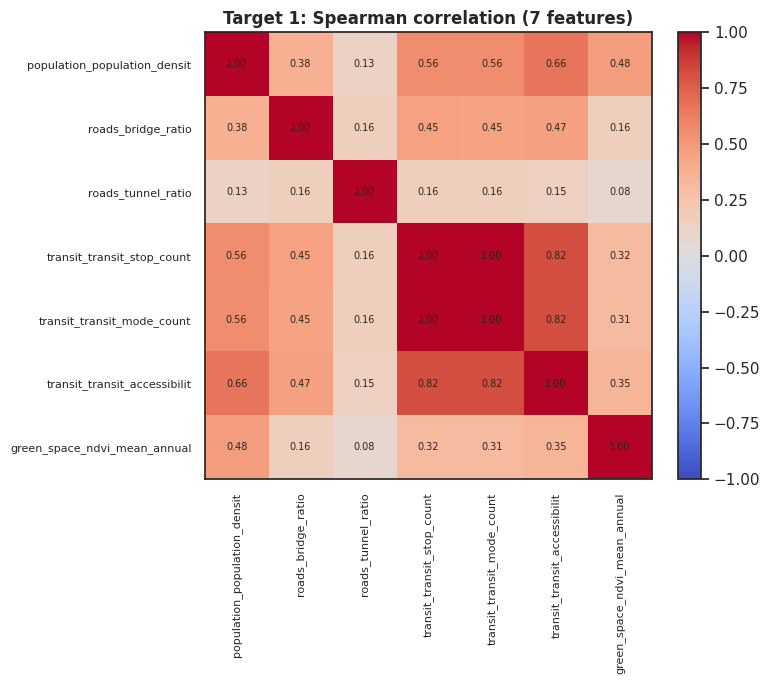


TARGET 3: urban_intervention_priority_class
Labeled rows: 3488 | number of input features: 66
Features (grouped by prefix):
transit    25
green      15
roads      13
traffic     7
air         6

Full feature list:
['roads_motorway_length_km', 'roads_trunk_length_km', 'roads_primary_road_length_km', 'roads_secondary_road_length_km', 'roads_tertiary_road_length_km', 'roads_residential_road_length_km', 'roads_service_road_length_km', 'roads_other_road_length_km', 'roads_oneway_ratio', 'roads_bridge_ratio', 'roads_tunnel_ratio', 'roads_lit_road_ratio', 'roads_maxspeed_coverage', 'traffic_motorway_trunk_length_km', 'traffic_primary_secondary_length_km', 'traffic_bridge_ratio', 'traffic_tunnel_ratio', 'traffic_oneway_ratio', 'traffic_bridge_ratio_norm', 'traffic_oneway_ratio_norm', 'transit_transit_stop_count', 'transit_metro_station_count', 'transit_light_rail_station_count', 'transit_rail_station_count', 'transit_brt_station_count', 'transit_bus_stop_count', 'transit_paratransit_stop_coun

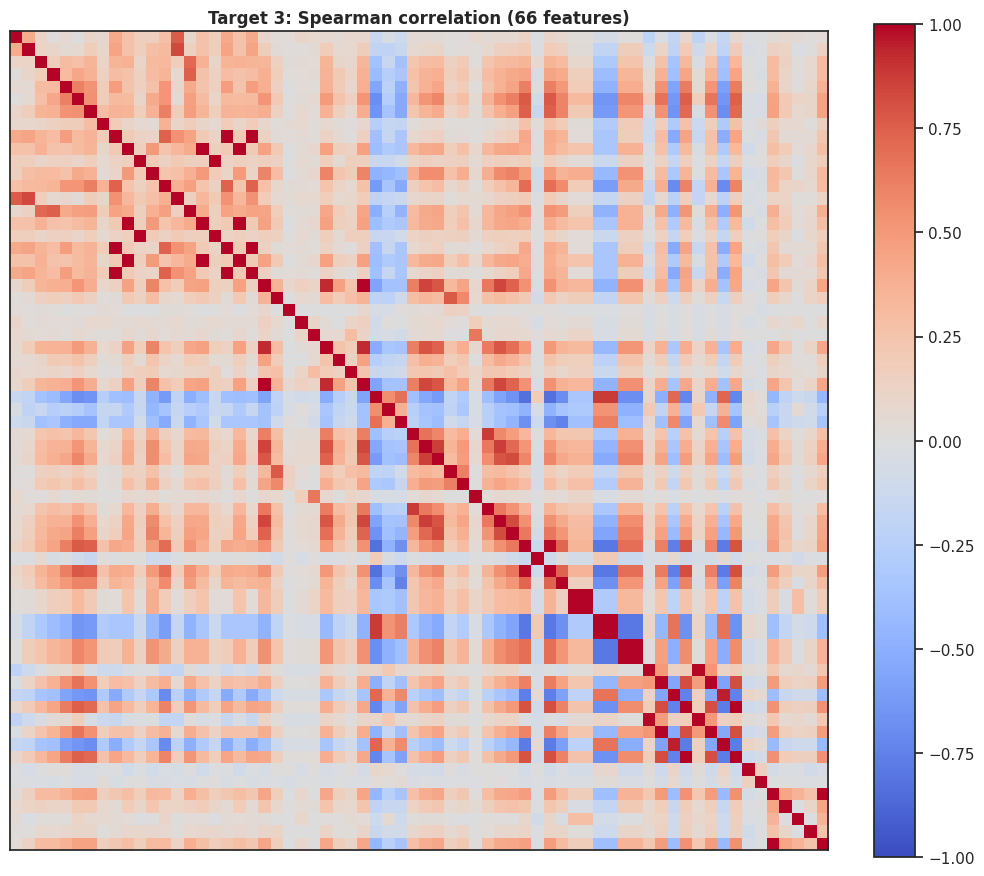


TARGET 2: traffic_demand_capacity_pressure_class
Labeled rows: 26 of 3489 | model trained: NO (deferred, insufficient labels)
traffic_demand_capacity_pressure_class
HIGH_DEMAND_CAPACITY_PRESSURE        9
LOW_DEMAND_CAPACITY_PRESSURE         9
MODERATE_DEMAND_CAPACITY_PRESSURE    8

RESULTS SUMMARY (values copied from earlier outputs, NOT recomputed in this cell)
                        model  n_features              evaluation  accuracy  macro_F1
 T1 initial (11 feats, leaky)          11            Random 80/20    0.9842       NaN
          T1 final (CatBoost)           7            Random 80/20    0.7507    0.7416
          T1 final (CatBoost)           7          Spatial 5-fold    0.7265    0.6781
T3 (CatBoost, with area cols)          69            Random 80/20    0.8252    0.8263
T3 (CatBoost, with area cols)          69          Spatial 5-fold    0.7397    0.6483
          T3 final (CatBoost)          66            Random 80/20    0.8181    0.8194
          T3 final (CatBoost)   

In [85]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/processed/urban_intervention_priority_dataset.csv")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)

def heatmap(corr, title, annot=False):
    fig, ax = plt.subplots(figsize=(8, 7) if annot else (10, 9))
    im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
    if annot:
        short = [c[:28] for c in corr.columns]
        ax.set_xticklabels(short, rotation=90, fontsize=8); ax.set_yticklabels(short, fontsize=8)
        for i in range(len(corr)):
            for j in range(len(corr)):
                ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    else:
        ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046); ax.set_title(title); plt.tight_layout(); plt.show()

# ===================== TARGET 1 =====================
t1 = "traffic_structural_susceptibility_class"
B = ["population_population_density_worldpop_2026", "roads_bridge_ratio", "roads_tunnel_ratio",
     "transit_transit_stop_count", "transit_transit_mode_count",
     "transit_transit_accessibility_score", "green_space_ndvi_mean_annual_2026"]
d1 = df[df[t1].notna()]
print("=" * 90); print("TARGET 1: traffic_structural_susceptibility_class"); print("=" * 90)
print(f"Labeled rows: {len(d1)} | number of input features: {len(B)}")
for f in B: print("  -", f)
print("\nClass distribution:"); print(d1[t1].value_counts().to_string())
c1 = d1[B].apply(pd.to_numeric, errors="coerce").corr(method="spearman")
print("\nSpearman correlation matrix (7 features):"); print(c1.round(2).to_string())
heatmap(c1, "Target 1: Spearman correlation (7 features)", annot=True)

# ===================== TARGET 3 =====================
score, cls = "urban_intervention_priority_score", "urban_intervention_priority_class"
score_inputs = ["traffic_intersection_density", "roads_dead_end_ratio",
                "transit_transit_accessibility_score", "green_space_public_green_space_fraction",
                "green_space_ndvi_mean_annual_2026", "air_quality_s5p_no2_tropospheric_column_mean_umol_m2"]
redundant = ["traffic_road_density_km_per_km2", "transit_transit_mode_count"]
kw = ["structural", "susceptib", "friction", "demand_capacity", "priority", "_available"]
geo_kw = ["longitude", "latitude", "_lon", "_lat", "lon_", "lat_"]
d3 = df[df[cls].notna()].copy().reset_index(drop=True)
drop = set(score_inputs) | set(redundant) | {"h3_index"}
drop |= {c for c in d3.columns if any(k in c.lower() for k in kw)}
drop |= {c for c in d3.columns if any(k in c.lower() for k in geo_kw) or c.lower() in ("lat", "lon")}
num = d3.select_dtypes(include="number").columns
cands = [c for c in num if c not in drop and d3[c].notna().mean() >= 0.95 and d3[c].nunique() > 1]
proxies = {c for c in cands for s in score_inputs if abs(d3[c].corr(d3[s], method="spearman")) >= 0.90}
safe3 = [c for c in cands if c not in proxies and "area_km2" not in c.lower()]

print("\n" + "=" * 90); print("TARGET 3: urban_intervention_priority_class"); print("=" * 90)
print(f"Labeled rows: {len(d3)} | number of input features: {len(safe3)}")
print("Features (grouped by prefix):")
print(pd.Series([c.split('_')[0] for c in safe3]).value_counts().to_string())
print("\nFull feature list:"); print(safe3)
print("\nClass distribution:"); print(d3[cls].value_counts().to_string())
c3 = d3[safe3].apply(pd.to_numeric, errors="coerce").corr(method="spearman")
iu = np.triu_indices(len(c3), k=1)
pairs = pd.DataFrame({"feature_a": c3.columns[iu[0]], "feature_b": c3.columns[iu[1]], "spearman": c3.values[iu]})
pairs["abs"] = pairs["spearman"].abs()
print(f"\nFeature pairs with |rho| >= 0.90: {(pairs['abs'] >= 0.90).sum()} | >= 0.80: {(pairs['abs'] >= 0.80).sum()} "
      f"| total pairs: {len(pairs)}")
print("\nTop 15 most correlated feature pairs:")
print(pairs.sort_values("abs", ascending=False).head(15).drop(columns="abs").round(3).to_string(index=False))
print("\nTop 10 features by |Spearman| with the priority score:")
rs = d3[safe3].apply(pd.to_numeric, errors="coerce").corrwith(d3[score], method="spearman")
print(rs.reindex(rs.abs().sort_values(ascending=False).index).head(10).round(3).to_string())
heatmap(c3, f"Target 3: Spearman correlation ({len(safe3)} features)")

# ===================== TARGET 2 =====================
t2 = "traffic_demand_capacity_pressure_class"
print("\n" + "=" * 90); print("TARGET 2: traffic_demand_capacity_pressure_class"); print("=" * 90)
print(f"Labeled rows: {df[t2].notna().sum()} of {len(df)} | model trained: NO (deferred, insufficient labels)")
print(df[t2].value_counts().to_string())

# ===================== RESULTS SUMMARY (copied from earlier steps) =====================
print("\n" + "=" * 90)
print("RESULTS SUMMARY (values copied from earlier outputs, NOT recomputed in this cell)")
print("=" * 90)
summary = pd.DataFrame([
    ["T1 initial (11 feats, leaky)", 11, "Random 80/20", 0.9842, None],
    ["T1 final (CatBoost)", 7, "Random 80/20", 0.7507, 0.7416],
    ["T1 final (CatBoost)", 7, "Spatial 5-fold", 0.7265, 0.6781],
    ["T3 (CatBoost, with area cols)", 69, "Random 80/20", 0.8252, 0.8263],
    ["T3 (CatBoost, with area cols)", 69, "Spatial 5-fold", 0.7397, 0.6483],
    ["T3 final (CatBoost)", 66, "Random 80/20", 0.8181, 0.8194],
    ["T3 final (CatBoost)", 66, "Spatial 5-fold", 0.7202, 0.6077],
    ["T2", 0, "Not trained (26 labels)", None, None],
], columns=["model", "n_features", "evaluation", "accuracy", "macro_F1"])
print(summary.to_string(index=False))

## Final Project Summary: UrbanMind AI

**Data:** 3,489 Cairo H3 cells, 175 original columns (177 in the exported dataset `urban_intervention_priority_dataset.csv`), combining road network, transit, population, green space, and air-quality indicators.

### Overview of the three targets

| Target | Model trained | Input features | Labeled rows | Main result |
|---|---|---|---|---|
| 1. Traffic structural susceptibility | Yes (CatBoost) | 7 | 3,488 | Spatial-CV macro-F1 ≈ 0.68 |
| 2. Traffic demand-capacity pressure | **No (deferred)** | n/a | 26 of 3,489 | Insufficient labels |
| 3. Urban intervention priority | Yes (CatBoost) | 66 | 3,488 | Spatial-CV macro-F1 ≈ 0.61–0.65 |

### Target 1: Structural susceptibility (LOW / MODERATE / HIGH)

- **Classes:** LOW 1,263, HIGH 1,151, MODERATE 1,074.
- **Features (7):** population density, bridge ratio, tunnel ratio, transit stop count, transit mode count, transit accessibility score, annual NDVI.
- **Correlations:** transit stop count and mode count are perfectly rank-correlated (ρ = 1.00) and both correlate 0.82 with the accessibility score; other pairs are weak to moderate (max 0.66, population density vs. accessibility).
- **Leakage finding:** the initial CatBoost model (11 road/transit/population/NDVI features) reached 98.42% accuracy, but those inputs reconstructed the friction index that defines the target (CV R² = 0.9955). Four road-structure features (road density, intersection density, dead-end ratio, one-way ratio) were removed. The 98.42% is kept for transparency only.
- **Final results:**

| Evaluation | Accuracy | Macro-F1 |
|---|---|---|
| Random 80/20 split | 0.7507 | 0.7416 |
| Spatial 5-fold (10 KMeans clusters) | 0.7265 | 0.6781 ± 0.071 |

- **Per-class F1 (random split):** HIGH 0.771, LOW 0.848, MODERATE 0.605. Errors occur mainly between adjacent classes.
- **Top features:** population density (63.7%), NDVI (19.6%), bridge ratio (8.9%).

### Target 2: Demand-capacity pressure (deferred)

Only 26 of 3,489 cells (0.75%) have a label (HIGH 9, LOW 9, MODERATE 8). The generation code is not available, so the cause of the missing values could not be established and labels were not imputed. **No model was trained.** Future work: recover the feature-engineering code, recompute the index, then train with spatial validation.

### Target 3: Urban intervention priority (LOW / MODERATE / HIGH)

- **Score:** equal-weight composite of six indicators (intersection density, dead-end ratio, transit accessibility, public green-space fraction, NDVI, NO2), Min-Max scaled with direction reversal, ≥5 of 6 required, scaled 0–100. Classes are tertiles (cutoffs ≈ 48.87 and 53.14): LOW 1,163, MODERATE 1,162, HIGH 1,163.
- **Model features (66):** transit 25, green space 15, roads 13, traffic 7, air quality 6. The six score inputs, 15 near-duplicates of them (|ρ| ≥ 0.90), coordinates, and target-related columns were excluded; cell-area columns were also removed in a robustness check.
- **Correlations:** 19 feature pairs have |ρ| ≥ 0.90 and 40 have ≥ 0.80 (of 2,145). Most are duplicated roads_/traffic_ columns, so the effective number of independent features is lower than 66.
- **Final results:**

| Evaluation | Accuracy | Macro-F1 |
|---|---|---|
| Random 80/20 split | 0.8181 | 0.8194 |
| Spatial 5-fold | 0.7202 | 0.6077 ± 0.093 |

With cell-area columns (69 features): random macro-F1 0.8263, spatial 0.6483 ± 0.050.

- **Top features:** nearest BRT station distance (21.1%), nearest transit stop distance (9.2%), nearest metro station distance (7.0%), service-road length (6.5%). These likely encode location relative to the transit network.
- **Sensitivity analysis:** mean Spearman vs. baseline under 1,000 random weightings = 0.83; mean class retention = 76% (range 33–90%); LOW↔HIGH jumps are rare (mean 2.3%). NO2 is the most influential indicator (dropping it changes ~40% of classes).

### Limitations

- Targets 1 and 3 are derived labels (threshold or quantile rules on computed indices), not independently observed outcomes; the models approximate these rules from other context.
- Residual indirect leakage cannot be excluded because features were screened by correlation, not by the original formulas.
- Spatial CV uses KMeans blocks of unequal size and a single seed; fold results vary notably across regions of Cairo.
- Target 3 classes are relative tiers within this dataset, not validated intervention categories; equal weights and Min-Max scaling are methodological choices.
- Feature importance is associative, not causal.